# HDB Rentals 1: EDA and preprocessing

Report section: Exploratory Data Analysis & Preprocessing. Run this notebook first: it writes the cleaned tables in `cleaned/` that later parts read.

## Part 1.1. HDB Rentals: EDA of `data/train.csv`

Target: `MONTHLY_RENT`. Train and test are consecutive periods, so read section 1 first. `data/test.csv` has no
target and is used only for its dates and feature distributions.

1. The problem: regression on a moving market, scored out-of-time
2. Structure: shape, dtypes, missingness, duplicates
3. `.describe()` for numeric and categorical columns
4. Data-quality issues
5. A cleaned analysis frame
6. Correlation
7. Time structure: hedonic market level, trend, seasonality, drift, validation scheme, forecasting the level
8. Encoding analysis
9. Distribution of every column
10. Summary

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import sparse, stats
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.model_selection import KFold, cross_val_predict
from sklearn.preprocessing import OneHotEncoder
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.stattools import adfuller

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110

DATA = Path("..") / "data" if Path("../data").exists() else Path("data")
TARGET = "MONTHLY_RENT"

train = pd.read_csv(DATA / "train.csv")
test = pd.read_csv(DATA / "test.csv")
print(f"train: {train.shape}   test: {test.shape}")
train.head()

train: (150000, 11)   test: (50000, 10)


,RENT_APPROVAL_DATE,TOWN,BLOCK,STREET,FLAT_TYPE,FLAT_MODEL,FLOOR_AREA_SQM,FURNISHED,LEASE_COMMENCE_DATE,FEE,MONTHLY_RENT
0,2021-01,punggol,604a,punggol road,4 room,model a,93.000,yes,2012,0.000,1800
1,2021-01,sengkang,290c,compassvale crescent,5 room,improved,110.000,yes,2001,0.000,2000
2,2021-01,queenstown,5,ghim moh road,3 room,improved,65.000,yes,1976,0.000,2000
3,2021-01,sengkang,436b,fernvale road,4 room,model a,96.000,yes,2010,0.000,1400
4,2021-01,sembawang,467b,admiralty drive,4 room,premium apartment,102.000,yes,2001,0.000,1800


### 1. The problem: regression on a moving market, scored out-of-time

Two facts define this problem before a single column is profiled.

In [2]:
# The split is temporal, not random -- the single most important fact about this dataset.
pd.DataFrame({
    name: {
        "first_month": df["RENT_APPROVAL_DATE"].min(),
        "last_month": df["RENT_APPROVAL_DATE"].max(),
        "n_months": df["RENT_APPROVAL_DATE"].nunique(),
        "rows_per_month": round(len(df) / df["RENT_APPROVAL_DATE"].nunique()),
    }
    for name, df in [("train", train), ("test", test)]
}).T

,first_month,last_month,n_months,rows_per_month
train,2021-01,2025-03,51,2941
test,2025-03,2026-07,17,2941


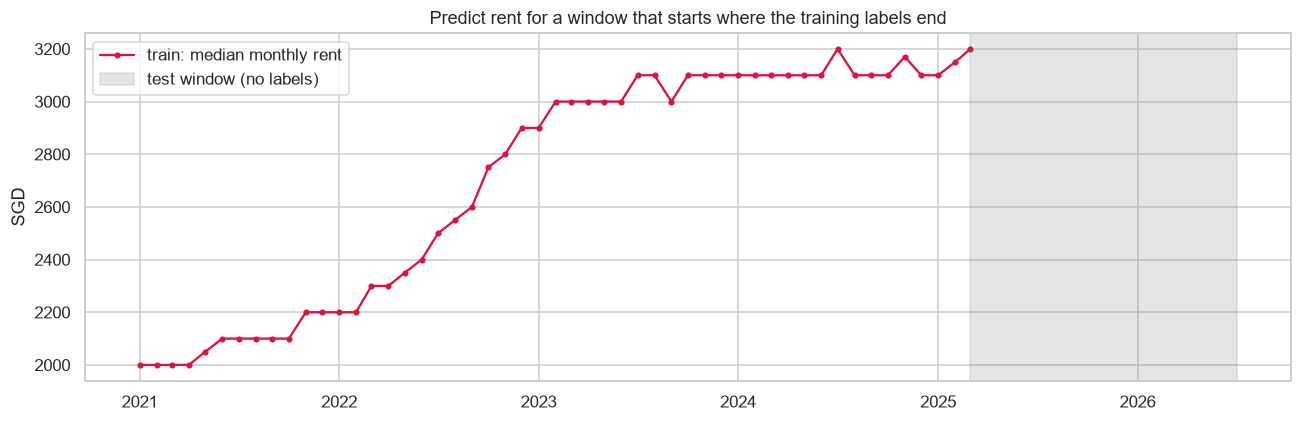

In [3]:
# The target level moves over time, and the test window starts where the labels stop.
raw_market = train.groupby(pd.to_datetime(train["RENT_APPROVAL_DATE"], format="%Y-%m"))[TARGET].median()
test_months = pd.to_datetime(test["RENT_APPROVAL_DATE"], format="%Y-%m")

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(raw_market.index, raw_market, marker="o", ms=3, color="crimson", label="train: median monthly rent")
ax.axvspan(test_months.min(), test_months.max(), color="grey", alpha=0.2, label="test window (no labels)")
ax.set_ylabel("SGD")
ax.set_title("Predict rent for a window that starts where the training labels end")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

1. **The split is temporal.** Train 2021-01 to 2025-03, test 2025-03 to 2026-07: up to 16 months past the last label.
2. **The target level moves.** Median rent climbed steeply through 2023, then flattened.

There is no flat ID and every row is a different rental, so there are no lags to forecast. But every scored
prediction is in the future. Section 7 shows the problem splits in two:

$$\text{rent} \approx \underbrace{\text{market level}(\text{month})}_{\text{time series: forecast up to 16 months ahead}} \times \underbrace{\text{relative premium}(\text{flat, location})}_{\text{cross-sectional: stable over time}}$$

- Validation must be time-ordered.
- Anything fitted on the target may only use earlier months.
- How the model extrapolates the level is a first-order decision.
- Month-of-year seasonality is negligible (7.2).

### 2. Structure, dtypes and missingness

Cardinality and example values per column, to assign a semantic type (drives section 8).

In [4]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 150000 entries, 0 to 149999
Data columns (total 11 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   RENT_APPROVAL_DATE   150000 non-null  str    
 1   TOWN                 150000 non-null  str    
 2   BLOCK                150000 non-null  str    
 3   STREET               150000 non-null  str    
 4   FLAT_TYPE            150000 non-null  str    
 5   FLAT_MODEL           150000 non-null  str    
 6   FLOOR_AREA_SQM       150000 non-null  float64
 7   FURNISHED            150000 non-null  str    
 8   LEASE_COMMENCE_DATE  150000 non-null  int64  
 9   FEE                  150000 non-null  float64
 10  MONTHLY_RENT         150000 non-null  int64  
dtypes: float64(2), int64(2), str(7)
memory usage: 12.6 MB


In [5]:
def column_profile(df: pd.DataFrame) -> pd.DataFrame:
    rows = []
    for c in df.columns:
        s = df[c]
        rows.append(
            {
                "dtype": str(s.dtype),
                "n_unique": s.nunique(),
                "unique_pct": 100 * s.nunique() / len(s),
                "n_missing": s.isna().sum(),
                "missing_pct": 100 * s.isna().mean(),
                "mem_mb": s.memory_usage(deep=True) / 1e6,
                "examples": ", ".join(map(str, s.dropna().unique()[:4])),
            }
        )
    return pd.DataFrame(rows, index=df.columns)


profile = column_profile(train)
profile

,dtype,n_unique,unique_pct,n_missing,missing_pct,mem_mb,examples
RENT_APPROVAL_DATE,str,51,0.034,0,0.000,9.600,"2021-01, 2021-02, 2021-03, 2021-04"
TOWN,str,26,0.017,0,0.000,9.913,"punggol, sengkang, queenstown, sembawang"
BLOCK,str,2720,1.813,0,0.000,8.998,"604a, 290c, 5, 436b"
STREET,str,1146,0.764,0,0.000,11.101,"punggol road, compassvale crescent, ghim moh r..."
FLAT_TYPE,str,11,0.007,0,0.000,9.475,"4 room, 5 room, 3 room, executive"
FLAT_MODEL,str,20,0.013,0,0.000,10.004,"model a, improved, premium apartment, new gene..."
FLOOR_AREA_SQM,float64,156,0.104,0,0.000,1.200,"93.0, 110.0, 65.0, 96.0"
FURNISHED,str,1,0.001,0,0.000,9.000,yes
LEASE_COMMENCE_DATE,int64,57,0.038,0,0.000,1.200,"2012, 2001, 1976, 2010"
FEE,float64,1,0.001,0,0.000,1.200,0.0


In [6]:
print("fully duplicated rows:", train.duplicated().sum())
print("duplicated ignoring the target:", train.drop(columns=[TARGET]).duplicated().sum())

# Same feature row, different rent -> irreducible noise; worth knowing before chasing a low error.
dupe_spread = (
    train.groupby(list(train.columns.drop(TARGET)), observed=True)[TARGET]
    .agg(["size", "min", "max", "std"])
    .query("size > 1")
)
print(f"\nfeature-identical groups: {len(dupe_spread):,}")
dupe_spread.sort_values("size", ascending=False).head(10)

fully duplicated rows: 425
duplicated ignoring the target: 15547

feature-identical groups: 13,434


,,,,,,,,,,size,min,max,std
RENT_APPROVAL_DATE,TOWN,BLOCK,STREET,FLAT_TYPE,FLAT_MODEL,FLOOR_AREA_SQM,FURNISHED,LEASE_COMMENCE_DATE,FEE,,,,
2025-01,queenstown,5,ghim moh road,3-room,improved,65.000,yes,1976,0.000,9,2600,3300,191.122
2024-04,queenstown,2,holland avenue,3-room,improved,65.000,yes,1974,0.000,8,2600,3500,335.344
2024-06,queenstown,11,holland drive,3-room,improved,65.000,yes,1975,0.000,7,2050,3500,502.257
2025-01,queenstown,4,holland close,3-room,improved,65.000,yes,1974,0.000,7,1000,3300,811.891
2022-01,queenstown,3,dover road,3-room,improved,65.000,yes,1975,0.000,6,1800,2650,288.097
2022-08,queenstown,6,holland close,3-room,improved,65.000,yes,1974,0.000,6,1800,3500,606.630
2021-03,clementi,330,clementi avenue 2,3 room,new generation,67.000,yes,1978,0.000,6,1650,2400,290.545
2021-08,clementi,702,west coast road,3 room,new generation,67.000,yes,1980,0.000,6,1400,2150,270.093
2021-12,toa payoh,157,lorong 1 toa payoh,3 room,improved,67.000,yes,1971,0.000,6,1200,2500,433.590


### 3. `.describe()`

Numeric and categorical columns are described separately: `describe(include="all")` mixes two different sets
of statistics into one table and is harder to read.

In [7]:
num_cols = train.select_dtypes(include="number").columns.tolist()
cat_cols = [c for c in train.columns if c not in num_cols]
print("numeric    :", num_cols)
print("categorical:", cat_cols)

train[num_cols].describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.99]).T

numeric    : ['FLOOR_AREA_SQM', 'LEASE_COMMENCE_DATE', 'FEE', 'MONTHLY_RENT']
categorical: ['RENT_APPROVAL_DATE', 'TOWN', 'BLOCK', 'STREET', 'FLAT_TYPE', 'FLAT_MODEL', 'FURNISHED']


,count,mean,std,min,1%,25%,50%,75%,99%,max
FLOOR_AREA_SQM,"150,000.000",93.339,24.272,31.000,47.000,68.000,92.000,110.000,149.000,215.000
LEASE_COMMENCE_DATE,"150,000.000","1,990.907",12.642,"1,966.000","1,968.000","1,981.000","1,988.000","2,001.000","2,018.000","2,022.000"
FEE,"150,000.000",0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
MONTHLY_RENT,"150,000.000","2,719.037",749.731,300.000,"1,300.000","2,100.000","2,700.000","3,200.000","4,600.000","7,600.000"


In [8]:
train[cat_cols].describe().T

,count,unique,top,freq
RENT_APPROVAL_DATE,150000,51,2021-03,3705
TOWN,150000,26,jurong west,10482
BLOCK,150000,2720,2,921
STREET,150000,1146,ang mo kio avenue 3,1590
FLAT_TYPE,150000,11,4-room,40688
FLAT_MODEL,150000,20,improved,44008
FURNISHED,150000,1,yes,150000


In [9]:
# Distribution shape of the numeric columns beyond mean/std.
pd.DataFrame(
    {
        "skew": train[num_cols].skew(),
        "kurtosis": train[num_cols].kurtosis(),
        "zeros": (train[num_cols] == 0).sum(),
        "cv": train[num_cols].std() / train[num_cols].mean(),
    }
)

,skew,kurtosis,zeros,cv
FLOOR_AREA_SQM,0.245,-0.541,0,0.260
LEASE_COMMENCE_DATE,0.355,-0.709,0,0.006
FEE,0.000,0.000,150000,NaN
MONTHLY_RENT,0.386,-0.062,0,0.276


### 4. Data-quality issues

Three things fall out of the profile above. Each one changes what we do downstream, so they are checked
explicitly rather than assumed.

In [10]:
# (a) Zero-variance columns carry no information and must not reach a model.
constant = [c for c in train.columns if train[c].nunique(dropna=False) <= 1]
for c in constant:
    print(f"{c:<12} constant in train = {train[c].unique()[0]!r} | in test = {test[c].unique()}")

FURNISHED    constant in train = 'yes' | in test = <StringArray>
['yes']
Length: 1, dtype: str
FEE          constant in train = np.float64(0.0) | in test = [0.]


In [11]:
# (b) FLAT_TYPE is spelled two ways -> 11 apparent levels for 6 real ones.
print(train["FLAT_TYPE"].value_counts(), "\n")
print("test spellings:", sorted(test["FLAT_TYPE"].unique()))

FLAT_TYPE
4-room       40688
3-room       36932
5-room       26215
4 room       13391
3 room       12092
5 room        9308
executive     8234
2-room        2566
2 room         532
1-room          34
1 room           8
Name: count, dtype: int64 

test spellings: ['1-room', '2-room', '3-room', '4-room', '5-room', 'executive']


In [12]:
# (c) STREET/BLOCK are inconsistently cased, which inflates cardinality the same way.
for c in ["STREET", "BLOCK"]:
    raw = train[c].nunique()
    low = train[c].str.strip().str.lower().nunique()
    print(f"{c:<7} raw={raw:>5}  lower-cased={low:>5}  ({raw - low} phantom levels)")

print("\nsample of the mixed casing:")
print(train.loc[~train["STREET"].str.islower(), "STREET"].drop_duplicates().head(5).tolist())

STREET  raw= 1146  lower-cased=  576  (570 phantom levels)
BLOCK   raw= 2720  lower-cased= 2720  (0 phantom levels)

sample of the mixed casing:
['Hougang Avenue 10', 'Admiralty Link', 'Hougang Avenue 6', 'Balam Road', 'Cantonment Road']


### 5. Cleaned analysis frame

Only the repairs justified above, plus the minimum feature derivation needed to correlate anything against
time and lease age. Nothing speculative; this is not the modelling feature set.

In [13]:
def clean(df: pd.DataFrame) -> pd.DataFrame:
    out = df.copy()

    text = out.select_dtypes(include="str").columns
    out[text] = out[text].apply(lambda s: s.str.strip().str.lower())

    # "4 room" and "4-room" are the same level.
    out["FLAT_TYPE"] = out["FLAT_TYPE"].str.replace(r"[\s\-]+", "-", regex=True)

    out["RENT_APPROVAL_DATE"] = pd.to_datetime(out["RENT_APPROVAL_DATE"], format="%Y-%m")
    out["APPROVAL_YEAR"] = out["RENT_APPROVAL_DATE"].dt.year
    out["APPROVAL_MONTH"] = out["RENT_APPROVAL_DATE"].dt.month
    # Months since the first month in train: a single monotone time index for correlation.
    out["MONTH_INDEX"] = (
        (out["RENT_APPROVAL_DATE"].dt.year - 2021) * 12 + out["RENT_APPROVAL_DATE"].dt.month - 1
    )

    out["FLAT_AGE"] = out["APPROVAL_YEAR"] - out["LEASE_COMMENCE_DATE"]
    out["REMAINING_LEASE"] = 99 - out["FLAT_AGE"]
    out["ADDRESS"] = out["BLOCK"] + " " + out["STREET"]

    return out.drop(columns=constant)


tr = clean(train)
te = clean(test)
print("dropped constant columns:", constant)
tr.head(3)

dropped constant columns: ['FURNISHED', 'FEE']


,RENT_APPROVAL_DATE,TOWN,BLOCK,STREET,FLAT_TYPE,FLAT_MODEL,FLOOR_AREA_SQM,LEASE_COMMENCE_DATE,MONTHLY_RENT,APPROVAL_YEAR,APPROVAL_MONTH,MONTH_INDEX,FLAT_AGE,REMAINING_LEASE,ADDRESS
0,2021-01-01,punggol,604a,punggol road,4-room,model a,93.000,2012,1800,2021,1,0,9,90,604a punggol road
1,2021-01-01,sengkang,290c,compassvale crescent,5-room,improved,110.000,2001,2000,2021,1,0,20,79,290c compassvale crescent
2,2021-01-01,queenstown,5,ghim moh road,3-room,improved,65.000,1976,2000,2021,1,0,45,54,5 ghim moh road


In [14]:
# How much of the test set is addressable by categories seen in train? Decides whether a high-cardinality
# encoder needs an unseen-category fallback.
for c in ["TOWN", "FLAT_TYPE", "FLAT_MODEL", "STREET", "BLOCK", "ADDRESS"]:
    seen = set(tr[c])
    unseen_rows = (~te[c].isin(seen)).sum()
    print(f"{c:<11} train levels={len(seen):>6}  test levels={te[c].nunique():>6}  "
          f"unseen levels={te[c].nunique() - te.loc[te[c].isin(seen), c].nunique():>4}  "
          f"affected test rows={unseen_rows:>5} ({100 * unseen_rows / len(te):.2f}%)")

TOWN        train levels=    26  test levels=    26  unseen levels=   0  affected test rows=    0 (0.00%)
FLAT_TYPE   train levels=     6  test levels=     6  unseen levels=   0  affected test rows=    0 (0.00%)
FLAT_MODEL  train levels=    20  test levels=    19  unseen levels=   0  affected test rows=    0 (0.00%)
STREET      train levels=   576  test levels=   573  unseen levels=   0  affected test rows=    0 (0.00%)
BLOCK       train levels=  2720  test levels=  2660  unseen levels=  11  affected test rows=   36 (0.07%)
ADDRESS     train levels=  9406  test levels=  8940  unseen levels=  50  affected test rows=  102 (0.20%)


### 6. Correlation

| pair | measure | range |
|---|---|---|
| numeric ↔ numeric | Pearson (linear) and Spearman (monotone) | −1 … 1 |
| categorical → numeric target | correlation ratio η | 0 … 1 |
| categorical ↔ categorical | Cramér's V | 0 … 1 |

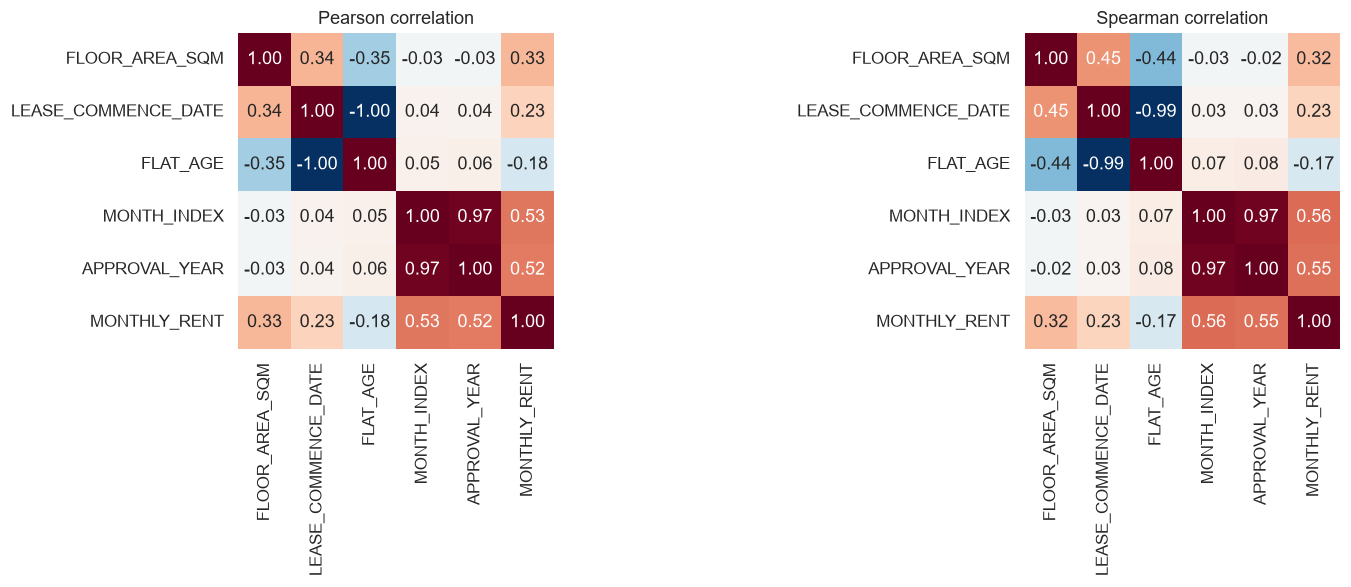

In [15]:
corr_cols = ["FLOOR_AREA_SQM", "LEASE_COMMENCE_DATE", "FLAT_AGE", "MONTH_INDEX", "APPROVAL_YEAR", TARGET]

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
for ax, method in zip(axes, ["pearson", "spearman"]):
    sns.heatmap(
        tr[corr_cols].corr(method=method), annot=True, fmt=".2f", cmap="RdBu_r",
        vmin=-1, vmax=1, square=True, cbar=False, ax=ax,
    )
    ax.set_title(f"{method.title()} correlation")
plt.tight_layout()
plt.show()

In [16]:
# REMAINING_LEASE is 99 - FLAT_AGE and FLAT_AGE is APPROVAL_YEAR - LEASE_COMMENCE_DATE, so several of these
# are exact linear combinations of each other. Only one of each group belongs in a linear model.
tr[corr_cols].corr()[TARGET].drop(TARGET).sort_values(key=abs, ascending=False).to_frame("pearson_vs_target")

,pearson_vs_target
MONTH_INDEX,0.535
APPROVAL_YEAR,0.517
FLOOR_AREA_SQM,0.329
LEASE_COMMENCE_DATE,0.229
FLAT_AGE,-0.178


In [17]:
def correlation_ratio(categories: pd.Series, values: pd.Series) -> float:
    # Eta: sqrt of the share of the target's variance explained by group membership.
    # 0 = the level tells you nothing about the target, 1 = the level determines it.
    # Equivalent to sqrt(R^2) of regressing the target on the one-hot levels -- i.e. what Pearson would give if it
    # could take a category. Pearson on label codes is not a substitute: it depends on an arbitrary level order.
    # pandas/scipy have no built-in for this.
    df = pd.DataFrame({"c": categories, "v": values}).dropna()
    grand_mean = df["v"].mean()
    grp = df.groupby("c", observed=True)["v"].agg(["size", "mean"])
    between = (grp["size"] * (grp["mean"] - grand_mean) ** 2).sum()
    total = ((df["v"] - grand_mean) ** 2).sum()
    return float(np.sqrt(between / total)) if total else 0.0


cat_features = ["TOWN", "FLAT_TYPE", "FLAT_MODEL", "STREET", "BLOCK", "ADDRESS", "APPROVAL_YEAR"]
eta = pd.DataFrame(
    {
        "n_levels": [tr[c].nunique() for c in cat_features],
        "eta_vs_rent": [correlation_ratio(tr[c], tr[TARGET]) for c in cat_features],
    },
    index=cat_features,
).sort_values("eta_vs_rent", ascending=False)
eta["eta_squared"] = eta["eta_vs_rent"] ** 2
eta

,n_levels,eta_vs_rent,eta_squared
ADDRESS,9406,0.549,0.302
APPROVAL_YEAR,5,0.547,0.299
STREET,576,0.380,0.145
FLAT_TYPE,6,0.368,0.135
BLOCK,2720,0.335,0.112
FLAT_MODEL,20,0.253,0.064
TOWN,26,0.195,0.038


η rises mechanically with the number of levels: a 9,406-level `ADDRESS` can chase noise in a way a 26-level
`TOWN` cannot. Compare each column against a permuted baseline: shuffle the labels and recompute η. Whatever
is left above that baseline is the real signal.

In [18]:
rng = np.random.default_rng(0)
rows = []
for c in cat_features:
    shuffled = np.mean([
        correlation_ratio(pd.Series(rng.permutation(tr[c].to_numpy())), tr[TARGET]) for _ in range(3)
    ])
    rows.append({"eta": correlation_ratio(tr[c], tr[TARGET]), "eta_if_shuffled": shuffled})
baseline = pd.DataFrame(rows, index=cat_features)
baseline["excess"] = baseline["eta"] - baseline["eta_if_shuffled"]
baseline.sort_values("excess", ascending=False)

,eta,eta_if_shuffled,excess
APPROVAL_YEAR,0.547,0.006,0.541
FLAT_TYPE,0.368,0.005,0.363
STREET,0.380,0.062,0.318
ADDRESS,0.549,0.250,0.300
FLAT_MODEL,0.253,0.012,0.241
BLOCK,0.335,0.134,0.201
TOWN,0.195,0.012,0.183


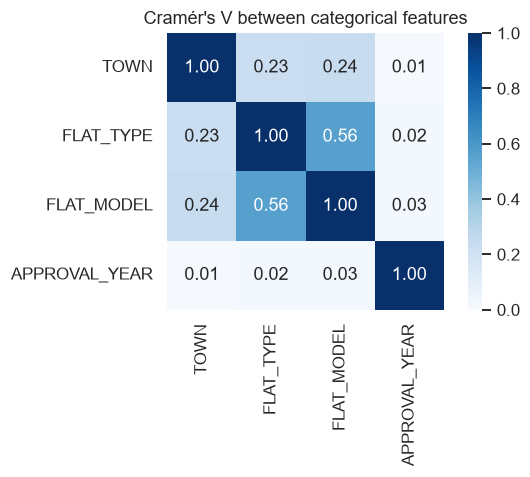

,TOWN,FLAT_TYPE,FLAT_MODEL,APPROVAL_YEAR
TOWN,1.000,0.226,0.244,0.014
FLAT_TYPE,0.226,1.000,0.562,0.020
FLAT_MODEL,0.244,0.562,1.000,0.025
APPROVAL_YEAR,0.014,0.020,0.025,1.000


In [19]:
# Restricted to the low-cardinality columns: a 9,406 x 2,720 contingency table is neither computable
# nor meaningful. With 150k rows, a small-sample bias correction changes V only in the 4th decimal.
low_card = ["TOWN", "FLAT_TYPE", "FLAT_MODEL", "APPROVAL_YEAR"]
cv = pd.DataFrame(
    [[stats.contingency.association(pd.crosstab(tr[a], tr[b]).to_numpy(), method="cramer") for b in low_card]
     for a in low_card],
    index=low_card, columns=low_card,
)

plt.figure(figsize=(6, 4.5))
sns.heatmap(cv, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, square=True)
plt.title("Cramér's V between categorical features")
plt.tight_layout()
plt.show()
cv

`FLAT_TYPE` and `FLAT_MODEL` are strongly associated (a maisonette is never a 2-room), and both are
associated with `FLOOR_AREA_SQM`. That redundancy matters for one-hot encoding: it produces collinear columns
that make linear-model coefficients unstable, though it is harmless for trees.

In [20]:
# The numeric side of that redundancy.
pd.DataFrame({
    "eta_vs_FLOOR_AREA": [correlation_ratio(tr[c], tr["FLOOR_AREA_SQM"]) for c in ["FLAT_TYPE", "FLAT_MODEL", "TOWN"]],
}, index=["FLAT_TYPE", "FLAT_MODEL", "TOWN"])

,eta_vs_FLOOR_AREA
FLAT_TYPE,0.954
FLAT_MODEL,0.610
TOWN,0.447


### 7. Time structure

**Main argument:** rent ≈ market level(month) × relative premium(flat, location).

1. The market level rose ~56% in two regimes, rapid growth then plateau, with no usable seasonality (7.1, 7.2).
2. The premiums around it are static (7.3).
3. So the whole gap between random K-fold and time-ordered validation is the market level (7.4, 7.5), and no simple
   rule extrapolates it safely across both regimes (7.6).

**Market level** = a hedonic index of monthly rent with the flat mix held fixed, in SGD (7.1). ~3,000 rows a month.

#### 7.1 The market level: two regimes

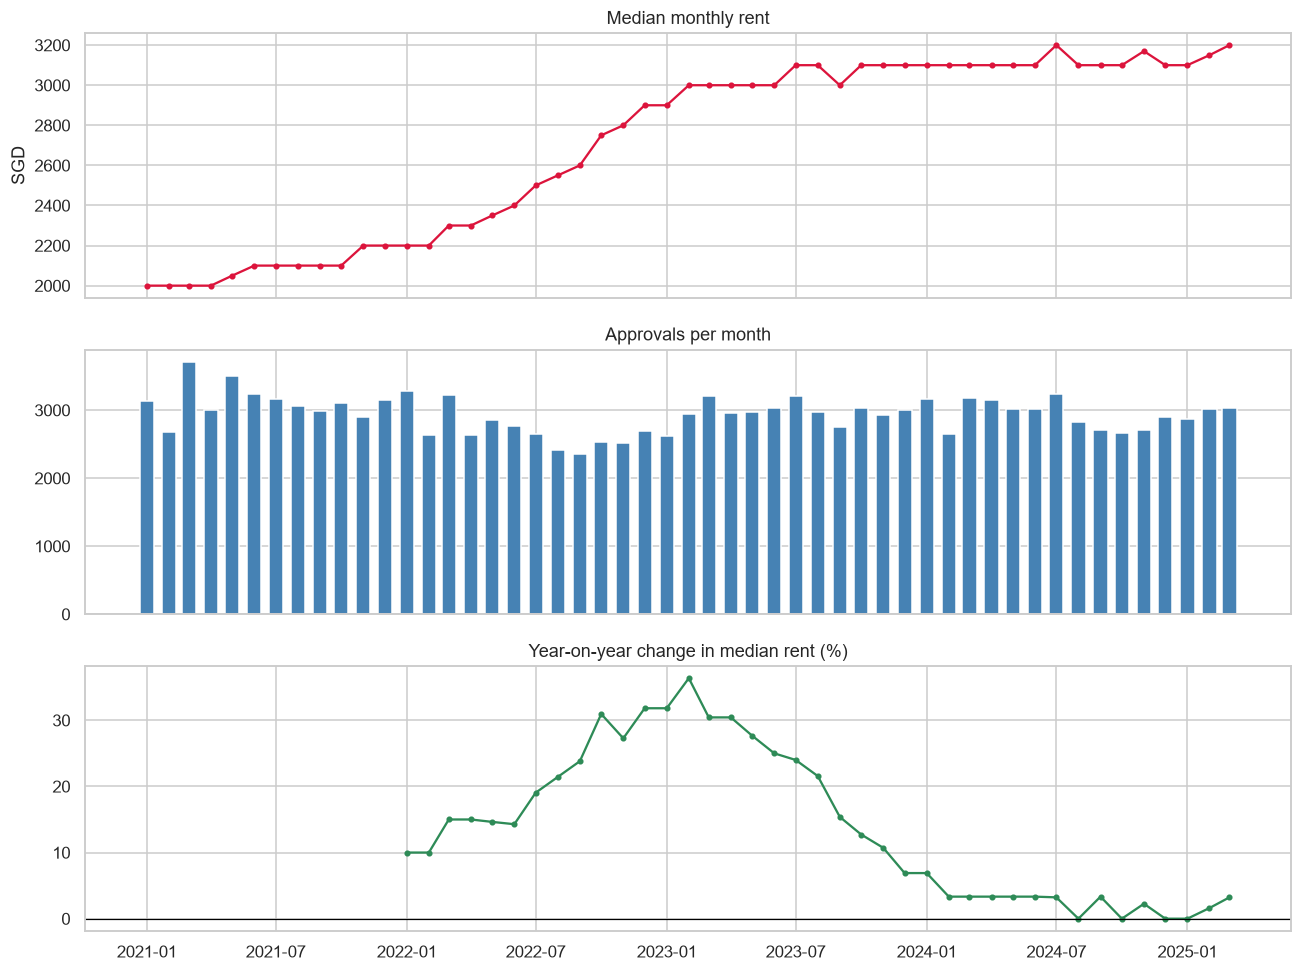

median rent 2,000 -> 3,200  (+60.0% across the training window)


In [21]:
monthly = tr.groupby("RENT_APPROVAL_DATE").agg(n=(TARGET, "size"), median_rent=(TARGET, "median")).asfreq("MS")
raw_median = monthly["median_rent"]

fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
axes[0].plot(raw_median.index, raw_median, marker="o", ms=3, color="crimson")
axes[0].set_title("Median monthly rent")
axes[0].set_ylabel("SGD")

axes[1].bar(monthly.index, monthly["n"], width=20, color="steelblue")
axes[1].set_title("Approvals per month")

yoy = 100 * raw_median.pct_change(12)
axes[2].plot(yoy.index, yoy, marker="o", ms=3, color="seagreen")
axes[2].axhline(0, c="black", lw=0.8)
axes[2].set_title("Year-on-year change in median rent (%)")
plt.tight_layout()
plt.show()

first, last = raw_median.iloc[0], raw_median.iloc[-1]
print(f"median rent {first:,.0f} -> {last:,.0f}  ({100 * (last / first - 1):+.1f}% across the training window)")

In [22]:
# Rent per sqm moves the same way, so the rise is a price change, not a shift towards bigger flats.
yearly = tr.groupby("APPROVAL_YEAR").agg(n=(TARGET, "size"), median_rent=(TARGET, "median"))
yearly["growth_%"] = 100 * yearly["median_rent"].pct_change()
yearly["median_rent_per_sqm"] = (tr[TARGET] / tr["FLOOR_AREA_SQM"]).groupby(tr["APPROVAL_YEAR"]).median()
yearly

,n,median_rent,growth_%,median_rent_per_sqm
APPROVAL_YEAR,,,,
2021,37619,"2,100.000",NaN,22.826
2022,32564,"2,450.000",16.667,27.174
2023,35654,"3,000.000",22.449,33.036
2024,35239,"3,100.000",3.333,34.286
2025,8924,"3,150.000",1.613,34.444


- **2021 to 2023: rapid growth.** +17%, then +22% a year; year-on-year growth peaked above 30%.
- **2024 to 2025-03: plateau.** +3%, then flat.

A straight line through `MONTH_INDEX` fits neither regime.

Rents sit on a 50-SGD grid, so the raw median moves in steps, and it also moves with the mix of flats rented each
month. A hedonic index fixes both.

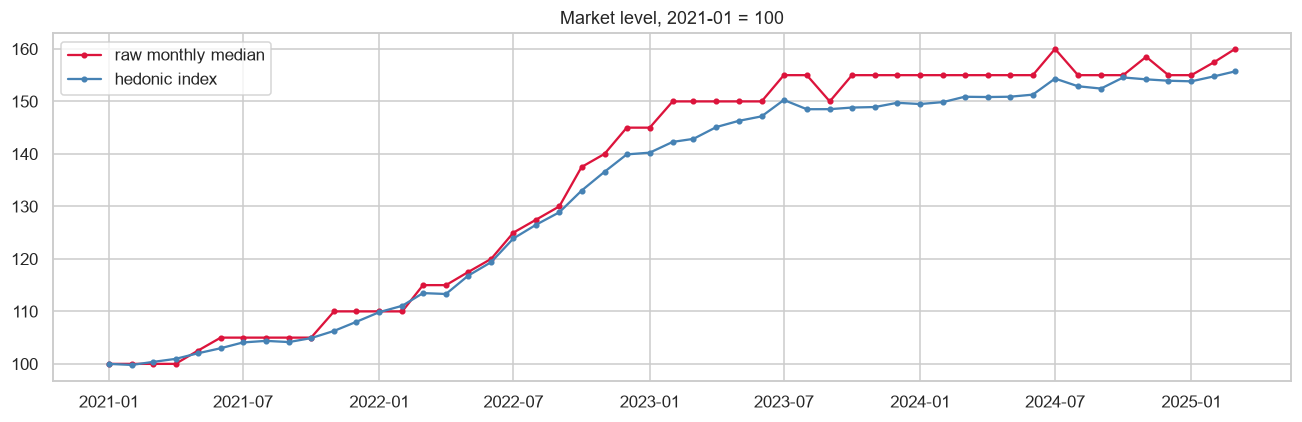

share_of_rents_multiple_of_50    0.987
hedonic_r2                       0.552
rise_raw_median_pct             60.000
rise_hedonic_pct                55.719
distinct_values_raw             18.000
distinct_values_hedonic         50.000
dtype: float64

In [23]:
# Time-dummy hedonic index: log(rent) on flat and location attributes plus one dummy per month. The month
# coefficients are the market level with the flat mix held fixed.
attr = OneHotEncoder(drop="first", sparse_output=True).fit_transform(tr[["TOWN", "FLAT_TYPE", "FLAT_MODEL", "STREET"]])
month_dummies = OneHotEncoder(drop="first", sparse_output=True).fit_transform(tr[["MONTH_INDEX"]])
X_hedonic = sparse.hstack([attr, sparse.csr_matrix(tr[["FLOOR_AREA_SQM", "FLAT_AGE"]].to_numpy(float)), month_dummies]).tocsr()
hedonic_fit = LinearRegression().fit(X_hedonic, np.log(tr[TARGET]))
hedonic = pd.Series(np.r_[0.0, hedonic_fit.coef_[-month_dummies.shape[1]:]], index=raw_median.index)  # log, 2021-01 = 0
# In SGD, scaled so its log mean matches the raw median's. This is the market level for the rest of section 7.
market = np.exp(hedonic - hedonic.mean() + np.log(raw_median).mean())

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(raw_median.index, 100 * raw_median / raw_median.iloc[0], color="crimson", marker="o", ms=3, label="raw monthly median")
ax.plot(hedonic.index, 100 * np.exp(hedonic), color="steelblue", marker="o", ms=3, label="hedonic index")
ax.set_title("Market level, 2021-01 = 100")
ax.legend()
plt.tight_layout()
plt.show()

pd.Series({
    "share_of_rents_multiple_of_50": (tr[TARGET] % 50 == 0).mean(),
    "hedonic_r2": hedonic_fit.score(X_hedonic, np.log(tr[TARGET])),
    "rise_raw_median_pct": 100 * (raw_median.iloc[-1] / raw_median.iloc[0] - 1),
    "rise_hedonic_pct": 100 * (np.exp(hedonic.iloc[-1]) - 1),
    "distinct_values_raw": raw_median.nunique(),
    "distinct_values_hedonic": hedonic.round(4).nunique(),
})

Continuous, with the flat mix held fixed. It rises ~56% against +60% for the raw median: about 4 points of the
headline rise was flat mix. The plateau is not flat either: +4% from 2023-12 to 2025-03, hidden by the grid.

**`market` is this index for the rest of Part 1.1.** It is fitted once on all of train, so its attribute coefficients see later
months: a mild leak in 7.5 and 7.6. Refit it per validation origin when modelling.

#### 7.2 Trend, seasonality and stationarity

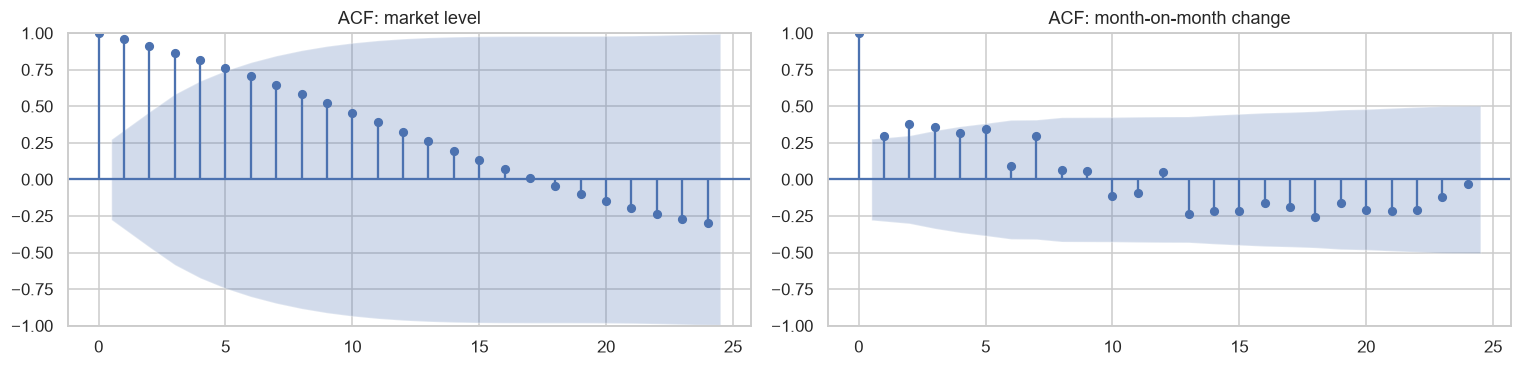

,adf_statistic,p_value
level,-1.579,0.494
month-on-month change,-2.065,0.259


In [24]:
# A slowly decaying ACF on the level = trend-dominated, non-stationary. The differenced series should show a spike
# at lag 12 if there were real seasonality.
fig, axes = plt.subplots(1, 2, figsize=(14, 3.5))
plot_acf(market, lags=24, ax=axes[0], title="ACF: market level")
plot_acf(market.diff().dropna(), lags=24, ax=axes[1], title="ACF: month-on-month change")
plt.tight_layout()
plt.show()

pd.DataFrame(
    [adfuller(s, autolag="AIC", result_object=False)[:2] for s in [market, market.diff().dropna()]],
    index=["level", "month-on-month change"], columns=["adf_statistic", "p_value"],
)

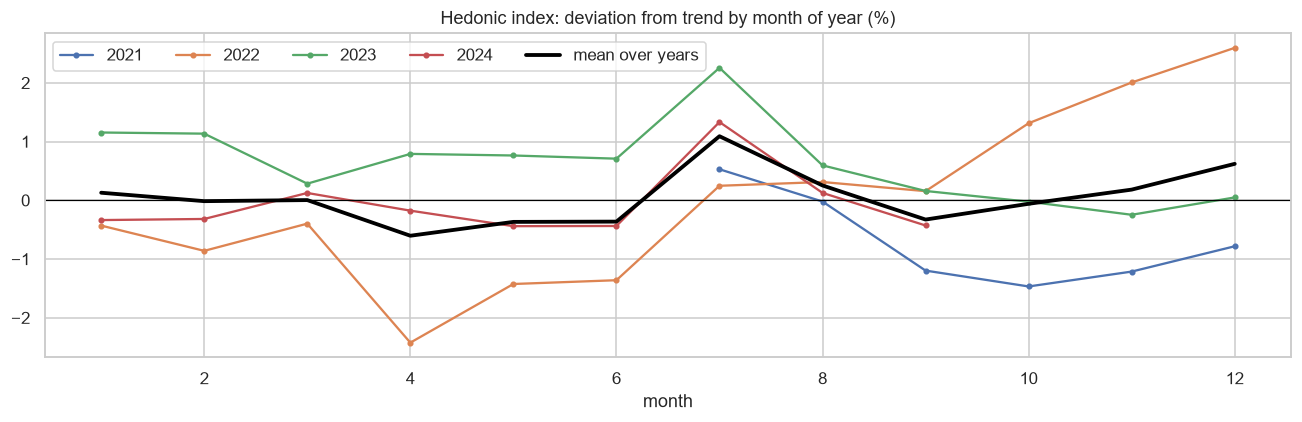

months used: 39 (2021-07 to 2024-09)
peak-to-trough of mean month effects: 1.69%  (about SGD 54 at the last level)
month-level F-test: F=0.62, p=0.793
leave-one-year-out correlation (other years' effects vs held-out year):
2021    0.350
2022   -0.510
2023   -0.060
2024    0.740


In [25]:
# Month-of-year effects on the hedonic index. Detrend with a centred 2x12 moving average (loses 6 months at each
# end), then ask the only question that matters with four cycles: does one year's pattern predict another's?
ma = hedonic.rolling(12, center=True).mean()
detrended = (hedonic - (ma + ma.shift(-1)) / 2).dropna()
by_year = pd.DataFrame({"year": detrended.index.year, "month": detrended.index.month, "dev": 100 * detrended.to_numpy()})
effects = by_year.groupby("month")["dev"].mean()

fig, ax = plt.subplots(figsize=(12, 4))
for year, grp in by_year.groupby("year"):
    ax.plot(grp["month"], grp["dev"], marker="o", ms=3, label=str(year))
ax.plot(effects.index, effects, color="black", lw=2.5, label="mean over years")
ax.axhline(0, c="black", lw=0.8)
ax.set_title("Hedonic index: deviation from trend by month of year (%)")
ax.set_xlabel("month")
ax.legend(ncol=5)
plt.tight_layout()
plt.show()

loyo = {}
for year, grp in by_year.groupby("year"):
    others = by_year[by_year["year"] != year].groupby("month")["dev"].mean()
    held = grp.set_index("month")["dev"]
    loyo[year] = np.corrcoef(others[held.index], held)[0, 1]

# Month-level F-test: 39 months in 12 groups. This is the honest sample size for a month-of-year effect, because
# rows in the same month share one market shock.
f_stat, p_val = stats.f_oneway(*[g["dev"].to_numpy() for _, g in by_year.groupby("month")])
print(f"months used: {len(detrended)} ({detrended.index[0]:%Y-%m} to {detrended.index[-1]:%Y-%m})")
print(f"peak-to-trough of mean month effects: {np.ptp(effects):.2f}%  (about SGD {np.ptp(effects) / 100 * market.iloc[-1]:.0f} at the last level)")
print(f"month-level F-test: F={f_stat:.2f}, p={p_val:.3f}")
print("leave-one-year-out correlation (other years' effects vs held-out year):")
print(pd.Series(loyo).round(2).to_string())

- **Trend dominates.** ACF ≈ 0.96 at lag 1.
- **Not stationary.** ADF cannot reject a unit root, even for monthly changes (low power: 51 points, one regime change).
- **No usable seasonality.** Peak-to-trough ~1.7% (about SGD 54). Leave-one-year-out correlations: +0.35, −0.51,
  −0.06, +0.74. Month-level F-test: p ≈ 0.79.
- July is above trend in all four years (~1.1%), but that was found post hoc with n = 4.

**Do not model month-of-year.**

#### 7.3 Premiums over the market level are static

No flat ID, so these are repeated cross-sections, not a panel: a flat's own past rent is not available. Streets, flat
types and towns do repeat. If their premiums are stable *in relative terms*, rent is the market level multiplied by a
time-invariant shape.

In [26]:
months_per_address = tr.groupby("ADDRESS")["RENT_APPROVAL_DATE"].nunique()
print("distinct months per address (25/50/75%):", months_per_address.quantile([0.25, 0.5, 0.75]).to_dict())

# Relative rent = rent / that month's market level. A street's premium is its median relative rent in a quarter.
relative_rent = tr[TARGET] / tr["RENT_APPROVAL_DATE"].map(market)
street_quarter = (
    pd.DataFrame({"STREET": tr["STREET"], "QUARTER": tr["RENT_APPROVAL_DATE"].dt.to_period("Q"), "rel": relative_rent})
    .groupby(["STREET", "QUARTER"])["rel"].agg(["median", "size"])
    .query("size >= 20")["median"]  # quarters with too few rows give a noisy premium
    .unstack()
)
next_quarter_r = pd.Series({
    f"{a} -> {b}": street_quarter[[a, b]].dropna().corr().iloc[0, 1]
    for a, b in zip(street_quarter.columns[:-1], street_quarter.columns[1:])
})
first_last_r = street_quarter.iloc[:, [0, -1]].dropna().corr().iloc[0, 1]
print(f"street premium, quarter vs next quarter : mean r = {next_quarter_r.mean():.2f} (min {next_quarter_r.min():.2f})")
print(f"street premium, first vs last quarter   : r = {first_last_r:.2f}")

distinct months per address (25/50/75%): {0.25: 7.0, 0.5: 12.0, 0.75: 18.0}
street premium, quarter vs next quarter : mean r = 0.83 (min 0.74)
street premium, first vs last quarter   : r = 0.85


In [27]:
# Flat-type median rent as a multiple of the 4-room median, per year. Absolute gaps widen as the market rises;
# the question is whether the ratios do.
flat_year = tr.pivot_table(index="APPROVAL_YEAR", columns="FLAT_TYPE", values=TARGET, aggfunc="median")
flat_year.div(flat_year["4-room"], axis=0)

FLAT_TYPE,1-room,2-room,3-room,4-room,5-room,executive
APPROVAL_YEAR,,,,,,
2021,0.545,0.682,0.841,1.000,1.023,1.045
2022,0.520,0.716,0.880,1.000,1.080,1.120
2023,0.594,0.719,0.844,1.000,1.062,1.094
2024,0.515,0.697,0.848,1.000,1.061,1.091
2025,0.545,0.697,0.848,1.000,1.061,1.121


In [28]:
town_year = tr.pivot_table(index="TOWN", columns="APPROVAL_YEAR", values=TARGET, aggfunc="median")
town_premium = town_year / town_year.median()  # town median as a multiple of the median town, per year
print(f"town ranking, 2021 vs 2024: Spearman = {stats.spearmanr(town_year[2021], town_year[2024])[0]:.2f}")

premium_change = (town_premium[2024] - town_premium[2021]).sort_values().to_frame("premium_change_2021_to_2024")
pd.concat([premium_change.head(3), premium_change.tail(3)])

town ranking, 2021 vs 2024: Spearman = 0.89


,premium_change_2021_to_2024
TOWN,
bukit timah,-0.115
bukit merah,-0.115
bishan,-0.084
sembawang,-0.013
sengkang,-0.006
punggol,0.018


- **Streets:** the first and last quarter, four years apart, correlate as highly as adjacent quarters.
- **Flat types:** ratios stay within ~7 points of 2021 while the market rose ~50%.
- **Towns:** ranking Spearman ≈ 0.9. Exception: central older towns (Bukit Timah, Bukit Merah, Bishan) lost 8 to 12
  points of premium, a second-order town × time interaction.

**Premiums can be encoded statically; only the market level moves.**

#### 7.4 Random K-fold vs. time-ordered validation

Same simple model, same rows, scored two ways:

- **random 5-fold:** the model sees later months
- **time split:** trained on earlier years only, as the test set requires

In [29]:
X = pd.DataFrame({
    "MONTH_INDEX": tr["MONTH_INDEX"],
    "FLOOR_AREA_SQM": tr["FLOOR_AREA_SQM"],
    "FLAT_AGE": tr["FLAT_AGE"],
    # Level names sort in size order ("1-room" ... "5-room", "executive"), so sorted codes are ordinal.
    "FLAT_TYPE": tr["FLAT_TYPE"].map({t: i for i, t in enumerate(sorted(tr["FLAT_TYPE"].unique()))}),
    "TOWN": tr["TOWN"].astype("category").cat.codes,
    "FLAT_MODEL": tr["FLAT_MODEL"].astype("category").cat.codes,
})
y = tr[TARGET]


def make_model():
    return HistGradientBoostingRegressor(categorical_features=["TOWN", "FLAT_MODEL"], max_iter=300, random_state=0)


random_pred = pd.Series(
    cross_val_predict(make_model(), X, y, cv=KFold(5, shuffle=True, random_state=0)), index=tr.index
)

rows = []
for year in [2022, 2023, 2024]:
    past, this = tr["APPROVAL_YEAR"] < year, tr["APPROVAL_YEAR"] == year
    time_pred = make_model().fit(X[past], y[past]).predict(X[this])
    rows.append({
        "year": year,
        "random_cv_mae": (random_pred[this] - y[this]).abs().mean(),
        "time_split_mae": np.abs(time_pred - y[this]).mean(),
        "random_cv_bias": (random_pred[this] - y[this]).mean(),
        "time_split_bias": (time_pred - y[this]).mean(),
    })
validation = pd.DataFrame(rows).set_index("year")
validation["random_cv_optimism_%"] = 100 * (validation["time_split_mae"] / validation["random_cv_mae"] - 1)
validation

,random_cv_mae,time_split_mae,random_cv_bias,time_split_bias,random_cv_optimism_%
year,,,,,
2022,397.604,475.529,-1.512,-310.516,19.599
2023,487.778,519.730,0.119,-128.433,6.550
2024,368.887,380.293,-0.942,-38.566,3.092


- **Random K-fold is optimistic in every year.**
- **It hides bias.** Mean error is ~0 under K-fold; under the time split the model systematically under-predicts.
- **The penalty scales with how far the market moves after the cutoff**, which is unknown for the test window.

#### 7.5 Where the gap comes from

Fit **relative rent** (rent ÷ market level) with no time feature on earlier years, then convert back to SGD with:

- the **true** level of the predicted year (an oracle), or
- the **last known** level (median of the final 3 training months).

In [30]:
X_static = X.drop(columns="MONTH_INDEX")

rows = []
for year in [2022, 2023, 2024]:
    past, this = tr["APPROVAL_YEAR"] < year, tr["APPROVAL_YEAR"] == year
    rel_pred = make_model().fit(X_static[past], relative_rent[past]).predict(X_static[this])
    true_level = tr.loc[this, "RENT_APPROVAL_DATE"].map(market)
    last_known_level = market[market.index < f"{year}-01-01"].iloc[-3:].mean()
    rows.append({
        "year": year,
        "static_model_x_true_level_mae": np.abs(rel_pred * true_level - y[this]).mean(),
        "random_cv_mae": validation.loc[year, "random_cv_mae"],
        "static_model_x_last_known_level_mae": np.abs(rel_pred * last_known_level - y[this]).mean(),
        "time_split_mae": validation.loc[year, "time_split_mae"],
    })
pd.DataFrame(rows).set_index("year")

,static_model_x_true_level_mae,random_cv_mae,static_model_x_last_known_level_mae,time_split_mae
year,,,,
2022,401.181,397.604,485.432,475.529
2023,492.986,487.778,545.833,519.730
2024,369.589,368.887,379.579,380.293


With the true level, the time-blind model scores within ~1% of random K-fold; with the last known level it lands
within ~5% of the time split. **The whole validation gap is the market level.**

Floor: even with the level known exactly, MAE stays around SGD 370 to 490.

#### 7.6 Forecasting the market level

Since the market level is the crux, compare simple ways of extrapolating it. Fit on 2021–2023, forecast
2024-01 … 2025-03 (15 months, close to the 16-month test horizon).

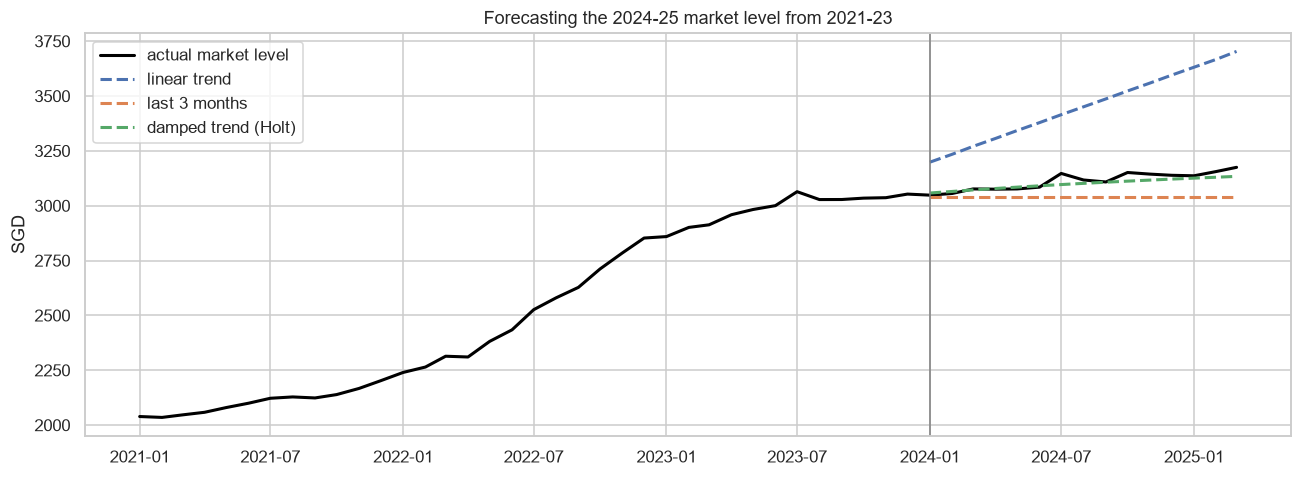

,mae,bias,forecast_at_2025_03
linear trend,338.208,338.208,"3,703.254"
last 3 months,71.386,-71.386,"3,041.216"
damped trend (Holt),18.001,-13.161,"3,133.661"


In [31]:
fit_part, holdout = market[:"2023-12"], market["2024-01":]
horizon = len(holdout)
future_steps = np.arange(len(fit_part), len(fit_part) + horizon)

forecasts = pd.DataFrame({
    "linear trend": np.polyval(np.polyfit(np.arange(len(fit_part)), fit_part.to_numpy(), 1), future_steps),
    "last 3 months": fit_part.iloc[-3:].mean(),
    "damped trend (Holt)": ExponentialSmoothing(fit_part, trend="add", damped_trend=True).fit().forecast(horizon).to_numpy(),
}, index=holdout.index)

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(market.index, market, c="black", lw=2, label="actual market level")
for name in forecasts:
    ax.plot(forecasts.index, forecasts[name], ls="--", lw=2, label=name)
ax.axvline(pd.Timestamp("2024-01-01"), c="grey", lw=1)
ax.set_ylabel("SGD")
ax.set_title("Forecasting the 2024-25 market level from 2021-23")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

errors = forecasts.sub(holdout, axis=0)
pd.DataFrame({"mae": errors.abs().mean(), "bias": errors.mean(), "forecast_at_2025_03": forecasts.iloc[-1]})

In [32]:
# The model family makes this choice implicitly. A linear model extends MONTH_INDEX as a straight line; a tree
# ensemble cannot extrapolate and holds the last level it saw.
past, future = tr["APPROVAL_YEAR"] < 2024, tr["APPROVAL_YEAR"] >= 2024
X_onehot = pd.get_dummies(X, columns=["TOWN", "FLAT_MODEL"], drop_first=True, dtype=float)

ridge_err = Ridge(alpha=1.0).fit(X_onehot[past], y[past]).predict(X_onehot[future]) - y[future]
tree_err = make_model().fit(X[past], y[past]).predict(X[future]) - y[future]
pd.DataFrame({
    "ridge (straight-line time)": [ridge_err.abs().mean(), ridge_err.mean()],
    "gradient boosting (holds last level)": [tree_err.abs().mean(), tree_err.mean()],
}, index=["mae", "bias"]).T

,mae,bias
ridge (straight-line time),500.439,388.590
gradient boosting (holds last level),375.923,-46.580


A linear 2021 to 2023 trend overshoots the plateau by ~SGD 340, and ridge on `MONTH_INDEX` inherits that. The damped
trend is closest (MAE ~SGD 18). Holding the last level under-predicts by ~SGD 70, because the hedonic level kept
creeping up through 2024 (7.1). It is that close **only because the market flattened**: the same behaviour
under-predicted by ~SGD 300 in 2022 (7.4). One origin, so this is not a ranking of methods.

The level assumption for the test window is an explicit decision to justify and stress-test.

#### 7.7 Train vs test feature drift

The test months all come after the train months, so a feature whose distribution shifts over time will be shifted
in the test set too.

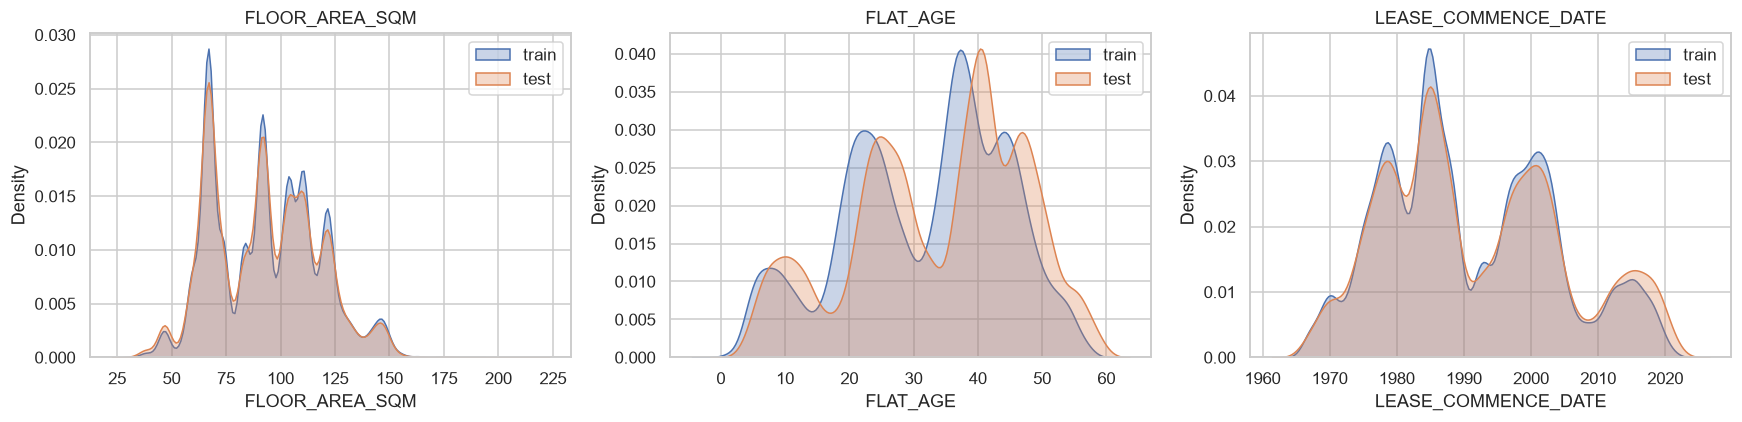

,train_%,test_%,diff
FLAT_TYPE,,,
1-room,0.028,0.024,-0.004
2-room,2.065,2.872,0.807
3-room,32.683,32.850,0.167
4-room,36.053,36.090,0.037
5-room,23.682,23.060,-0.622
executive,5.489,5.104,-0.385


In [33]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, c in zip(axes, ["FLOOR_AREA_SQM", "FLAT_AGE", "LEASE_COMMENCE_DATE"]):
    sns.kdeplot(tr[c], ax=ax, label="train", fill=True, alpha=0.3)
    sns.kdeplot(te[c], ax=ax, label="test", fill=True, alpha=0.3)
    ax.set_title(c)
    ax.legend()
plt.tight_layout()
plt.show()

comp = pd.DataFrame({
    "train_%": 100 * tr["FLAT_TYPE"].value_counts(normalize=True),
    "test_%": 100 * te["FLAT_TYPE"].value_counts(normalize=True),
}).sort_index()
comp["diff"] = comp["test_%"] - comp["train_%"]
comp

No material drift: floor area and lease year overlap, and flat-type shares move by under 1 point. `FLAT_AGE` shifts
up by about 2 years only because the test months are later.

#### 7.8 Verdict

**A cross-sectional regression whose evaluation is a forecast.**

| part | behaves like | implication |
|---|---|---|
| relative premium | supervised learning (7.3, 7.5) | static encodings, fitted on earlier months only |
| market level | time series, up to 16 months ahead (7.1, 7.2) | a level assumption for the test window, stated and stress-tested |
| evaluation | out-of-time (7.4, 7.5) | time-ordered validation; report bias as well as MAE |

Rules out: random K-fold, target encoding on the full training set.

**Keep `MONTH_INDEX` in tree models, and know what it does.** A tree sends every month after the cutoff to the leaf of
the last training month, so it holds the market level where training ended (7.6). For the test window that is the
bet that rent stays at its early-2025 level through 2026-07. Write that down, report bias on every fold, and
stress-test it, e.g. by rescaling predictions ±3% and ±5%.

COE premiums and share prices do not replace `MONTH_INDEX`: in time-ordered folds they act as a noisy clock, never
clearly beat it, and many placebo series do as well on the plateau.

### 8. Encoding analysis

The deciding factors are cardinality, whether the levels have an inherent order, and how much of the test set
sits on levels never seen in train.

In [34]:
def one_hot_cost(df, cols):
    rows = []
    for c in cols:
        k = df[c].nunique()
        vc = df[c].value_counts()
        rows.append({
            "n_levels": k,
            "ohe_columns": k - 1,           
            "rows_per_level": len(df) / k,
            "levels_under_50_rows": int((vc < 50).sum()),
            "rarest_level_rows": int(vc.min()),
            "top_level_share_%": 100 * vc.iloc[0] / len(df),
        })
    return pd.DataFrame(rows, index=cols)


one_hot_cost(tr, ["TOWN", "FLAT_TYPE", "FLAT_MODEL", "STREET", "BLOCK", "ADDRESS", "APPROVAL_MONTH"])

,n_levels,ohe_columns,rows_per_level,levels_under_50_rows,rarest_level_rows,top_level_share_%
TOWN,26,25,"5,769.231",0,438,6.988
FLAT_TYPE,6,5,"25,000.000",1,42,36.053
FLAT_MODEL,20,19,"7,500.000",4,1,29.339
STREET,576,575,260.417,86,2,1.343
BLOCK,2720,2719,55.147,1946,1,0.614
ADDRESS,9406,9405,15.947,9181,1,0.091
APPROVAL_MONTH,12,11,"12,500.000",0,10803,10.900


#### Verdict per column

| column | levels | encoding |
|---|---|---|
| `TOWN` | 26 | one-hot |
| `FLAT_MODEL` | 20 | one-hot; fold levels under 50 rows (`premium maisonette`, `terrace`, `3gen`, `improved maisonette`) into `other` |
| `FLAT_TYPE` | 6 | ordinal integer; 5-room and executive tie on median rent |
| `STREET` | 576 | target or frequency encoding |
| `ADDRESS` | 9,406 | smoothed target encoding, or join block coordinates and encode as geography; 50 levels unseen in test |
| `BLOCK` | 2,720 | drop; meaningless without its street |
| `LEASE_COMMENCE_DATE` | 57 | numeric (or `FLAT_AGE`) |
| `RENT_APPROVAL_DATE` | 51 | numeric `MONTH_INDEX`; one-hot cannot reach the test months |
| `APPROVAL_MONTH` | 12 | sin/cos at most; expect nothing (7.2) |
| `FURNISHED`, `FEE` | 1 | drop |

In [35]:
# FLAT_TYPE is ordinal, and the target confirms the order is monotone -- so an integer map is defensible.
FLAT_TYPE_ORDER = ["1-room", "2-room", "3-room", "4-room", "5-room", "executive"]
FLAT_TYPE_MAP = {t: i for i, t in enumerate(FLAT_TYPE_ORDER, start=1)}

check = (
    tr.groupby("FLAT_TYPE", observed=True)
    .agg(n=(TARGET, "size"), median_rent=(TARGET, "median"), median_sqm=("FLOOR_AREA_SQM", "median"))
    .reindex(FLAT_TYPE_ORDER)
)
check["ordinal_code"] = check.index.map(FLAT_TYPE_MAP)
check

,n,median_rent,median_sqm,ordinal_code
FLAT_TYPE,,,,
1-room,42,"1,450.000",31.000,1
2-room,3098,"2,100.000",47.000,2
3-room,49024,"2,350.000",67.000,3
4-room,54079,"2,800.000",93.000,4
5-room,35523,"3,000.000",118.000,5
executive,8234,"3,000.000",144.000,6


In [36]:
# APPROVAL_MONTH is cyclical: December and January are adjacent, which neither an integer nor a one-hot
# column expresses. Two columns instead of eleven.
month_cyc = pd.DataFrame({
    "MONTH_SIN": np.sin(2 * np.pi * tr["APPROVAL_MONTH"] / 12),
    "MONTH_COS": np.cos(2 * np.pi * tr["APPROVAL_MONTH"] / 12),
})
month_cyc.head(3)

,MONTH_SIN,MONTH_COS
0,0.500,0.866
1,0.500,0.866
2,0.500,0.866


In [37]:
# Frequency encoding: cheap, one column, no target leakage, works for any cardinality. Useful as a baseline
# for STREET/ADDRESS before reaching for target encoding.
freq_street = tr["STREET"].map(tr["STREET"].value_counts(normalize=True))
print("STREET frequency encoding ->", freq_street.describe()[["min", "50%", "max"]].to_dict())

# Target encoding, done wrong (fit on the full training set) leaks the target into rare levels.
naive = tr.groupby("ADDRESS", observed=True)[TARGET].mean()
counts = tr["ADDRESS"].value_counts()
print(f"\naddresses with a single row: {(counts == 1).sum():,} "
      f"({100 * (counts == 1).mean():.1f}% of levels) -- for those, the naive encoding IS the target")

STREET frequency encoding -> {'min': 1.3333333333333333e-05, '50%': 0.0029733333333333335, 'max': 0.013426666666666667}

addresses with a single row: 247 (2.6% of levels) -- for those, the naive encoding IS the target


In [38]:
# Smoothed target encoding, as an illustration (fitted on all rows). m controls how hard a rare level is pulled toward the
# global mean. The unseen-level fallback is the global mean.
def smoothed_target_encode(train_s, target_s, m=20):
    prior = target_s.mean()
    agg = target_s.groupby(train_s, observed=True).agg(["count", "mean"])
    return ((agg["count"] * agg["mean"] + m * prior) / (agg["count"] + m)), prior


mapping, prior = smoothed_target_encode(tr["ADDRESS"], tr[TARGET], m=20)
pd.DataFrame({
    "raw_mean": tr.groupby("ADDRESS", observed=True)[TARGET].mean(),
    "n": tr["ADDRESS"].value_counts(),
    "smoothed": mapping,
}).sort_values("n").head(5)

,raw_mean,n,smoothed
ADDRESS,,,
609c tampines north drive 1,"3,350.000",1,"2,749.083"
131b canberra crescent,"2,850.000",1,"2,725.273"
131c canberra crescent,"3,500.000",1,"2,756.226"
612a tampines north drive 1,"3,000.000",1,"2,732.416"
359 yishun ring road,"2,700.000",1,"2,718.130"


> **Temporal split:** fit target encodings only on months strictly before the rows they encode. A random K-fold
> encoding leaks future rent levels (median rent rose ~60%) and flatters CV.

### 9. Distribution of every column

#### 9.1 Target

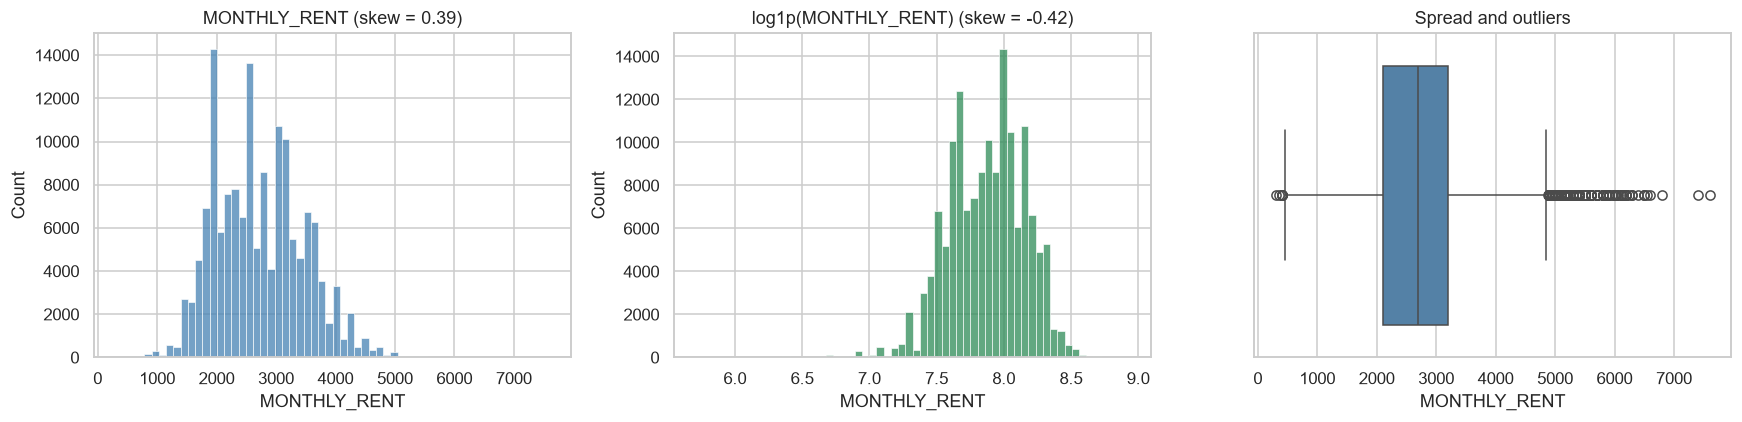

0.001     724.975
0.010   1,300.000
0.500   2,700.000
0.990   4,600.000
0.999   5,400.000

rent is discretised: 608 distinct values, 98.7% are multiples of 50


In [39]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(tr[TARGET], bins=60, ax=axes[0], color="steelblue")
axes[0].set_title(f"{TARGET} (skew = {tr[TARGET].skew():.2f})")

sns.histplot(np.log1p(tr[TARGET]), bins=60, ax=axes[1], color="seagreen")
axes[1].set_title(f"log1p({TARGET}) (skew = {np.log1p(tr[TARGET]).skew():.2f})")

sns.boxplot(x=tr[TARGET], ax=axes[2], color="steelblue")
axes[2].set_title("Spread and outliers")
plt.tight_layout()
plt.show()

q = tr[TARGET].quantile([0.001, 0.01, 0.5, 0.99, 0.999])
print(q.to_string())
print(f"\nrent is discretised: {tr[TARGET].nunique()} distinct values, "
      f"{100 * (tr[TARGET] % 50 == 0).mean():.1f}% are multiples of 50")

#### 9.2 Numeric columns

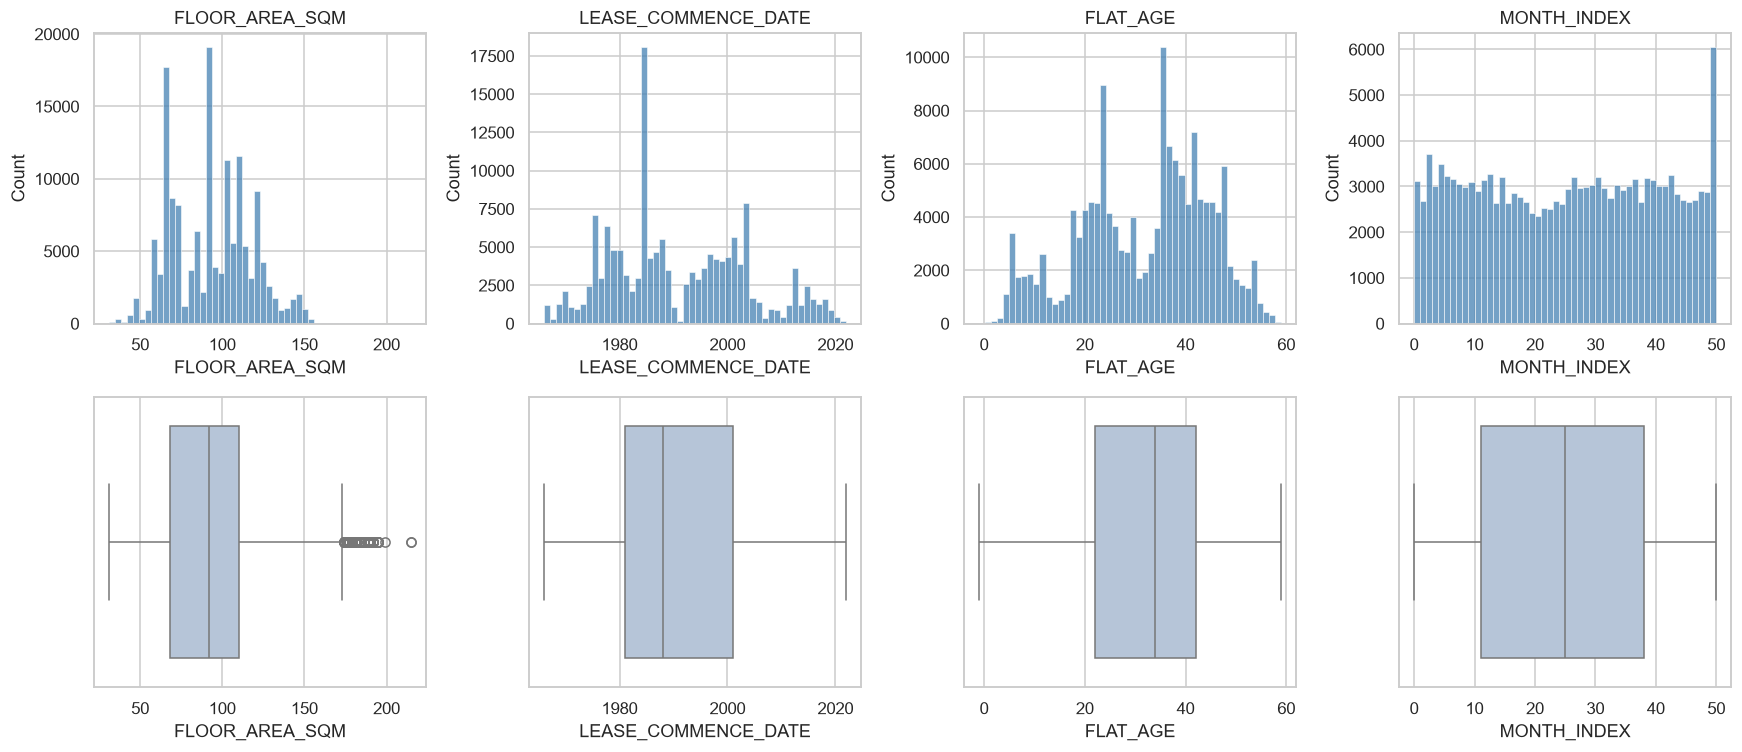

In [40]:
plot_num = ["FLOOR_AREA_SQM", "LEASE_COMMENCE_DATE", "FLAT_AGE", "MONTH_INDEX"]

fig, axes = plt.subplots(2, len(plot_num), figsize=(4 * len(plot_num), 7))
for i, c in enumerate(plot_num):
    sns.histplot(tr[c], bins=50, ax=axes[0, i], color="steelblue")
    axes[0, i].set_title(c)
    sns.boxplot(x=tr[c], ax=axes[1, i], color="lightsteelblue")
    axes[1, i].set_xlabel(c)
plt.tight_layout()
plt.show()

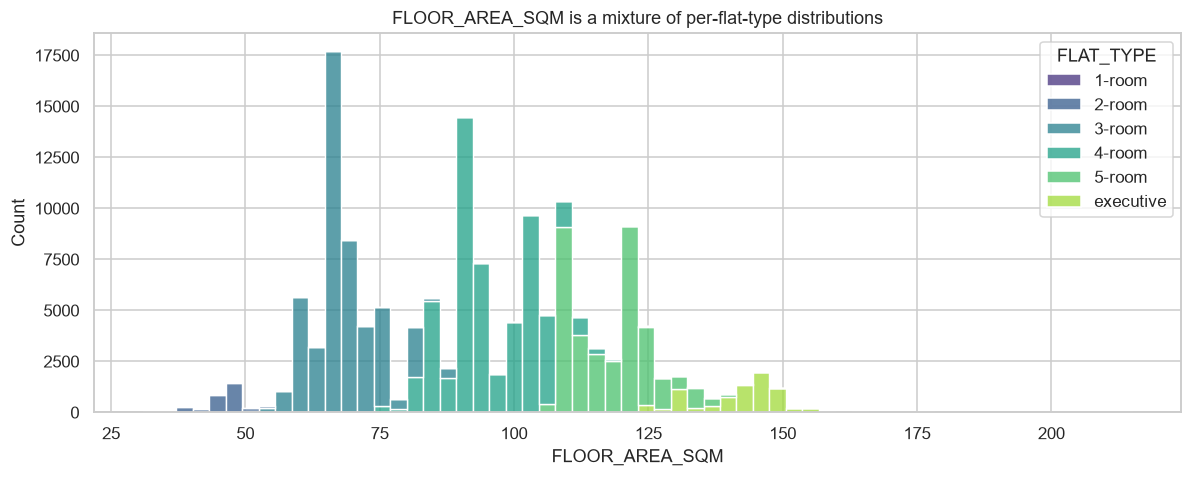

In [41]:
# FLOOR_AREA_SQM is multi-modal because it is really a proxy for flat type -- worth seeing the split.
plt.figure(figsize=(11, 4.5))
sns.histplot(
    tr, x="FLOOR_AREA_SQM", hue="FLAT_TYPE", bins=60, multiple="stack",
    hue_order=FLAT_TYPE_ORDER, palette="viridis",
)
plt.title("FLOOR_AREA_SQM is a mixture of per-flat-type distributions")
plt.tight_layout()
plt.show()

#### 9.3 Categorical columns

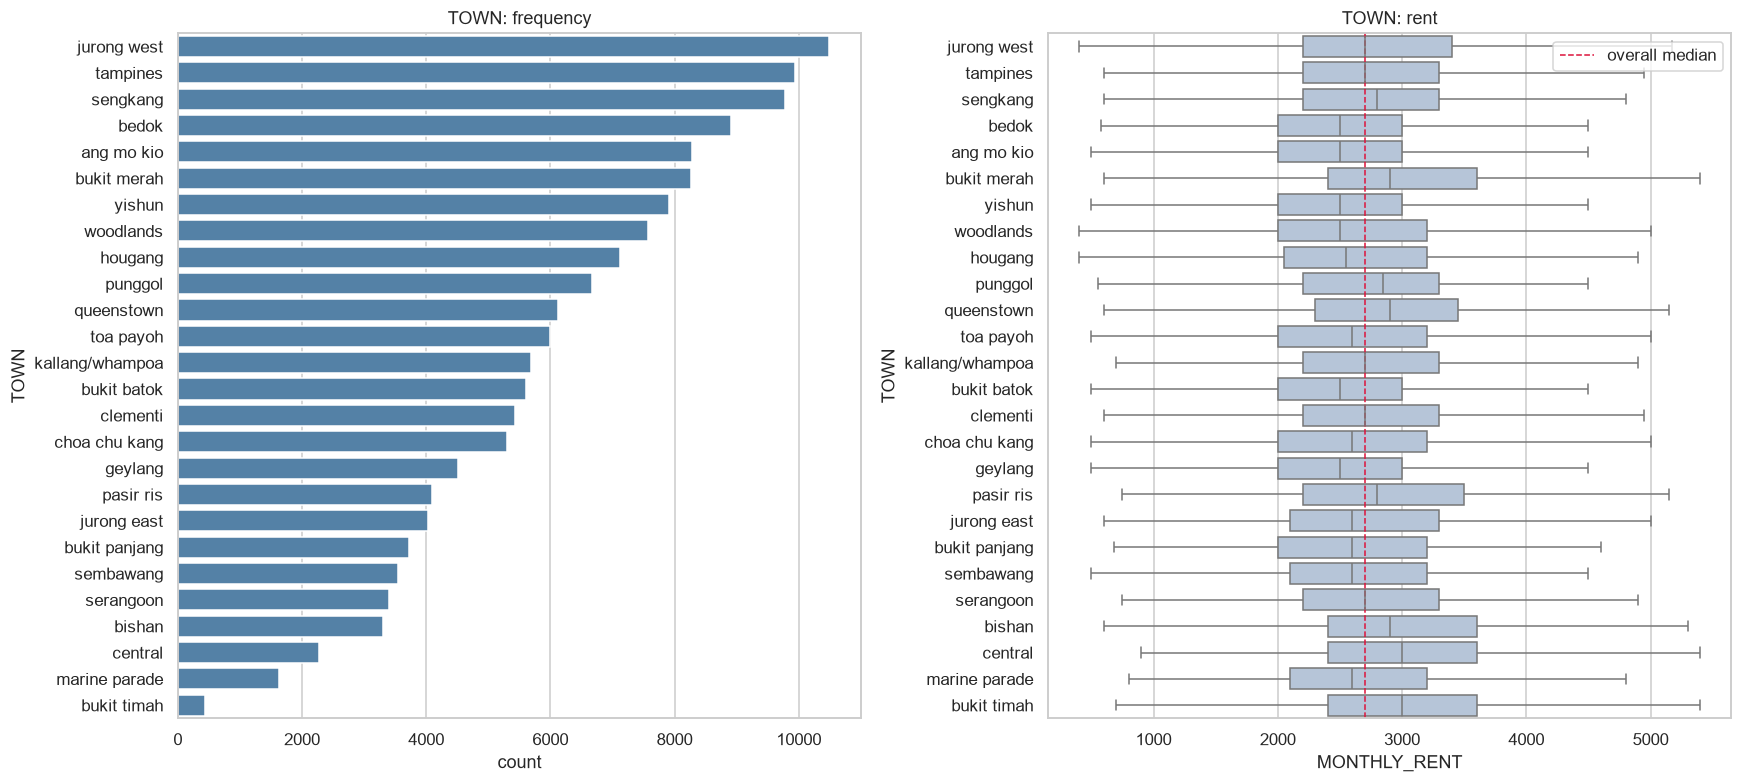

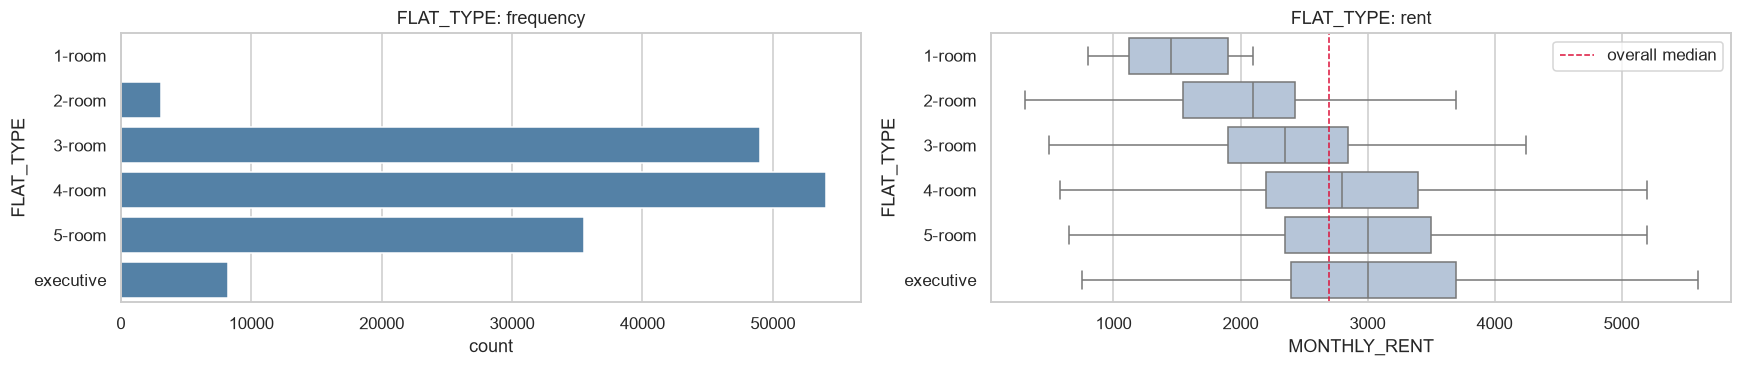

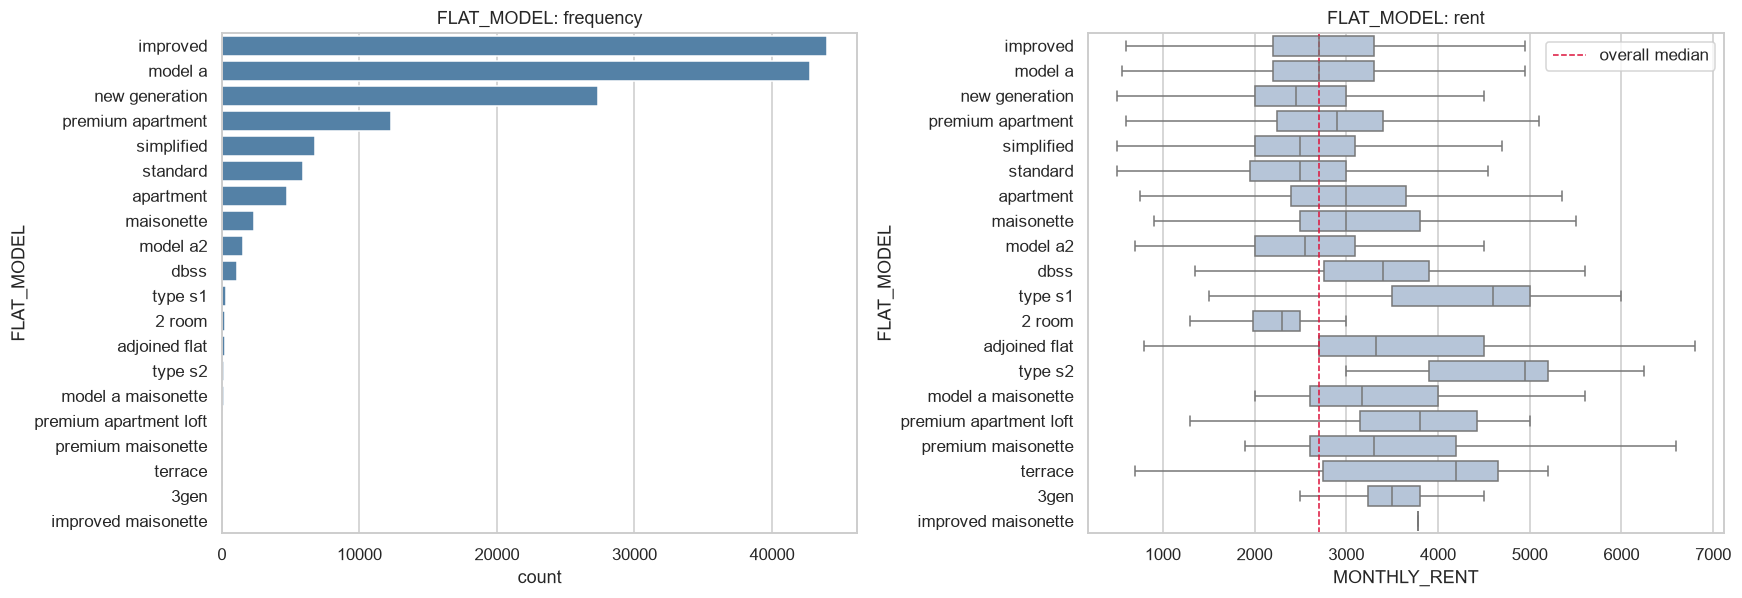

In [42]:
for c in ["TOWN", "FLAT_TYPE", "FLAT_MODEL"]:
    order = FLAT_TYPE_ORDER if c == "FLAT_TYPE" else tr[c].value_counts().index
    fig, axes = plt.subplots(1, 2, figsize=(16, max(3.5, 0.28 * tr[c].nunique())))

    sns.countplot(y=tr[c], order=order, ax=axes[0], color="steelblue")
    axes[0].set_title(f"{c}: frequency")

    sns.boxplot(data=tr, y=c, x=TARGET, order=order, ax=axes[1], color="lightsteelblue", showfliers=False)
    axes[1].axvline(tr[TARGET].median(), ls="--", c="crimson", lw=1, label="overall median")
    axes[1].set_title(f"{c}: rent")
    axes[1].legend()
    plt.tight_layout()
    plt.show()

In [43]:
# Rare levels: these are the ones to fold into "other" before one-hot encoding.
for c in ["FLAT_MODEL", "TOWN"]:
    vc = tr[c].value_counts()
    rare = vc[vc < 50]
    print(f"{c}: {len(rare)} level(s) with <50 rows -> {rare.to_dict()}")

FLAT_MODEL: 4 level(s) with <50 rows -> {'premium maisonette': 21, 'terrace': 19, '3gen': 12, 'improved maisonette': 1}
TOWN: 0 level(s) with <50 rows -> {}


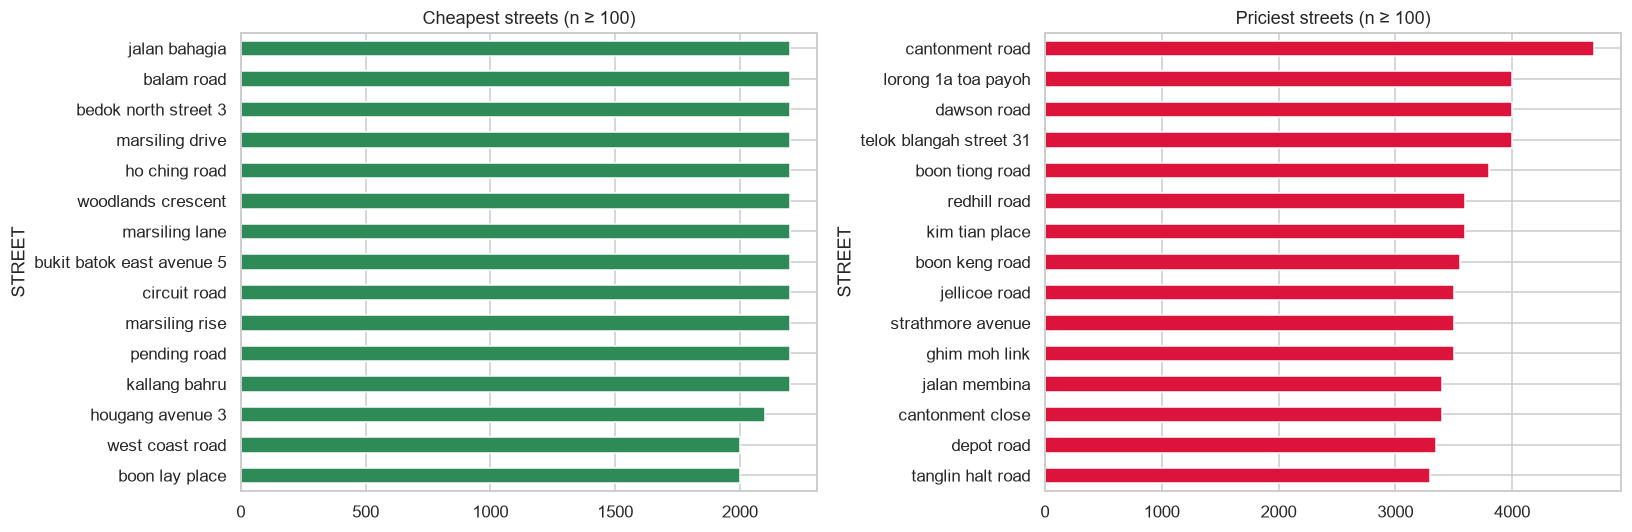

In [44]:
# Highest- and lowest-rent streets: the geographic signal that a target encoder would pick up.
street_stats = (
    tr.groupby("STREET", observed=True)
    .agg(n=(TARGET, "size"), median_rent=(TARGET, "median"))
    .query("n >= 100")
    .sort_values("median_rent")
)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
street_stats.head(15)["median_rent"].plot.barh(ax=axes[0], color="seagreen")
axes[0].set_title("Cheapest streets (n ≥ 100)")
street_stats.tail(15)["median_rent"].plot.barh(ax=axes[1], color="crimson")
axes[1].set_title("Priciest streets (n ≥ 100)")
plt.tight_layout()
plt.show()

### 10. Summary

- **Problem:** rent ≈ market level(month) × relative premium(flat, location). The premium is stable (supervised
  learning); the level must be forecast up to 16 months ahead (7.8).
- **Time:** market level = hedonic index (7.1). Rapid growth 2021 to 2023, plateau from mid-2023. No usable seasonality: under 2% and unstable across years (7.2).
- **Validation:** random K-fold is optimistic and hides an under-prediction of up to ~SGD 300. The whole gap is the
  market level (7.5).
- **Data quality:** `FURNISHED` and `FEE` are constant; `FLAT_TYPE` is spelled two ways (11 apparent levels, 6 real);
  street casing collapses 1,146 values to 576; no missing values; 425 duplicate rows; feature-identical rows with
  different rents set an error floor.
- **Signal:** time (Spearman ≈ 0.56 vs `MONTH_INDEX`) > `FLOOR_AREA_SQM` (0.32) > `LEASE_COMMENCE_DATE` (0.23).
  After the permuted baseline, `FLAT_TYPE` and `STREET`/`ADDRESS` carry the most non-time signal; `TOWN` alone is weakest. `FLAT_TYPE`, `FLAT_MODEL` and `FLOOR_AREA_SQM` are collinear.
- **Encoding:** see the section 8 table; target encodings on earlier months only, ideally of relative rent.
- **Next:** refit the hedonic index per validation origin; keep `MONTH_INDEX` and stress-test the level it holds
  for the test window (7.8); join `sg-hdb-block.csv` coordinates, MRT, schools and malls for geographic features.

## Part 1.2. HDB Rental Main Dataset

#### Import dependencies

In [45]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import OneHotEncoder

data_dir = "../data"

### Section 1: Preprocessing

In this section, we explore preprocessing steps alongside justification for each. These steps are applied to the train set first, followed by the test set afterwards. The output of this section are both their cleaned `.csv` files.

In [46]:
original_df = pd.read_csv(f"{data_dir}/train.csv")
df = original_df.copy()
df

,RENT_APPROVAL_DATE,TOWN,BLOCK,STREET,FLAT_TYPE,FLAT_MODEL,FLOOR_AREA_SQM,FURNISHED,LEASE_COMMENCE_DATE,FEE,MONTHLY_RENT
0,2021-01,punggol,604a,punggol road,4 room,model a,93.000,yes,2012,0.000,1800
1,2021-01,sengkang,290c,compassvale crescent,5 room,improved,110.000,yes,2001,0.000,2000
2,2021-01,queenstown,5,ghim moh road,3 room,improved,65.000,yes,1976,0.000,2000
3,2021-01,sengkang,436b,fernvale road,4 room,model a,96.000,yes,2010,0.000,1400
4,2021-01,sembawang,467b,admiralty drive,4 room,premium apartment,102.000,yes,2001,0.000,1800
...,...,...,...,...,...,...,...,...,...,...,...
149995,2025-03,bukit batok,220,bukit batok east avenue 3,3-room,new generation,67.000,yes,1985,0.000,2500
149996,2025-03,queenstown,79,dawson road,5-room,improved,107.000,yes,2020,0.000,5300
149997,2025-03,toa payoh,17,lorong 7 toa payoh,3-room,improved,67.000,yes,1971,0.000,2650
149998,2025-03,sembawang,360a,Admiralty Drive,4-room,premium apartment,94.000,yes,2001,0.000,3300


#### MONTH_INDEX

The attribute `RENT_APPROVAL_DATE` is in a datetime format, which is not easily parsable by some models. We will replace this with `MONTH_INDEX`, which is simply the monthly index starting from the first observation month (e.g. `2021-01` = `0`, `2021-02` = `1`).

In [47]:
date = pd.to_datetime(df['RENT_APPROVAL_DATE'], format="%Y-%m")
df.insert(loc=1, column='MONTH_INDEX', value=(date.dt.year - 2021) * 12 + date.dt.month - 1)
df

,RENT_APPROVAL_DATE,MONTH_INDEX,TOWN,BLOCK,STREET,FLAT_TYPE,FLAT_MODEL,FLOOR_AREA_SQM,FURNISHED,LEASE_COMMENCE_DATE,FEE,MONTHLY_RENT
0,2021-01,0,punggol,604a,punggol road,4 room,model a,93.000,yes,2012,0.000,1800
1,2021-01,0,sengkang,290c,compassvale crescent,5 room,improved,110.000,yes,2001,0.000,2000
2,2021-01,0,queenstown,5,ghim moh road,3 room,improved,65.000,yes,1976,0.000,2000
3,2021-01,0,sengkang,436b,fernvale road,4 room,model a,96.000,yes,2010,0.000,1400
4,2021-01,0,sembawang,467b,admiralty drive,4 room,premium apartment,102.000,yes,2001,0.000,1800
...,...,...,...,...,...,...,...,...,...,...,...,...
149995,2025-03,50,bukit batok,220,bukit batok east avenue 3,3-room,new generation,67.000,yes,1985,0.000,2500
149996,2025-03,50,queenstown,79,dawson road,5-room,improved,107.000,yes,2020,0.000,5300
149997,2025-03,50,toa payoh,17,lorong 7 toa payoh,3-room,improved,67.000,yes,1971,0.000,2650
149998,2025-03,50,sembawang,360a,Admiralty Drive,4-room,premium apartment,94.000,yes,2001,0.000,3300


#### Duplicates and Missing Values
Let us check for any exact duplicates and missing values.

In [48]:
df.duplicated().sum()

np.int64(425)

There are 425 exact duplicate records in the dataset—this may sound alarming, but these duplicates may also reflect real records. The dataset only covers HDB flats down to the block level, so it is entirely possible that different units of the same flat type were rented at the same block within the same month. Furthermore, this affects only a very small portion of the dataset (~0.28%), so our verdict is to keep these duplicates.

In [49]:
df.isna().any(axis=1).sum()

np.int64(0)

There are no missing values which is good.

#### Dropping FURNISHED and FEE

In [50]:
df['FURNISHED'].value_counts()

FURNISHED
yes    150000
Name: count, dtype: int64

In [51]:
df['FEE'].value_counts()

FEE
0.000    150000
Name: count, dtype: int64

From the code cells above, we may note that the attributes `FURNISHED` and `FEE` all have constant values. This does not provide us with any insights, so we will drop these attributes.

In [52]:
df.drop(columns=['FURNISHED', 'FEE'], inplace=True)
df

,RENT_APPROVAL_DATE,MONTH_INDEX,TOWN,BLOCK,STREET,FLAT_TYPE,FLAT_MODEL,FLOOR_AREA_SQM,LEASE_COMMENCE_DATE,MONTHLY_RENT
0,2021-01,0,punggol,604a,punggol road,4 room,model a,93.000,2012,1800
1,2021-01,0,sengkang,290c,compassvale crescent,5 room,improved,110.000,2001,2000
2,2021-01,0,queenstown,5,ghim moh road,3 room,improved,65.000,1976,2000
3,2021-01,0,sengkang,436b,fernvale road,4 room,model a,96.000,2010,1400
4,2021-01,0,sembawang,467b,admiralty drive,4 room,premium apartment,102.000,2001,1800
...,...,...,...,...,...,...,...,...,...,...
149995,2025-03,50,bukit batok,220,bukit batok east avenue 3,3-room,new generation,67.000,1985,2500
149996,2025-03,50,queenstown,79,dawson road,5-room,improved,107.000,2020,5300
149997,2025-03,50,toa payoh,17,lorong 7 toa payoh,3-room,improved,67.000,1971,2650
149998,2025-03,50,sembawang,360a,Admiralty Drive,4-room,premium apartment,94.000,2001,3300


#### Normalizing STREET

Set `STREET` names all to lowercase for consistency

In [53]:
# Normalize to lowercase
df['STREET'] = df['STREET'].str.lower()

In [54]:
df['STREET'].value_counts()

STREET
ang mo kio avenue 3      2014
ang mo kio avenue 10     1889
yishun ring road         1888
bedok reservoir road     1508
lorong 1 toa payoh       1229
                         ... 
margaret drive              3
yishun street 44            2
ang mo kio street 23        2
yishun street 42            2
bukit batok street 41       2
Name: count, Length: 576, dtype: int64

#### Adding FLAT_AGE

`RENT_APPROVAL_DATE` and `LEASE_COMMENCE_DATE` are not very useful for regression, so we will engineer a new `FLAT_AGE` feature which is simply their difference in years.

In [55]:
df['RENT_APPROVAL_YEAR'] = df['RENT_APPROVAL_DATE'].str[:4].astype(int)
df.insert(loc=8, column='FLAT_AGE', value=df['RENT_APPROVAL_YEAR'] - df['LEASE_COMMENCE_DATE'])

df.drop(columns=['RENT_APPROVAL_YEAR', 'LEASE_COMMENCE_DATE'], inplace=True)
df

,RENT_APPROVAL_DATE,MONTH_INDEX,TOWN,BLOCK,STREET,FLAT_TYPE,FLAT_MODEL,FLOOR_AREA_SQM,FLAT_AGE,MONTHLY_RENT
0,2021-01,0,punggol,604a,punggol road,4 room,model a,93.000,9,1800
1,2021-01,0,sengkang,290c,compassvale crescent,5 room,improved,110.000,20,2000
2,2021-01,0,queenstown,5,ghim moh road,3 room,improved,65.000,45,2000
3,2021-01,0,sengkang,436b,fernvale road,4 room,model a,96.000,11,1400
4,2021-01,0,sembawang,467b,admiralty drive,4 room,premium apartment,102.000,20,1800
...,...,...,...,...,...,...,...,...,...,...
149995,2025-03,50,bukit batok,220,bukit batok east avenue 3,3-room,new generation,67.000,40,2500
149996,2025-03,50,queenstown,79,dawson road,5-room,improved,107.000,5,5300
149997,2025-03,50,toa payoh,17,lorong 7 toa payoh,3-room,improved,67.000,54,2650
149998,2025-03,50,sembawang,360a,admiralty drive,4-room,premium apartment,94.000,24,3300


#### Integer Encoding FLAT_TYPE

Standardize inconsistent hyphenation of the values (i.e., `4 room` to `4-room`). Then, to make the features better suited for regression, we perform integer encoding (i.e., `executive` = `6`, `5-room` = `5`, etc.).

In [56]:
df['FLAT_TYPE'].value_counts()

FLAT_TYPE
4-room       40688
3-room       36932
5-room       26215
4 room       13391
3 room       12092
5 room        9308
executive     8234
2-room        2566
2 room         532
1-room          34
1 room           8
Name: count, dtype: int64

In [57]:
# Standardize hyphenation
df['FLAT_TYPE'] = df['FLAT_TYPE'].str.replace(" room", "-room")

In [58]:
# Integer encoding
flat_type_encoding = {
    "executive": 6,
    "5-room": 5,
    "4-room": 4,
    "3-room": 3,
    "2-room": 2,
    "1-room": 1
}

df["FLAT_TYPE"] = df["FLAT_TYPE"].map(flat_type_encoding)

In [59]:
df['FLAT_TYPE'].value_counts()

FLAT_TYPE
4    54079
3    49024
5    35523
6     8234
2     3098
1       42
Name: count, dtype: int64

#### FLAT_TYPE vs. FLOOR_AREA_SQM

Based on the correlation matrix below, `FLAT_TYPE` and `FLOOR_AREA_SQM` have 0.95 correlation with each other which is very high, and they correlate with `MONTHLY_RENT` by 0.34 and 0.33, respectively. We could probably drop one of them since keeping both is redundant. To determine which to drop, we fit multiple models with varying configurations of the features.

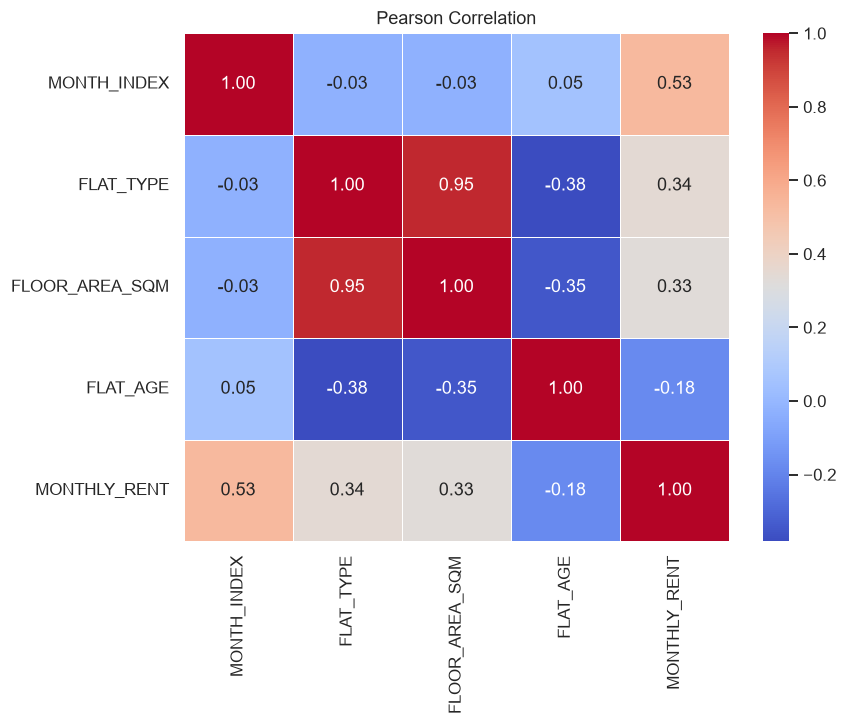

In [60]:
matrix = df[['MONTH_INDEX', 'FLAT_TYPE', 'FLOOR_AREA_SQM', 'FLAT_AGE', 'MONTHLY_RENT']].corr()
plt.figure(figsize=(8,6))
sns.heatmap(matrix, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Pearson Correlation")
plt.show()

For testing, let us fit three simple linear regression models: (1) with `FLAT_TYPE`, (2) with `FLOOR_AREA_SQM`, and (3) with both features. Among the three configurations, the model with both `FLAT_TYPE` and `FLOOR_AREA_SQM` performs the best (lowest MAE and highest R^2). Therefore, we keep both `FLAT_TYPE` and `FLOOR_AREA_SQM` for now.

In [61]:
# Helper function: Train-test split by time
def time_split(df, features, train_percent):
    data = df.copy()
    data = data[features + ["MONTHLY_RENT", "RENT_APPROVAL_DATE"]]
    data["RENT_APPROVAL_DATE"] = pd.to_datetime(data["RENT_APPROVAL_DATE"], format="%Y-%m")
    data = data.sort_values("RENT_APPROVAL_DATE")

    # Example: First 80% for training, last 20% for testing (chronological)
    cutoff_date = data["RENT_APPROVAL_DATE"].iloc[int(len(data) * train_percent)]
    train = data[data["RENT_APPROVAL_DATE"] < cutoff_date]
    test = data[data["RENT_APPROVAL_DATE"] >= cutoff_date]

    return train, test, cutoff_date

In [62]:
ablation_features = [
    ["FLAT_TYPE"],                      # FLAT_TYPE
    ["FLOOR_AREA_SQM"],                 # FLOOR_AREA_SQM
    ["FLAT_TYPE", "FLOOR_AREA_SQM"]     # both
]

features = ["MONTH_INDEX", "FLAT_TYPE", "FLOOR_AREA_SQM", "FLAT_AGE"]
train_df, test_df, cutoff_date = time_split(df, features, 0.8)

for ablation in ablation_features:
    selected_features = ["MONTH_INDEX", "FLAT_AGE"] + ablation
    
    X_train = train_df[selected_features]
    X_test = test_df[selected_features]
    y_train = train_df["MONTHLY_RENT"]
    y_test = test_df["MONTHLY_RENT"]

    model = LinearRegression()
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    print("Features:", selected_features)
    print("Cutoff:", cutoff_date)
    print("MAE:", mean_absolute_error(y_test, predictions))
    print("RMSE:", np.sqrt(mean_squared_error(y_test, predictions)))
    print("R^2:", r2_score(y_test, predictions))
    print()

Features: ['MONTH_INDEX', 'FLAT_AGE', 'FLAT_TYPE']
Cutoff: 2024-05-01 00:00:00
MAE: 523.4740147213818
RMSE: 675.7287076115879
R^2: -0.05785053979411936

Features: ['MONTH_INDEX', 'FLAT_AGE', 'FLOOR_AREA_SQM']
Cutoff: 2024-05-01 00:00:00
MAE: 526.785213394172
RMSE: 679.9060522089294
R^2: -0.07097019950950845

Features: ['MONTH_INDEX', 'FLAT_AGE', 'FLAT_TYPE', 'FLOOR_AREA_SQM']
Cutoff: 2024-05-01 00:00:00
MAE: 523.3148036394599
RMSE: 675.5838044566138
R^2: -0.057396897840829686



#### FLAT_MODEL Suspicious Values

All flat models look valid, except for a suspicious `2 room` model which seems redundant since this is identical to the `FLAT_TYPE`.

In [63]:
df["FLAT_MODEL"].value_counts()

FLAT_MODEL
improved                  44008
model a                   42745
new generation            27380
premium apartment         12312
simplified                 6794
standard                   5903
apartment                  4724
maisonette                 2346
model a2                   1553
dbss                       1090
type s1                     299
2 room                      224
adjoined flat               218
type s2                     160
model a maisonette          140
premium apartment loft       51
premium maisonette           21
terrace                      19
3gen                         12
improved maisonette           1
Name: count, dtype: int64

As expected, all `FLAT_MODEL = 2 room` records are of `FLAT_TYPE = 2`.

In [64]:
df[df["FLAT_MODEL"] == "2 room"]

,RENT_APPROVAL_DATE,MONTH_INDEX,TOWN,BLOCK,STREET,FLAT_TYPE,FLAT_MODEL,FLOOR_AREA_SQM,FLAT_AGE,MONTHLY_RENT
65,2021-01,0,central,9,jalan kukoh,2,2 room,55.000,39,1500
1320,2021-01,0,bukit merah,127a,kim tian road,2,2 room,47.000,8,1800
2282,2021-01,0,pasir ris,528a,pasir ris street 51,2,2 room,47.000,6,1700
6577,2021-03,2,punggol,256a,sumang walk,2,2 room,47.000,5,1600
7372,2021-03,2,hougang,993a,buangkok link,2,2 room,47.000,0,1700
...,...,...,...,...,...,...,...,...,...,...
149721,2025-03,50,bukit merah,127a,kim tian road,2,2 room,47.000,12,3000
149737,2025-03,50,hougang,994b,buangkok link,2,2 room,47.000,4,2500
149770,2025-03,50,yishun,462a,yishun avenue 6,2,2 room,38.000,6,2400
149773,2025-03,50,bukit batok,436a,bukit batok west avenue 5,2,2 room,47.000,5,2500


Comparing it with other records with `FLAT_TYPE = 2`, we may note that the `FLAT_MODEL` values can be more varied and descriptive.

In [65]:
df[df["FLAT_TYPE"] == 2]

,RENT_APPROVAL_DATE,MONTH_INDEX,TOWN,BLOCK,STREET,FLAT_TYPE,FLAT_MODEL,FLOOR_AREA_SQM,FLAT_AGE,MONTHLY_RENT
16,2021-01,0,geylang,32,balam road,2,standard,46.000,48,1600
52,2021-01,0,toa payoh,54,lorong 5 toa payoh,2,standard,43.000,54,1000
65,2021-01,0,central,9,jalan kukoh,2,2 room,55.000,39,1500
141,2021-01,0,woodlands,780f,woodlands crescent,2,model a,47.000,6,1000
174,2021-01,0,bedok,541,bedok north street 3,2,improved,45.000,36,1500
...,...,...,...,...,...,...,...,...,...,...
149743,2025-03,50,bukit merah,48,lower delta road,2,standard,42.000,55,2200
149770,2025-03,50,yishun,462a,yishun avenue 6,2,2 room,38.000,6,2400
149773,2025-03,50,bukit batok,436a,bukit batok west avenue 5,2,2 room,47.000,5,2500
149789,2025-03,50,jurong west,150a,corporation drive,2,2 room,47.000,6,2150


If we consider `2 room` values for `FLAT_MODEL` as an error, we can attempt a reconstruction. One approach is to determine the `FLAT_MODEL` of other records at similar `BLOCK`, `STREET` and `FLAT_TYPE` combinations. However, the issue with this approach is that records with `2 room` values appear to have all their records completely affected for their `BLOCK`, `STREET`, and `FLAT_TYPE` combinations. See below as an example.

In [66]:
df[(df['BLOCK'] == "9") & (df['STREET'] == "jalan kukoh") & (df['FLAT_TYPE'] == 2)].head(10)

,RENT_APPROVAL_DATE,MONTH_INDEX,TOWN,BLOCK,STREET,FLAT_TYPE,FLAT_MODEL,FLOOR_AREA_SQM,FLAT_AGE,MONTHLY_RENT
65,2021-01,0,central,9,jalan kukoh,2,2 room,55.000,39,1500
24357,2021-08,7,central,9,jalan kukoh,2,2 room,55.000,39,1550
29417,2021-10,9,central,9,jalan kukoh,2,2 room,55.000,39,1650
31912,2021-11,10,central,9,jalan kukoh,2,2 room,55.000,39,1900
35377,2021-12,11,central,9,jalan kukoh,2,2 room,55.000,39,1200
36185,2021-12,11,central,9,jalan kukoh,2,2 room,55.000,39,1400
45578,2022-03,14,central,9,jalan kukoh,2,2 room,55.000,40,1500
56377,2022-07,18,central,9,jalan kukoh,2,2 room,55.000,40,2400
57648,2022-07,18,central,9,jalan kukoh,2,2 room,55.000,40,2000
65040,2022-11,22,central,9,jalan kukoh,2,2 room,55.000,40,1200


Consequently, there does not seem to be a reliable way to fix or reconstruct the real value for `FLAT_MODEL`. It does not seem to be worth dropping the records either just because of this minor issue, so the verdict is to leave the `2 room` records as is.

#### STREET vs BLOCK_STREET

The `BLOCK` feature is quite useless without the `STREET`. We can either drop `BLOCK`, or combine both `BLOCK` and `STREET` into a single feature. We create a new feature for this called `BLOCK_STREET`.

In [67]:
df.insert(loc=2, column='BLOCK_STREET', value=df["BLOCK"] + " " + df["STREET"])

# df.drop(columns=["BLOCK", "STREET"], inplace=True)
df

,RENT_APPROVAL_DATE,MONTH_INDEX,BLOCK_STREET,TOWN,BLOCK,STREET,FLAT_TYPE,FLAT_MODEL,FLOOR_AREA_SQM,FLAT_AGE,MONTHLY_RENT
0,2021-01,0,604a punggol road,punggol,604a,punggol road,4,model a,93.000,9,1800
1,2021-01,0,290c compassvale crescent,sengkang,290c,compassvale crescent,5,improved,110.000,20,2000
2,2021-01,0,5 ghim moh road,queenstown,5,ghim moh road,3,improved,65.000,45,2000
3,2021-01,0,436b fernvale road,sengkang,436b,fernvale road,4,model a,96.000,11,1400
4,2021-01,0,467b admiralty drive,sembawang,467b,admiralty drive,4,premium apartment,102.000,20,1800
...,...,...,...,...,...,...,...,...,...,...,...
149995,2025-03,50,220 bukit batok east avenue 3,bukit batok,220,bukit batok east avenue 3,3,new generation,67.000,40,2500
149996,2025-03,50,79 dawson road,queenstown,79,dawson road,5,improved,107.000,5,5300
149997,2025-03,50,17 lorong 7 toa payoh,toa payoh,17,lorong 7 toa payoh,3,improved,67.000,54,2650
149998,2025-03,50,360a admiralty drive,sembawang,360a,admiralty drive,4,premium apartment,94.000,24,3300


In [68]:
df['STREET'].value_counts()

STREET
ang mo kio avenue 3      2014
ang mo kio avenue 10     1889
yishun ring road         1888
bedok reservoir road     1508
lorong 1 toa payoh       1229
                         ... 
margaret drive              3
yishun street 44            2
ang mo kio street 23        2
yishun street 42            2
bukit batok street 41       2
Name: count, Length: 576, dtype: int64

In [69]:
df['BLOCK_STREET'].value_counts()

BLOCK_STREET
4 holland close               136
8 holland avenue              131
11 holland drive              127
13 holland drive              125
2 holland avenue              124
                             ... 
479c yishun street 42           1
463b bukit batok street 41      1
41 stirling road                1
802b keat hong close            1
604b tampines avenue 9          1
Name: count, Length: 9406, dtype: int64

In [70]:
ablation_features = [
    ['BLOCK_STREET'],               # BLOCK_STREET
    ['STREET'],                     # STREET
]

features = ['MONTH_INDEX', 'FLAT_TYPE', 'FLAT_AGE', 'STREET', 'BLOCK_STREET']
train_df, test_df, cutoff_date = time_split(df, features, 0.8)

for ablation in ablation_features:
    selected_features = ['MONTH_INDEX', 'FLAT_TYPE', 'FLAT_AGE'] + ablation

    X_train = train_df[selected_features]
    X_test = test_df[selected_features]
    y_train = train_df['MONTHLY_RENT']
    y_test = test_df['MONTHLY_RENT']

    encoder = OneHotEncoder(handle_unknown='ignore')

    train_street_df = encoder.fit_transform(X_train[ablation])
    test_street_df = encoder.transform(X_test[ablation])
    street_columns = encoder.get_feature_names_out(ablation)

    train_street_df = pd.DataFrame.sparse.from_spmatrix(train_street_df, columns=street_columns, index=X_train.index)
    test_street_df = pd.DataFrame.sparse.from_spmatrix(test_street_df, columns=street_columns, index=X_test.index)

    train_other_df = X_train.drop(columns=ablation).astype(pd.SparseDtype("float64", 0))
    test_other_df = X_test.drop(columns=ablation).astype(pd.SparseDtype("float64", 0))

    X_train_final = pd.concat([train_other_df, train_street_df], axis=1)
    X_test_final = pd.concat([test_other_df, test_street_df], axis=1)

    model = LinearRegression()
    model.fit(X_train_final.sparse.to_coo().tocsr(), y_train)
    predictions = model.predict(X_test_final.sparse.to_coo().tocsr())

    print("Features:", selected_features)
    print("Cutoff:", cutoff_date)
    print("MAE:", mean_absolute_error(y_test, predictions))
    print("RMSE:", np.sqrt(mean_squared_error(y_test, predictions)))
    print("R^2:", r2_score(y_test, predictions))
    print()

Features: ['MONTH_INDEX', 'FLAT_TYPE', 'FLAT_AGE', 'BLOCK_STREET']
Cutoff: 2024-05-01 00:00:00
MAE: 460.4037589504164
RMSE: 608.8662613623361
R^2: 0.14113799347082967

Features: ['MONTH_INDEX', 'FLAT_TYPE', 'FLAT_AGE', 'STREET']
Cutoff: 2024-05-01 00:00:00
MAE: 456.53780250576017
RMSE: 612.5874702531312
R^2: 0.13060769592505372



The cardinality of `BLOCK_STREET` seems a bit too high (576 -> 9406), so it probably would not be a good idea using `BLOCK_STREET`.  Consequently, `BLOCK_STREET` is not used as a raw categorical. `STREET` stays one column, and `BLOCK` stays in the cleaned table as a join key (block history is used later, through premiums in Part 2.3).

In [71]:
X_train_final

,MONTH_INDEX,FLAT_TYPE,FLAT_AGE,STREET_admiralty drive,STREET_admiralty link,STREET_ah hood road,STREET_aljunied avenue 2,STREET_aljunied crescent,STREET_aljunied road,STREET_alkaff crescent,STREET_anchorvale crescent,STREET_anchorvale drive,STREET_anchorvale lane,STREET_anchorvale link,STREET_anchorvale road,STREET_anchorvale street,STREET_ang mo kio avenue 1,STREET_ang mo kio avenue 10,STREET_ang mo kio avenue 2,STREET_ang mo kio avenue 3,STREET_ang mo kio avenue 4,STREET_ang mo kio avenue 5,STREET_ang mo kio avenue 6,STREET_ang mo kio avenue 8,STREET_ang mo kio avenue 9,...,STREET_yishun avenue 9,STREET_yishun central,STREET_yishun central 1,STREET_yishun ring road,STREET_yishun street 11,STREET_yishun street 20,STREET_yishun street 21,STREET_yishun street 22,STREET_yishun street 31,STREET_yishun street 41,STREET_yishun street 43,STREET_yishun street 44,STREET_yishun street 51,STREET_yishun street 61,STREET_yishun street 71,STREET_yishun street 72,STREET_yishun street 81,STREET_yuan ching road,STREET_yung an road,STREET_yung ho road,STREET_yung kuang road,STREET_yung loh road,STREET_yung ping road,STREET_yung sheng road,STREET_zion road
0,0,4.000,9.000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2080,0,3.000,41.000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.000,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2081,0,3.000,54.000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2082,0,3.000,46.000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2083,0,5.000,32.000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
115889,39.000,4.000,23.000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
115894,39.000,3.000,43.000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
115885,39.000,4.000,10.000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
115887,39.000,3.000,42.000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [72]:
# One-hot encode STREET
# df = pd.get_dummies(df, columns=['STREET'], dtype="uint8")

In [73]:
# df.drop(columns=['BLOCK'], inplace=True)
df.drop(columns=['BLOCK_STREET'], inplace=True)
df.drop(columns=['RENT_APPROVAL_DATE'], inplace=True)

#### Section 1 Summary
- Add `MONTH_INDEX`, and `FLAT_AGE`
- Drop `FURNISHED`, `FEE` and `LEASE_COMMENCE_DATE`; keep `BLOCK` as a join key, not as a raw categorical
- Normalize `STREET`
- Integer encode `FLAT_TYPE`
- Keep `STREET` as one column (one-hot was only used for the comparison above)
- Use `RENT_APPROVAL_DATE` for train-test split by time; otherwise, it is not really needed
- Keep `FLOOR_AREA_SQM` for now and test its inclusion in the final model; drop it if performance does not improve

Let us inspect the main dataset before and after preprocessing.

Before:

In [74]:
original_df

,RENT_APPROVAL_DATE,TOWN,BLOCK,STREET,FLAT_TYPE,FLAT_MODEL,FLOOR_AREA_SQM,FURNISHED,LEASE_COMMENCE_DATE,FEE,MONTHLY_RENT
0,2021-01,punggol,604a,punggol road,4 room,model a,93.000,yes,2012,0.000,1800
1,2021-01,sengkang,290c,compassvale crescent,5 room,improved,110.000,yes,2001,0.000,2000
2,2021-01,queenstown,5,ghim moh road,3 room,improved,65.000,yes,1976,0.000,2000
3,2021-01,sengkang,436b,fernvale road,4 room,model a,96.000,yes,2010,0.000,1400
4,2021-01,sembawang,467b,admiralty drive,4 room,premium apartment,102.000,yes,2001,0.000,1800
...,...,...,...,...,...,...,...,...,...,...,...
149995,2025-03,bukit batok,220,bukit batok east avenue 3,3-room,new generation,67.000,yes,1985,0.000,2500
149996,2025-03,queenstown,79,dawson road,5-room,improved,107.000,yes,2020,0.000,5300
149997,2025-03,toa payoh,17,lorong 7 toa payoh,3-room,improved,67.000,yes,1971,0.000,2650
149998,2025-03,sembawang,360a,Admiralty Drive,4-room,premium apartment,94.000,yes,2001,0.000,3300


After:

In [75]:
df

,MONTH_INDEX,TOWN,BLOCK,STREET,FLAT_TYPE,FLAT_MODEL,FLOOR_AREA_SQM,FLAT_AGE,MONTHLY_RENT
0,0,punggol,604a,punggol road,4,model a,93.000,9,1800
1,0,sengkang,290c,compassvale crescent,5,improved,110.000,20,2000
2,0,queenstown,5,ghim moh road,3,improved,65.000,45,2000
3,0,sengkang,436b,fernvale road,4,model a,96.000,11,1400
4,0,sembawang,467b,admiralty drive,4,premium apartment,102.000,20,1800
...,...,...,...,...,...,...,...,...,...
149995,50,bukit batok,220,bukit batok east avenue 3,3,new generation,67.000,40,2500
149996,50,queenstown,79,dawson road,5,improved,107.000,5,5300
149997,50,toa payoh,17,lorong 7 toa payoh,3,improved,67.000,54,2650
149998,50,sembawang,360a,admiralty drive,4,premium apartment,94.000,24,3300


In [76]:
# Output cleaned CSV
df.to_csv('../cleaned/train_cleaned.csv', index=False)

#### Test Set: Preprocessing

We repeat the same preprocessing steps done on the train set to the test set as well. Then, we output the cleaned `.csv`.

In [77]:
test_df = pd.read_csv(f"{data_dir}/test.csv")
df = test_df.copy()

Replace `RENT_APPROVAL_DATE` with `MONTH_INDEX`.

In [78]:
date = pd.to_datetime(df['RENT_APPROVAL_DATE'], format="%Y-%m")
df.insert(loc=1, column='MONTH_INDEX', value=(date.dt.year - 2021) * 12 + date.dt.month - 1)

Drop constant columns `FURNISHED` and `FEE`.

In [79]:
df.drop(columns=['FURNISHED', 'FEE'], inplace=True)

Set `STREET` names all to lowercase.

In [80]:
# Normalize to lowercase
df['STREET'] = df['STREET'].str.lower()

Derive `FLAT_AGE` from `RENT_APPROVAL_DATE` and `LEASE_COMMENCE_DATE`.

In [81]:
df['RENT_APPROVAL_YEAR'] = df['RENT_APPROVAL_DATE'].str[:4].astype(int)
df.insert(loc=8, column='FLAT_AGE', value=df['RENT_APPROVAL_YEAR'] - df['LEASE_COMMENCE_DATE'])

df.drop(columns=['RENT_APPROVAL_YEAR', 'LEASE_COMMENCE_DATE'], inplace=True)

Standardize inconsistent `FLAT_TYPE` values, then encode the categorical values into integers.

In [82]:
# Standardize hyphenation
df['FLAT_TYPE'] = df['FLAT_TYPE'].str.replace(" room", "-room")

In [83]:
# Integer encoding
flat_type_encoding = {
    "executive": 6,
    "5-room": 5,
    "4-room": 4,
    "3-room": 3,
    "2-room": 2,
    "1-room": 1
}

df['FLAT_TYPE'] = df['FLAT_TYPE'].map(flat_type_encoding)

Drop unnecessary attributes.

In [84]:
# df.drop(columns=['BLOCK'], inplace=True)
df.drop(columns=['RENT_APPROVAL_DATE'], inplace=True)

Let us inspect the test dataset before and after preprocessing.

Before:

In [85]:
test_df

,RENT_APPROVAL_DATE,TOWN,BLOCK,STREET,FLAT_TYPE,FLAT_MODEL,FLOOR_AREA_SQM,FURNISHED,LEASE_COMMENCE_DATE,FEE
0,2025-03,kallang/whampoa,74,Whampoa Drive,3-room,improved,66.000,yes,1981,0.000
1,2025-03,bukit timah,6,farrer road,4-room,improved,91.000,yes,1974,0.000
2,2025-03,pasir ris,755,Pasir Ris Street 71,4-room,model a,105.000,yes,1996,0.000
3,2025-03,punggol,299,punggol central,4-room,premium apartment,94.000,yes,2003,0.000
4,2025-03,tampines,869a,tampines avenue 8,4-room,model a,92.000,yes,2015,0.000
...,...,...,...,...,...,...,...,...,...,...
49995,2026-07,bukit batok,138,bukit batok west avenue 6,3-room,new generation,68.000,yes,1984,0.000
49996,2026-07,queenstown,88,dawson road,4-room,premium apartment,83.000,yes,2016,0.000
49997,2026-07,toa payoh,235,lorong 8 toa payoh,3-room,improved,76.000,yes,1976,0.000
49998,2026-07,bukit panjang,613,Bukit Panjang Ring Road,4-room,model a,90.000,yes,2002,0.000


After:

In [86]:
df

,MONTH_INDEX,TOWN,BLOCK,STREET,FLAT_TYPE,FLAT_MODEL,FLOOR_AREA_SQM,FLAT_AGE
0,50,kallang/whampoa,74,whampoa drive,3,improved,66.000,44
1,50,bukit timah,6,farrer road,4,improved,91.000,51
2,50,pasir ris,755,pasir ris street 71,4,model a,105.000,29
3,50,punggol,299,punggol central,4,premium apartment,94.000,22
4,50,tampines,869a,tampines avenue 8,4,model a,92.000,10
...,...,...,...,...,...,...,...,...
49995,66,bukit batok,138,bukit batok west avenue 6,3,new generation,68.000,42
49996,66,queenstown,88,dawson road,4,premium apartment,83.000,10
49997,66,toa payoh,235,lorong 8 toa payoh,3,improved,76.000,50
49998,66,bukit panjang,613,bukit panjang ring road,4,model a,90.000,24


In [87]:
# Output cleaned CSV
df.to_csv('../cleaned/test_cleaned.csv', index=False)

## Part 1.3. HDB Rentals: EDA of `data/auxiliary/sg-hdb-block.csv`

This is the address crosswalk. It joins to `train.csv` / `test.csv` on `(TOWN, BLOCK, STREET)` and
adds coordinates, building attributes, and a geography finer than `TOWN`.

The 1 km counts need school and MRT coordinates, so they are built in Part 1.6.

1. Why this table exists
2. Structure: shape, dtypes, missingness, duplicates
3. `.describe()` for numeric and categorical columns
4. Data-quality issues
5. A cleaned analysis frame
6. Join coverage against train/test
7. Geography and building attributes
8. Summary


In [88]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110

ROOT = Path("..") if Path("../data").exists() else Path(".")
DATA = ROOT / "data"
AUX = DATA / "auxiliary"
CLEANED = ROOT / "cleaned"
OUT = ROOT / "outputs"
OUT_DIR = OUT
CLEANED.mkdir(parents=True, exist_ok=True)
OUT.mkdir(parents=True, exist_ok=True)

SG_LAT = (1.13, 1.47)
SG_LON = (103.6, 104.1)


def column_profile(df: pd.DataFrame) -> pd.DataFrame:
    rows = []
    for c in df.columns:
        s = df[c]
        rows.append(
            {
                "dtype": str(s.dtype),
                "n_unique": s.nunique(dropna=True),
                "unique_pct": 100 * s.nunique(dropna=True) / len(s),
                "n_missing": s.isna().sum(),
                "missing_pct": 100 * s.isna().mean(),
                "examples": ", ".join(map(str, s.dropna().unique()[:4])),
            }
        )
    return pd.DataFrame(rows, index=df.columns)


def lower_strip(df: pd.DataFrame) -> pd.DataFrame:
    out = df.copy()
    text = out.select_dtypes(include=["object", "string"]).columns
    out[text] = out[text].apply(lambda s: s.astype(str).str.strip().str.lower())
    return out

hdb_raw = pd.read_csv(AUX / "sg-hdb-block.csv", dtype={"POSTAL_CODE": "string"})
train = pd.read_csv(DATA / "train.csv")
test = pd.read_csv(DATA / "test.csv")
print(f"hdb: {hdb_raw.shape}   train: {train.shape}   test: {test.shape}")
hdb_raw.head()


hdb: (9464, 11)   train: (150000, 11)   test: (50000, 10)


,TOWN,BLOCK,STREET,POSTAL_CODE,LATITUDE,LONGITUDE,MAX_FLOOR,YEAR_COMPLETED,SUBZONE,PLANNING_AREA,REGION
0,serangoon,106,serangoon north avenue 1,550106,1.370,103.871,12,1983,serangoon garden,serangoon,north-east region
1,bukit merah,34,telok blangah way,090034,1.274,103.822,14,1975,telok blangah rise,bukit merah,central region
2,punggol,226b,sumang lane,822226,1.403,103.894,17,2016,matilda,punggol,north-east region
3,marine parade,74,marine drive,440074,1.304,103.907,14,1975,marine parade,marine parade,central region
4,choa chu kang,284,choa chu kang avenue 3,NIL,1.380,103.742,16,1990,keat hong,choa chu kang,west region


### 1. Why this table exists

Rental rows have a town, block and street, but no coordinates, no floor count and no planning area.
This file is the lookup for those fields. If the join key is dirty, every downstream MRT / school
feature that travels through `PLANNING_AREA` is dirty too — so this part cleans the crosswalk
before anything is merged onto rent.


In [89]:
print("join key: (TOWN, BLOCK, STREET)")
print("columns that travel onto a rental row:")
print([c for c in hdb_raw.columns if c not in {"TOWN", "BLOCK", "STREET"}])


join key: (TOWN, BLOCK, STREET)
columns that travel onto a rental row:
['POSTAL_CODE', 'LATITUDE', 'LONGITUDE', 'MAX_FLOOR', 'YEAR_COMPLETED', 'SUBZONE', 'PLANNING_AREA', 'REGION']


### 2. Structure, dtypes and missingness

Cardinality and example values per column. `isnull()` only sees real NaNs — sentinel placeholders
are checked in section 4.


In [90]:
hdb_raw.info()


<class 'pandas.DataFrame'>
RangeIndex: 9464 entries, 0 to 9463
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   TOWN            9464 non-null   str    
 1   BLOCK           9464 non-null   str    
 2   STREET          9464 non-null   str    
 3   POSTAL_CODE     9464 non-null   string 
 4   LATITUDE        9464 non-null   float64
 5   LONGITUDE       9464 non-null   float64
 6   MAX_FLOOR       9464 non-null   int64  
 7   YEAR_COMPLETED  9464 non-null   int64  
 8   SUBZONE         9464 non-null   str    
 9   PLANNING_AREA   9464 non-null   str    
 10  REGION          9464 non-null   str    
dtypes: float64(2), int64(2), str(6), string(1)
memory usage: 813.4 KB


In [91]:
profile = column_profile(hdb_raw)
profile


,dtype,n_unique,unique_pct,n_missing,missing_pct,examples
TOWN,str,26,0.275,0,0.000,"serangoon, bukit merah, punggol, marine parade"
BLOCK,str,2735,28.899,0,0.000,"106, 34, 226b, 74"
STREET,str,576,6.086,0,0.000,"serangoon north avenue 1, telok blangah way, s..."
POSTAL_CODE,string,9180,96.999,0,0.000,"550106, 090034, 822226, 440074"
LATITUDE,float64,9049,95.615,0,0.000,"1.370245, 1.273518, 1.402685, 1.303705"
LONGITUDE,float64,9258,97.823,0,0.000,"103.870823, 103.822481, 103.893609, 103.907214"
MAX_FLOOR,int64,44,0.465,0,0.000,"12, 14, 17, 16"
YEAR_COMPLETED,int64,63,0.666,0,0.000,"1983, 1975, 2016, 1990"
SUBZONE,str,156,1.648,0,0.000,"serangoon garden, telok blangah rise, matilda,..."
PLANNING_AREA,str,31,0.328,0,0.000,"serangoon, bukit merah, punggol, marine parade"


In [92]:
print("fully duplicated rows:", hdb_raw.duplicated().sum())
print("duplicated join keys:", hdb_raw.duplicated(["TOWN", "BLOCK", "STREET"]).sum())


fully duplicated rows: 0
duplicated join keys: 0


### 3. `.describe()`

Numeric and categorical columns are described separately.


In [93]:
num_cols = hdb_raw.select_dtypes(include="number").columns.tolist()
cat_cols = [c for c in hdb_raw.columns if c not in num_cols]
print("numeric    :", num_cols)
print("categorical:", cat_cols)

hdb_raw[num_cols].describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.99]).T


numeric    : ['LATITUDE', 'LONGITUDE', 'MAX_FLOOR', 'YEAR_COMPLETED']
categorical: ['TOWN', 'BLOCK', 'STREET', 'POSTAL_CODE', 'SUBZONE', 'PLANNING_AREA', 'REGION']


,count,mean,std,min,1%,25%,50%,75%,99%,max
LATITUDE,"9,464.000",1.367,0.042,1.270,1.277,1.339,1.364,1.393,1.451,1.457
LONGITUDE,"9,464.000",103.841,0.074,103.685,103.694,103.774,103.846,103.900,103.961,103.988
MAX_FLOOR,"9,464.000",14.295,5.989,-1.000,4.000,12.000,13.000,16.000,40.000,50.000
YEAR_COMPLETED,"9,464.000","1,989.842",69.139,-1.000,"1,963.000","1,984.000","1,991.000","1,999.000","2,019.000","2,021.000"


In [94]:
hdb_raw[cat_cols].describe().T


,count,unique,top,freq
TOWN,9464,26,tampines,761
BLOCK,9464,2735,111,27
STREET,9464,576,yishun ring road,140
POSTAL_CODE,9464,9180,NIL,285
SUBZONE,9464,156,tampines east,414
PLANNING_AREA,9464,31,tampines,761
REGION,9464,5,west region,2320


### 4. Data-quality issues

Four things are not visible from `info()` / `isnull()` alone.


In [95]:
# (a) -1 is a missing-value placeholder, not a real floor or year.
for c in ["MAX_FLOOR", "YEAR_COMPLETED"]:
    n = (hdb_raw[c] == -1).sum()
    print(f"{c:<16} min={hdb_raw[c].min():>6}  n_eq_-1={n}")

missing_blocks = hdb_raw[(hdb_raw["MAX_FLOOR"] == -1) | (hdb_raw["YEAR_COMPLETED"] == -1)]
print(f"\nblocks with sentinel -1: {len(missing_blocks)}")
missing_blocks[["TOWN", "BLOCK", "STREET", "MAX_FLOOR", "YEAR_COMPLETED"]]


MAX_FLOOR        min=    -1  n_eq_-1=11
YEAR_COMPLETED   min=    -1  n_eq_-1=11

blocks with sentinel -1: 11


,TOWN,BLOCK,STREET,MAX_FLOOR,YEAR_COMPLETED
2859,queenstown,30,tanglin halt road,-1,-1
3400,geylang,82,macpherson lane,-1,-1
4113,clementi,518,west coast road,-1,-1
4385,queenstown,63,commonwealth drive,-1,-1
5391,clementi,514,west coast road,-1,-1
5525,clementi,515,west coast road,-1,-1
5550,queenstown,55,commonwealth drive,-1,-1
6501,clementi,513,west coast road,-1,-1
7764,queenstown,40,tanglin halt road,-1,-1
8238,clementi,519,west coast road,-1,-1


In [96]:
# (b) POSTAL_CODE stores the string "NIL" for 285 blocks — also invisible to isnull().
postal = hdb_raw["POSTAL_CODE"].astype(str).str.strip()
n_nil = postal.str.upper().eq("NIL").sum()
print(f"POSTAL_CODE == 'NIL': {n_nil} rows  (isnull reports {hdb_raw['POSTAL_CODE'].isna().sum()})")
hdb_raw.loc[postal.str.upper().eq("NIL"), ["TOWN", "BLOCK", "STREET", "POSTAL_CODE"]].head(8)


POSTAL_CODE == 'NIL': 285 rows  (isnull reports 0)


,TOWN,BLOCK,STREET,POSTAL_CODE
4,choa chu kang,284,choa chu kang avenue 3,NIL
17,toa payoh,158,lorong 1 toa payoh,NIL
66,jurong west,274d,jurong west avenue 3,NIL
82,jurong west,725,jurong west avenue 5,NIL
234,bukit merah,113,bukit purmei road,NIL
240,yishun,160,yishun street 11,NIL
259,toa payoh,97,lorong 3 toa payoh,NIL
319,woodlands,715,woodlands drive 70,NIL


In [97]:
# (c) Coordinates should sit inside Singapore.
bad_coords = hdb_raw[
    ~hdb_raw["LATITUDE"].between(*SG_LAT) | ~hdb_raw["LONGITUDE"].between(*SG_LON)
]
print(f"out-of-bounds coordinates: {len(bad_coords)}")


out-of-bounds coordinates: 0


In [98]:
# (d) TOWN is not 1:1 with PLANNING_AREA. A few towns split, which later explains "zero school" areas.
split = (
    hdb_raw.groupby("TOWN")["PLANNING_AREA"]
    .nunique()
    .loc[lambda s: s > 1]
    .sort_values(ascending=False)
)
print("towns that span more than one planning area:")
print(split.to_string())
print()
(
    hdb_raw[hdb_raw["TOWN"].isin(split.index)]
    .groupby(["TOWN", "PLANNING_AREA"])
    .size()
    .rename("n_blocks")
    .reset_index()
    .sort_values(["TOWN", "n_blocks"], ascending=[True, False])
)


towns that span more than one planning area:
TOWN
kallang/whampoa    4
central            3
bukit timah        2
hougang            2
pasir ris          2
queenstown         2



,TOWN,PLANNING_AREA,n_blocks
0,bukit timah,bukit timah,24
1,bukit timah,tanglin,2
4,central,rochor,33
3,central,outram,29
2,central,downtown core,2
5,hougang,hougang,559
6,hougang,serangoon,1
9,kallang/whampoa,kallang,184
10,kallang/whampoa,novena,62
7,kallang/whampoa,bukit timah,1


The 11 sentinel blocks are not scattered: they sit on a handful of streets (Queenstown, Clementi,
Geylang). In the rental file those addresses stop appearing after 2023, which is consistent with
SERS / redevelopment vacancy rather than a random hole. They are flagged in the cleaned frame, not
dropped. `MAX_FLOOR` is left missing; there is no reliable proxy for height.


### 5. A cleaned analysis frame

Only the repairs above: lowercase keys, `-1` → `<NA>`, `"NIL"` postal codes → `<NA>`, a
missing-info flag. `MAX_FLOOR` stays missing for the 11 SERS blocks. No median (or other) fill
in this table. LightGBM can leave those NaNs as missing later. Linear Regression only fills a
median if `MAX_FLOOR` is actually in that model.


In [99]:
KEY = ["TOWN", "BLOCK", "STREET"]


def clean_hdb(df: pd.DataFrame) -> pd.DataFrame:
    out = lower_strip(df)
    for c in ["MAX_FLOOR", "YEAR_COMPLETED"]:
        out[c] = pd.to_numeric(out[c], errors="coerce").replace(-1, np.nan).astype("Int64")
    out["POSTAL_CODE"] = out["POSTAL_CODE"].replace({"nil": pd.NA})
    out["LATITUDE"] = pd.to_numeric(out["LATITUDE"], errors="coerce")
    out["LONGITUDE"] = pd.to_numeric(out["LONGITUDE"], errors="coerce")
    out["MISSING_BUILDING_INFO"] = out["MAX_FLOOR"].isna() | out["YEAR_COMPLETED"].isna()
    out = out.drop_duplicates(subset=KEY, keep="first").reset_index(drop=True)
    return out


hdb = clean_hdb(hdb_raw)
print(hdb.shape)
print("missing after sentinel cleanup:")
print(hdb[["MAX_FLOOR", "YEAR_COMPLETED", "POSTAL_CODE"]].isna().sum())
hdb.head(3)


(9464, 12)
missing after sentinel cleanup:
MAX_FLOOR          11
YEAR_COMPLETED     11
POSTAL_CODE       285
dtype: int64


,TOWN,BLOCK,STREET,POSTAL_CODE,LATITUDE,LONGITUDE,MAX_FLOOR,YEAR_COMPLETED,SUBZONE,PLANNING_AREA,REGION,MISSING_BUILDING_INFO
0,serangoon,106,serangoon north avenue 1,550106,1.370,103.871,12,1983,serangoon garden,serangoon,north-east region,False
1,bukit merah,34,telok blangah way,090034,1.274,103.822,14,1975,telok blangah rise,bukit merah,central region,False
2,punggol,226b,sumang lane,822226,1.403,103.894,17,2016,matilda,punggol,north-east region,False


### 6. Join coverage against train/test

Train/test mix case on `STREET` (and sometimes `BLOCK`). Without a lowercase strip, the join
silently misses rows.


In [100]:
def coverage(rent: pd.DataFrame, blocks: pd.DataFrame, name: str) -> None:
    left = rent.merge(blocks[KEY], on=KEY, how="left", indicator=True)
    hit = (left["_merge"] == "both").mean()
    print(f"{name:<6} matched {hit:.2%}  ({len(rent):,} rows)")


print("raw keys (no case fold):")
coverage(train, hdb_raw, "train")
coverage(test, hdb_raw, "test")

train_k = lower_strip(train)
test_k = lower_strip(test)
print("\nnormalized keys:")
coverage(train_k, hdb, "train")
coverage(test_k, hdb, "test")


raw keys (no case fold):
train  matched 79.48%  (150,000 rows)
test   matched 79.04%  (50,000 rows)



normalized keys:
train  matched 100.00%  (150,000 rows)
test   matched 100.00%  (50,000 rows)


### 7. Geography and building attributes


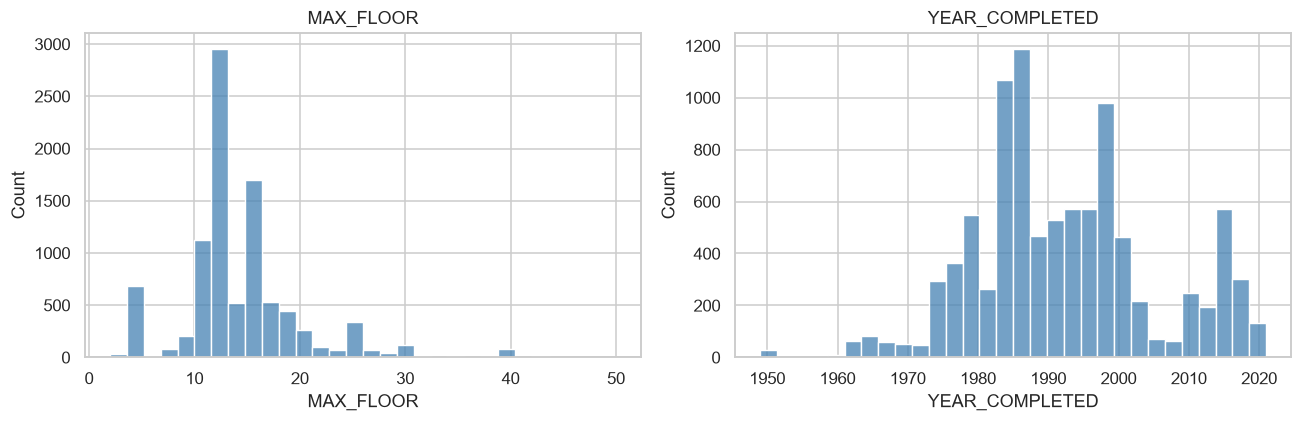

,count,mean,std,min,25%,50%,75%,max
MAX_FLOOR,"9,453.000",14.312,5.970,2.000,12.000,13.000,16.000,50.000
YEAR_COMPLETED,"9,453.000","1,992.158",12.952,"1,949.000","1,984.000","1,991.000","1,999.000","2,021.000"
LATITUDE,"9,464.000",1.367,0.042,1.270,1.339,1.364,1.393,1.457
LONGITUDE,"9,464.000",103.841,0.074,103.685,103.774,103.846,103.900,103.988


In [101]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(hdb["MAX_FLOOR"].astype("float"), bins=30, ax=axes[0], color="steelblue")
axes[0].set_title("MAX_FLOOR")
sns.histplot(hdb["YEAR_COMPLETED"].astype("float"), bins=30, ax=axes[1], color="steelblue")
axes[1].set_title("YEAR_COMPLETED")
plt.tight_layout()
plt.show()

hdb[["MAX_FLOOR", "YEAR_COMPLETED", "LATITUDE", "LONGITUDE"]].describe().T


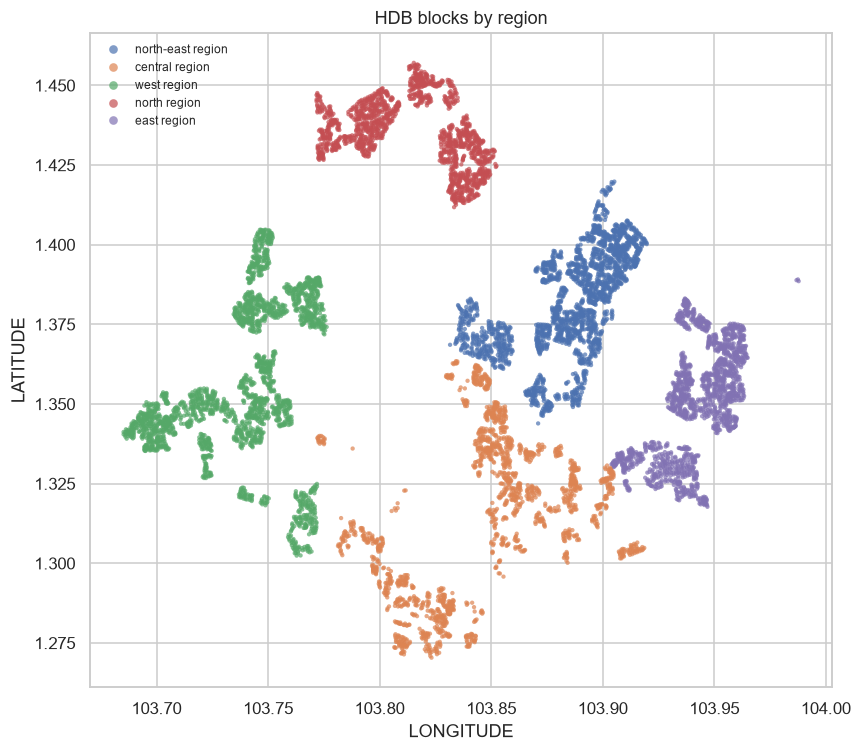

In [102]:
fig, ax = plt.subplots(figsize=(8, 7))
sns.scatterplot(
    data=hdb, x="LONGITUDE", y="LATITUDE", hue="REGION",
    s=8, linewidth=0, alpha=0.7, ax=ax,
)
ax.set_title("HDB blocks by region")
ax.legend(loc="upper left", fontsize=8, markerscale=2, frameon=False)
plt.tight_layout()
plt.show()


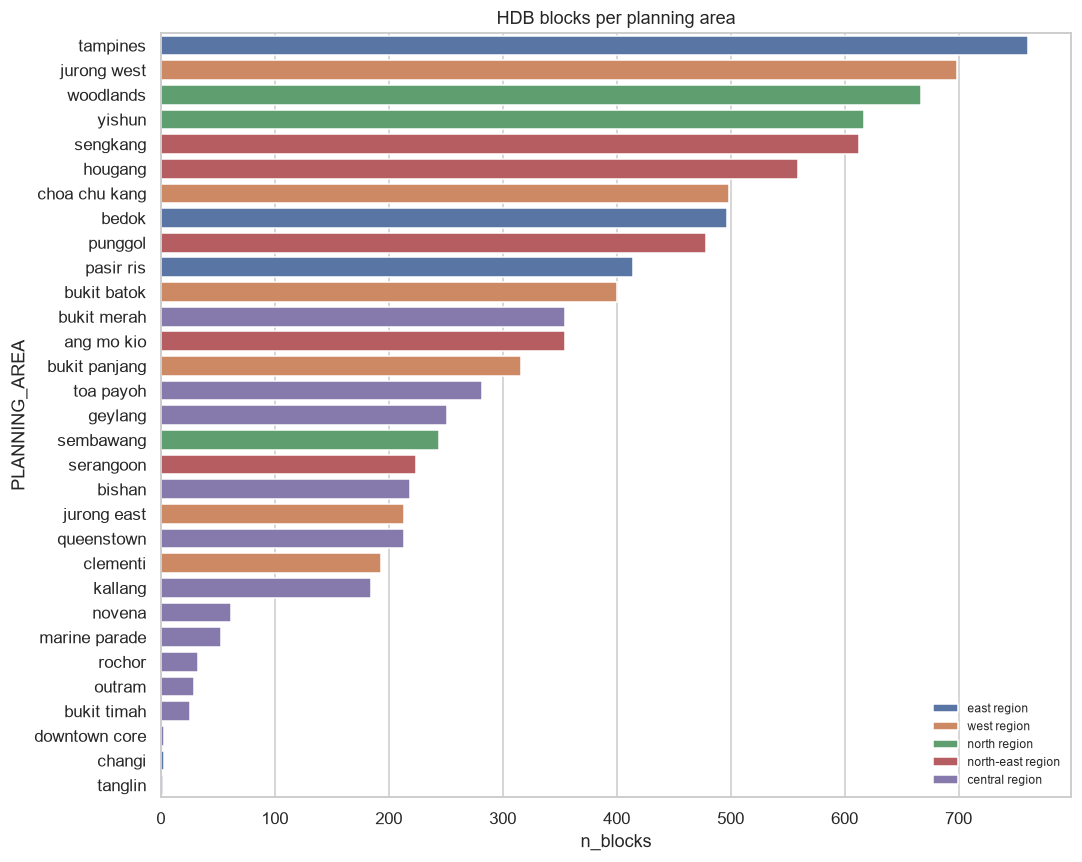

In [103]:
area = (
    hdb.groupby(["REGION", "PLANNING_AREA"], observed=True)
    .size()
    .rename("n_blocks")
    .reset_index()
    .sort_values("n_blocks", ascending=False)
)

fig, ax = plt.subplots(figsize=(10, 8))
sns.barplot(data=area, y="PLANNING_AREA", x="n_blocks", hue="REGION", dodge=False, ax=ax)
ax.set_title("HDB blocks per planning area")
ax.legend(loc="lower right", fontsize=8, frameon=False)
plt.tight_layout()
plt.show()


In [104]:
print("REGION")
print(hdb["REGION"].value_counts(), "\n")
print(f"TOWN={hdb['TOWN'].nunique()}  PLANNING_AREA={hdb['PLANNING_AREA'].nunique()}  "
      f"SUBZONE={hdb['SUBZONE'].nunique()}")


REGION
REGION
west region          2320
north-east region    2229
central region       1712
east region          1675
north region         1528
Name: count, dtype: int64 

TOWN=26  PLANNING_AREA=31  SUBZONE=156


### 8. Summary

- **Role:** block-level lookup for coordinates, `MAX_FLOOR`, `YEAR_COMPLETED`, `SUBZONE` /
  `PLANNING_AREA` / `REGION`.
- **Join:** `(TOWN, BLOCK, STREET)` is unique. Train/test must be lowercased or coverage falls from
  100% to ~79%. After lowercase the match is 100%.
- **Missingness:** `isnull()` reports none; `-1` hides 11 SERS blocks and `"NIL"` hides 285 postcodes.
  Flag `MISSING_BUILDING_INFO`. Leave `MAX_FLOOR` as NaN. Do not impute height in this table.
- **Geography:** 26 towns, 31 planning areas, 5 regions. A few towns split across planning areas
  (`kallang/whampoa`, `central`, …).
- **Not in this part:** 1 km school / MRT counts. Those are in Part 1.6.
- **Next:** Part 1.4, Part 1.5, then Part 1.6.


In [105]:
hdb.to_csv(CLEANED / "sg_hdb_block_cleaned.csv", index=False)

feature_cols = KEY + [
    "LATITUDE", "LONGITUDE", "MAX_FLOOR", "YEAR_COMPLETED",
    "SUBZONE", "PLANNING_AREA", "REGION", "MISSING_BUILDING_INFO",
]
hdb[feature_cols].to_csv(OUT / "hdb_block_features.csv", index=False)

hdb_blocks_by_area = (
    hdb.groupby("PLANNING_AREA").size().rename("n_hdb_blocks").reset_index()
)
hdb_blocks_by_area.to_csv(OUT / "hdb_blocks_by_area.csv", index=False)

print("wrote", CLEANED / "sg_hdb_block_cleaned.csv", hdb.shape)
print("wrote", OUT / "hdb_block_features.csv")
print("wrote", OUT / "hdb_blocks_by_area.csv", hdb_blocks_by_area.shape)


wrote ..\cleaned\sg_hdb_block_cleaned.csv (9464, 12)
wrote ..\outputs\hdb_block_features.csv
wrote ..\outputs\hdb_blocks_by_area.csv (31, 2)


## Part 1.4. HDB Rentals: EDA of `data/auxiliary/sg-mrt-stations.csv`

Station inventory for area-level connectivity. One row is a *(station, line)* pair, not a unique
building: interchanges appear once per line.

Planned stations stay in this table. The 1 km count in Part 1.6 uses unique **open**
station names only.

1. Why this table exists
2. Structure: shape, dtypes, missingness, duplicates
3. `.describe()`
4. Data-quality issues
5. A cleaned analysis frame
6. Lines, status and geography
7. Area-level connectivity features
8. Summary


In [106]:
mrt_raw = pd.read_csv(AUX / "sg-mrt-stations.csv")
print(f"mrt: {mrt_raw.shape}")
mrt_raw.head()


mrt: (243, 8)


,CODE,NAME,STATUS,LATITUDE,LONGITUDE,SUBZONE,PLANNING_AREA,REGION
0,ns10,admiralty mrt station,open,1.441,103.801,woodlands east,woodlands,north region
1,ew9,aljunied mrt station,open,1.316,103.883,aljunied,geylang,central region
2,ns16,ang mo kio mrt station,open,1.370,103.849,cheng san,ang mo kio,north-east region
3,cr11,ang mo kio mrt station,planned,1.370,103.849,cheng san,ang mo kio,north-east region
4,cr2,aviation park mrt station,open,1.370,104.003,changi airport,changi,east region


### 1. Why this table exists

Rental rows have no transport fields. Stations join to flats through `PLANNING_AREA` (from the HDB
crosswalk). This part profiles the inventory, derives `LINE` from `CODE`, flags interchanges,
and counts open / planned stations per area. Those area totals are tested in Part 1.6
and do not beat `TOWN`. Walking-distance counts use the coordinates kept here.


### 2. Structure, dtypes and missingness


In [107]:
mrt_raw.info()


<class 'pandas.DataFrame'>
RangeIndex: 243 entries, 0 to 242
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   CODE           243 non-null    str    
 1   NAME           243 non-null    str    
 2   STATUS         243 non-null    str    
 3   LATITUDE       243 non-null    float64
 4   LONGITUDE      243 non-null    float64
 5   SUBZONE        243 non-null    str    
 6   PLANNING_AREA  243 non-null    str    
 7   REGION         243 non-null    str    
dtypes: float64(2), str(6)
memory usage: 15.3 KB


In [108]:
column_profile(mrt_raw)


,dtype,n_unique,unique_pct,n_missing,missing_pct,examples
CODE,str,243,100.000,0,0.000,"ns10, ew9, ns16, cr11"
NAME,str,192,79.012,0,0.000,"admiralty mrt station, aljunied mrt station, a..."
STATUS,str,2,0.823,0,0.000,"open, planned"
LATITUDE,float64,170,69.959,0,0.000,"1.440689, 1.316389, 1.370017, 1.37"
LONGITUDE,float64,182,74.897,0,0.000,"103.800933, 103.882778, 103.84945, 104.003056"
SUBZONE,str,147,60.494,0,0.000,"woodlands east, aljunied, cheng san, changi ai..."
PLANNING_AREA,str,45,18.519,0,0.000,"woodlands, geylang, ang mo kio, changi"
REGION,str,5,2.058,0,0.000,"north region, central region, north-east regio..."


In [109]:
print("fully duplicated rows:", mrt_raw.duplicated().sum())
print("duplicated CODE:", mrt_raw.duplicated("CODE").sum())
print("duplicated NAME:", mrt_raw.duplicated("NAME").sum(),
      " (expected: interchanges are one row per line)")
print("unique names:", mrt_raw["NAME"].nunique(), "  rows:", len(mrt_raw))


fully duplicated rows: 0
duplicated CODE: 0
duplicated NAME: 51  (expected: interchanges are one row per line)
unique names: 192   rows: 243


### 3. `.describe()`


In [110]:
num_cols = mrt_raw.select_dtypes(include="number").columns.tolist()
cat_cols = [c for c in mrt_raw.columns if c not in num_cols]
print("numeric    :", num_cols)
print("categorical:", cat_cols)

mrt_raw[num_cols].describe().T


numeric    : ['LATITUDE', 'LONGITUDE']
categorical: ['CODE', 'NAME', 'STATUS', 'SUBZONE', 'PLANNING_AREA', 'REGION']


,count,mean,std,min,25%,50%,75%,max
LATITUDE,243.000,1.334,0.041,1.265,1.303,1.328,1.357,1.449
LONGITUDE,243.000,103.832,0.076,103.637,103.783,103.844,103.878,104.003


In [111]:
mrt_raw[cat_cols].describe().T


,count,unique,top,freq
CODE,243,243,ns10,1
NAME,243,192,choa chu kang mrt/lrt station,3
STATUS,243,2,open,231
SUBZONE,243,147,central subzone,6
PLANNING_AREA,243,45,downtown core,19
REGION,243,5,central region,119


### 4. Data-quality issues


In [112]:
# (a) STATUS is open vs planned — planned stations are not yet usable amenity.
print(mrt_raw["STATUS"].value_counts(), "\n")

# (b) Coordinates.
bad_coords = mrt_raw[
    ~mrt_raw["LATITUDE"].between(*SG_LAT) | ~mrt_raw["LONGITUDE"].between(*SG_LON)
]
print(f"out-of-bounds coordinates: {len(bad_coords)}")

# (c) CODE encodes the line as a letter prefix (ns10, ew9, cr11, …).
print("\nCODE examples:", mrt_raw["CODE"].head(8).tolist())


STATUS
open       231
planned     12
Name: count, dtype: int64 

out-of-bounds coordinates: 0

CODE examples: ['ns10', 'ew9', 'ns16', 'cr11', 'cr2', 'js7', 'cc12', 'cc34']


Duplicate `NAME`s are interchanges, not errors. Planned rows stay in the table so area features can
split open vs planned. They are **dropped** when Part 1.6 counts unique open MRT
names within 1 km of a block.


### 5. A cleaned analysis frame


In [113]:
def clean_mrt(df: pd.DataFrame) -> pd.DataFrame:
    out = lower_strip(df)
    out["LATITUDE"] = pd.to_numeric(out["LATITUDE"], errors="coerce")
    out["LONGITUDE"] = pd.to_numeric(out["LONGITUDE"], errors="coerce")
    out["LINE"] = out["CODE"].str.extract(r"^([a-z]+)", expand=False)
    n_lines = out.groupby("NAME")["LINE"].transform("nunique")
    out["IS_INTERCHANGE"] = n_lines.gt(1)
    return out.reset_index(drop=True)


mrt = clean_mrt(mrt_raw)
print(mrt.shape)
print(mrt["LINE"].value_counts())
mrt.head(3)


(243, 10)
LINE
dt     37
cc     34
ew     33
te     33
ns     29
cr     21
ne     17
js     12
je      7
jw      5
cp      4
cg      3
bp      2
de      2
ptc     1
pe      1
stc     1
rts     1
Name: count, dtype: int64


,CODE,NAME,STATUS,LATITUDE,LONGITUDE,SUBZONE,PLANNING_AREA,REGION,LINE,IS_INTERCHANGE
0,ns10,admiralty mrt station,open,1.441,103.801,woodlands east,woodlands,north region,ns,False
1,ew9,aljunied mrt station,open,1.316,103.883,aljunied,geylang,central region,ew,False
2,ns16,ang mo kio mrt station,open,1.370,103.849,cheng san,ang mo kio,north-east region,ns,True


In [114]:
# PLANNING_AREA / REGION spelling vs the HDB crosswalk (shared areas only).
hdb_ref_path = CLEANED / "sg_hdb_block_cleaned.csv"
if hdb_ref_path.exists():
    hdb_ref = pd.read_csv(hdb_ref_path)
    hdb_geo = hdb_ref.drop_duplicates("PLANNING_AREA").set_index("PLANNING_AREA")["REGION"]
    mrt_geo = mrt.drop_duplicates("PLANNING_AREA").set_index("PLANNING_AREA")["REGION"]
    shared = hdb_geo.index.intersection(mrt_geo.index)
    mismatch = (hdb_geo.loc[shared] != mrt_geo.loc[shared]).sum()
    print(f"shared PLANNING_AREA values: {len(shared)}")
    print(f"REGION mismatches on those areas: {mismatch}")
    print("MRT-only planning areas (no HDB housing):",
          sorted(set(mrt["PLANNING_AREA"]) - set(hdb_ref["PLANNING_AREA"])))
else:
    print("run Part 1.3 first to compare spelling against the HDB crosswalk")


shared PLANNING_AREA values: 31
REGION mismatches on those areas: 0
MRT-only planning areas (no HDB housing): ['boon lay', 'marina east', 'marina south', 'museum', 'newton', 'orchard', 'pioneer', 'river valley', 'singapore river', 'straits view', 'sungei kadut', 'tengah', 'tuas', 'western water catchment']


### 6. Lines, status and geography


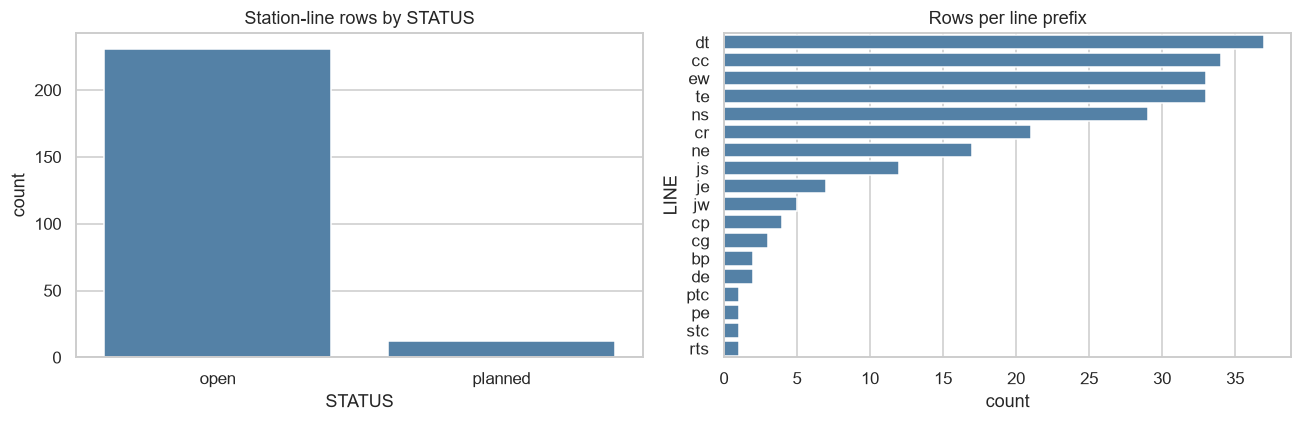

STATUS,open,planned
LINE,,
bp,2,0
cc,34,0
cg,2,1
cp,3,1
cr,14,7
de,2,0
dt,37,0
ew,33,0
je,6,1


In [115]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(data=mrt, x="STATUS", ax=axes[0], color="steelblue")
axes[0].set_title("Station-line rows by STATUS")
sns.countplot(data=mrt, y="LINE", order=mrt["LINE"].value_counts().index,
              ax=axes[1], color="steelblue")
axes[1].set_title("Rows per line prefix")
plt.tight_layout()
plt.show()

pd.crosstab(mrt["LINE"], mrt["STATUS"])


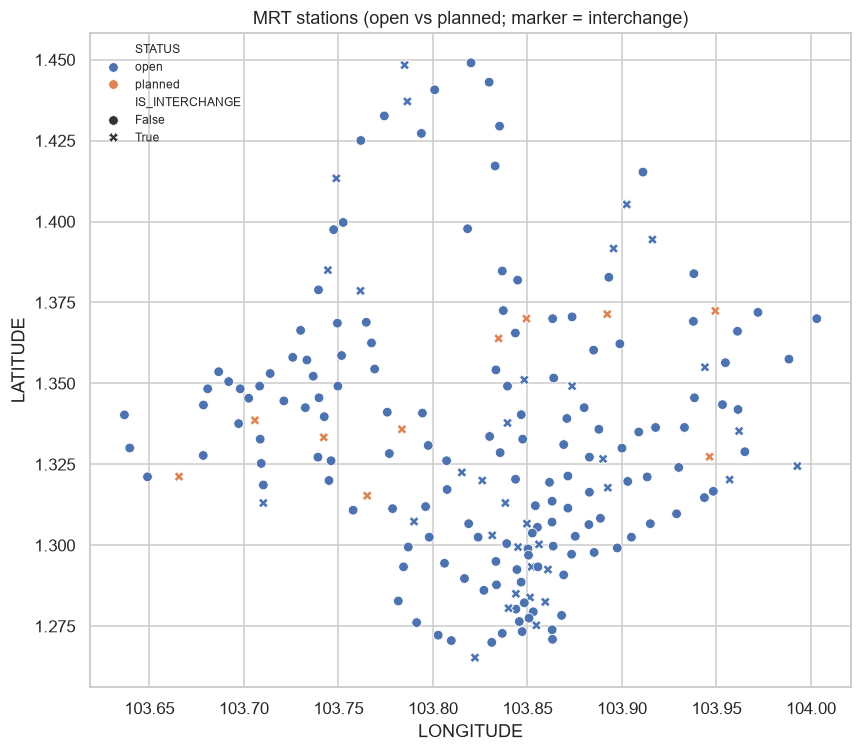

In [116]:
fig, ax = plt.subplots(figsize=(8, 7))
sns.scatterplot(
    data=mrt, x="LONGITUDE", y="LATITUDE", hue="STATUS",
    style="IS_INTERCHANGE", s=40, ax=ax,
)
ax.set_title("MRT stations (open vs planned; marker = interchange)")
ax.legend(loc="upper left", fontsize=8, frameon=False)
plt.tight_layout()
plt.show()


In [117]:
interchanges = (
    mrt.groupby("NAME")["LINE"].nunique().loc[lambda s: s > 1].sort_values(ascending=False)
)
print(f"{len(interchanges)} interchange names (serve >1 line)")
interchanges.head(10).to_frame("n_lines")


44 interchange names (serve >1 line)


,n_lines
NAME,
jurong east mrt station,3
marina bay mrt station,3
dhoby ghaut mrt station,3
choa chu kang mrt/lrt station,3
punggol mrt/lrt station,3
outram park mrt station,3
pasir ris mrt station,3
botanic gardens mrt station,2
ang mo kio mrt station,2


MRT planning areas are a superset of HDB ones: stations also sit in industrial / downtown slivers
with little or no HDB housing (`tuas`, `boon lay`, `orchard`, …). Those areas will not attach to
rental rows.


### 7. Area-level connectivity features

Counts are of station-line rows unless noted. `n_interchange_stations` counts unique names in the
area that serve more than one line anywhere on the network.


In [118]:
mrt_features = mrt.groupby("PLANNING_AREA").agg(
    n_mrt_open=("STATUS", lambda s: s.eq("open").sum()),
    n_mrt_planned=("STATUS", lambda s: s.eq("planned").sum()),
    n_distinct_lines=("LINE", "nunique"),
).reset_index()
interchange_by_area = (
    mrt.loc[mrt["IS_INTERCHANGE"]]
    .groupby("PLANNING_AREA")["NAME"]
    .nunique()
    .rename("n_interchange_stations")
)
mrt_features = mrt_features.merge(interchange_by_area, on="PLANNING_AREA", how="left")
mrt_features["n_interchange_stations"] = mrt_features["n_interchange_stations"].fillna(0).astype(int)
mrt_features["n_mrt_total"] = mrt_features["n_mrt_open"] + mrt_features["n_mrt_planned"]
mrt_features.sort_values("n_mrt_total", ascending=False).head(10)


,PLANNING_AREA,n_mrt_open,n_mrt_planned,n_distinct_lines,n_interchange_stations,n_mrt_total
11,downtown core,19,0,5,6,19
1,bedok,11,1,4,2,12
12,geylang,10,0,3,2,10
37,tampines,10,0,4,2,10
14,jurong east,9,1,5,2,10
15,jurong west,8,1,3,1,9
28,queenstown,9,0,2,1,9
5,bukit merah,9,0,4,1,9
40,toa payoh,8,0,4,1,8
7,bukit timah,7,1,3,1,8


### 8. Summary

- **Grain:** one row = one station on one line. 243 rows, 192 names, 51 extra rows are interchanges.
- **Status:** 231 open, 12 planned. Keep both in this table. Split them in the area counts.
  The 1 km feature uses open names only.
- **Quality:** no missing values, no out-of-bounds coordinates, `CODE` is unique. `PLANNING_AREA`
  / `REGION` spelling matches the HDB crosswalk on every overlapping area.
- **Join path:** `PLANNING_AREA` via the HDB crosswalk, not a direct key onto `train.csv`.
- **Next:** Part 1.5, then Part 1.6.


In [119]:
mrt.to_csv(CLEANED / "sg_mrt_stations_cleaned.csv", index=False)
mrt_features.to_csv(OUT / "mrt_features_by_area.csv", index=False)
print("wrote", CLEANED / "sg_mrt_stations_cleaned.csv", mrt.shape)
print("wrote", OUT / "mrt_features_by_area.csv", mrt_features.shape)


wrote ..\cleaned\sg_mrt_stations_cleaned.csv (243, 10)
wrote ..\outputs\mrt_features_by_area.csv (45, 6)


## Part 1.5. HDB Rentals: EDA of `data/auxiliary/sg-schools.csv`

School inventory for area-level density. This part cleans names, aligns planning-area spelling
with the HDB crosswalk, parses the two free-text transport columns (`MRT_STATIONS`, `BUS_LINES`)
into clean lists, and counts schools per area.

The 1 km primary-school count lives in Part 1.6, not here.

**Free-text columns:** `MRT_STATIONS` and `BUS_LINES` are typed by hand at MOE and are messy. Sections
4(d) and 4(e) show what they actually look like, section 5b parses them, and section 5c checks the
parse against the MRT reference table and the school coordinates. The raw (lowercased) columns are
kept; the parsed ones are added next to them.

1. Why this table exists
2. Structure: shape, dtypes, missingness, duplicates
3. `.describe()`
4. Data-quality issues
5. A cleaned analysis frame (5b parse MRT / bus text, 5c validate the parse, 5d manual coordinate corrections, 5e judgment calls)
6. School mix and geography
7. Area-level school features
8. Summary


In [120]:
schools_raw = pd.read_csv(AUX / "sg-schools.csv")
hdb = pd.read_csv(CLEANED / "sg_hdb_block_cleaned.csv")
mrt = pd.read_csv(CLEANED / "sg_mrt_stations_cleaned.csv")
print(f"schools: {schools_raw.shape}   hdb cleaned: {hdb.shape}   mrt cleaned: {mrt.shape}")
schools_raw.head()


schools: (337, 14)   hdb cleaned: (9464, 12)   mrt cleaned: (243, 10)


,NAME,URL,STREET,POSTAL_CODE,MRT_STATIONS,BUS_LINES,PLANNING_AREA,REGION,TYPE_CODE,NATRUE_CODE,SESSION_CODE,MAINLEVEL_CODE,LATITUDE,LONGITUDE
0,admiralty primary school,https://admiraltypri.moe.edu.sg/,11 woodlands circle,738907,admiralty station,"965, 964, 913",woodlands,north,government school,co-ed school,full day,primary,1.443,103.800
1,admiralty secondary school,http://www.admiraltysec.moe.edu.sg,31 woodlands crescent,737916,admiralty mrt,904,woodlands,north,government school,co-ed school,single session,secondary (s1-s5),1.446,103.802
2,ahmad ibrahim primary school,http://www.ahmadibrahimpri.moe.edu.sg,10 yishun street 11,768643,yishun,yishun ring road - 812 (white plate); yishun a...,yishun,north,government school,co-ed school,single session,primary,1.433,103.833
3,ahmad ibrahim secondary school,http://www.ahmadibrahimsec.moe.edu.sg,751 yishun avenue 7,768928,"canberra mrt, yishun mrt","117, 167, 169, 800, 811, 812, 883, 856, 858, 8...",yishun,north,government school,co-ed school,single session,secondary (s1-s5),1.436,103.830
4,ai tong school,http://www.aitong.moe.edu.sg,100 bright hill drive,579646,bishan mrt,"410, 162, 52",bishan,south,government-aided sch,co-ed school,single session,primary,1.361,103.833


### 1. Why this table exists

`BUS_LINES` contains quoted commas (`"965, 964, 913"`), so the file must be read with a real CSV
parser. Schools join to rentals through `PLANNING_AREA` from the HDB crosswalk. A spelling mismatch
here zeroes out school counts for a whole town. Area-level totals are tested in
Part 1.6 and do not beat `TOWN`.


### 2. Structure, dtypes and missingness


In [121]:
schools_raw.info()


<class 'pandas.DataFrame'>
RangeIndex: 337 entries, 0 to 336
Data columns (total 14 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   NAME            337 non-null    str    
 1   URL             337 non-null    str    
 2   STREET          337 non-null    str    
 3   POSTAL_CODE     337 non-null    int64  
 4   MRT_STATIONS    337 non-null    str    
 5   BUS_LINES       337 non-null    str    
 6   PLANNING_AREA   337 non-null    str    
 7   REGION          337 non-null    str    
 8   TYPE_CODE       337 non-null    str    
 9   NATRUE_CODE     337 non-null    str    
 10  SESSION_CODE    337 non-null    str    
 11  MAINLEVEL_CODE  337 non-null    str    
 12  LATITUDE        337 non-null    float64
 13  LONGITUDE       337 non-null    float64
dtypes: float64(2), int64(1), str(11)
memory usage: 37.0 KB


In [122]:
column_profile(schools_raw)


,dtype,n_unique,unique_pct,n_missing,missing_pct,examples
NAME,str,337,100.000,0,0.000,"admiralty primary school, admiralty secondary ..."
URL,str,337,100.000,0,0.000,"https://admiraltypri.moe.edu.sg/, http://www.a..."
STREET,str,335,99.407,0,0.000,"11 woodlands circle, 31 woodlands crescent, 10..."
POSTAL_CODE,int64,335,99.407,0,0.000,"738907, 737916, 768643, 768928"
MRT_STATIONS,str,251,74.481,0,0.000,"admiralty station, admiralty mrt, yishun, canb..."
BUS_LINES,str,326,96.736,0,0.000,"965, 964, 913, 904, yishun ring road - 812 (wh..."
PLANNING_AREA,str,28,8.309,0,0.000,"woodlands, yishun, bishan, bukit merah"
REGION,str,4,1.187,0,0.000,"north, south, east, west"
TYPE_CODE,str,5,1.484,0,0.000,"government school, government-aided sch, indep..."
NATRUE_CODE,str,3,0.890,0,0.000,"co-ed school, boys' school, girls' school"


In [123]:
print("fully duplicated rows:", schools_raw.duplicated().sum())
print("duplicated NAME:", schools_raw.duplicated("NAME").sum())


fully duplicated rows: 0
duplicated NAME: 0


### 3. `.describe()`


In [124]:
num_cols = schools_raw.select_dtypes(include="number").columns.tolist()
cat_cols = [c for c in schools_raw.columns if c not in num_cols]
print("numeric    :", num_cols)
print("categorical:", cat_cols)

schools_raw[num_cols].describe().T


numeric    : ['POSTAL_CODE', 'LATITUDE', 'LONGITUDE']
categorical: ['NAME', 'URL', 'STREET', 'MRT_STATIONS', 'BUS_LINES', 'PLANNING_AREA', 'REGION', 'TYPE_CODE', 'NATRUE_CODE', 'SESSION_CODE', 'MAINLEVEL_CODE']


,count,mean,std,min,25%,50%,75%,max
POSTAL_CODE,337.000,"540,886.950","188,388.150","88,256.000","449,150.000","549,936.000","679,944.000","828,870.000"
LATITUDE,337.000,1.361,0.042,1.275,1.331,1.354,1.388,1.457
LONGITUDE,337.000,103.841,0.070,103.687,103.785,103.843,103.897,103.963


In [125]:
schools_raw[cat_cols].describe().T


,count,unique,top,freq
NAME,337,337,admiralty primary school,1
URL,337,337,https://admiraltypri.moe.edu.sg/,1
STREET,337,335,11 blackmore drive,2
MRT_STATIONS,337,251,pasir ris mrt,6
BUS_LINES,337,326,na,3
PLANNING_AREA,337,28,woodlands,22
REGION,337,4,east,85
TYPE_CODE,337,5,government school,243
NATRUE_CODE,337,3,co-ed school,293
SESSION_CODE,337,2,single session,319


### 4. Data-quality issues

These are join bugs or source quirks, not NaNs.


In [126]:
# (a) Spelling: schools use "seng kang"; HDB blocks use "sengkang". Lowercase/strip does not catch this.
print("planning-area values that look like sengkang:")
print(sorted(a for a in schools_raw["PLANNING_AREA"].unique() if "kang" in a))
print("rows with PLANNING_AREA == 'seng kang':",
      (schools_raw["PLANNING_AREA"] == "seng kang").sum())


planning-area values that look like sengkang:
['choa chu kang', 'seng kang']
rows with PLANNING_AREA == 'seng kang': 19


In [127]:
# (b) REGION is MOE's 4-zone system, and it is not even consistent inside a planning area.
print("school REGION (MOE zone):")
print(schools_raw["REGION"].value_counts(), "\n")
inconsistent = (
    schools_raw.groupby("PLANNING_AREA")["REGION"].nunique().loc[lambda s: s > 1]
)
print("planning areas with more than one MOE REGION:")
print(inconsistent.to_string())
print("\ncolumn name NATRUE_CODE is a source typo for NATURE.")
print(schools_raw["NATRUE_CODE"].value_counts())


school REGION (MOE zone):
REGION
east     85
north    84
south    84
west     84
Name: count, dtype: int64 

planning areas with more than one MOE REGION:
PLANNING_AREA
ang mo kio     2
bishan         2
bukit timah    2
hougang        3
kallang        2
punggol        2
queenstown     2
serangoon      2
toa payoh      2

column name NATRUE_CODE is a source typo for NATURE.
NATRUE_CODE
co-ed school     293
girls' school     29
boys' school      15
Name: count, dtype: int64


In [128]:
# (c) Four schools are labelled PLANNING_AREA == 'central', which is a town, not a URA area.
central = schools_raw[schools_raw["PLANNING_AREA"].str.lower() == "central"]
print(f"{len(central)} schools labelled 'central':")
central[["NAME", "STREET", "PLANNING_AREA", "REGION", "MRT_STATIONS"]]


4 schools labelled 'central':


,NAME,STREET,PLANNING_AREA,REGION,MRT_STATIONS
16,anglo-chinese school (junior),16 winstedt road,central,south,newton mrt station
235,river valley primary school,2 river valley green,central,south,somerset mrt
242,"school of the arts, singapore",1 zubir said drive 05 01,central,south,dhoby ghaut
271,st. margaret's school (primary),136 sophia road,central,south,"little india mrt station (ne7/dt12), dhoby gha..."


#### 4(d) `MRT_STATIONS` — what it really looks like

The column is one free-text field per school. Before writing a parser, count what kinds of text are
in it. The flags below are not exclusive: one cell can be bare-name *and* multi-station *and* carry a code.

In [129]:
import re

m = schools_raw["MRT_STATIONS"].str.strip().str.lower()
checks = {
    "bare name, no 'mrt'/'station'/'lrt' word":  ~m.str.contains(r"\b(?:mrt|lrt|station|stations)\b"),
    "several stations (, & and / ; or)":           m.str.contains(r",|&|;|/|\band\b|\bor\b"),
    "station code in text (ne16, ew28 ...)":        m.str.contains(r"\b(?:ns|ew|ne|cc|dt|te|se|sw|pe|pw)\s?\d{1,2}\b"),
    "mentions an LRT station":                      m.str.contains(r"\blrt\b"),
    "line name (circle line, tel, nel ...)":        m.str.contains(r"\bline\b|\btel\b|\bnel\b"),
    "walking time / distance note":                 m.str.contains(r"\bwalk\b|\bmin|\bkm\b"),
    "bus numbers inside the MRT column":            m.str.contains(r"\bbus\b"),
    "directions / instructions":                    m.str.contains(r"\balight\b|\bexit\b|\bpending\b"),
    "placeholder (na / nil)":                       m.isin(["na", "nil"]),
}
tax = pd.DataFrame(
    {"n_rows": {k: int(v.sum()) for k, v in checks.items()},
     "example": {k: m[v].iloc[0] if v.any() else "" for k, v in checks.items()}}
)
print("distinct raw strings:", m.nunique(), "of", len(m), "rows")
tax

distinct raw strings: 251 of 337 rows


,n_rows,example
"bare name, no 'mrt'/'station'/'lrt' word",61,yishun
"several stations (, & and / ; or)",134,"canberra mrt, yishun mrt"
"station code in text (ne16, ew28 ...)",15,"mrt : ne16-sengkang, lrt : sw7-tongkang"
mentions an LRT station,35,"mrt : ne16-sengkang, lrt : sw7-tongkang"
"line name (circle line, tel, nel ...)",9,"downtown line 2, cashew mrt"
walking time / distance note,5,nearest mrt station: mattar station (about 3-m...
bus numbers inside the MRT column,2,"eunos station (transfer bus no.63, 63m), ubi s..."
directions / instructions,2,from pending lrt station to choa chu kang mrt ...
placeholder (na / nil),4,nil


In [130]:
# The same station is spelled several ways, so an exact string join to the MRT table finds almost nothing.
print("raw strings that mention 'yishun':")
print(m[m.str.contains("yishun")].value_counts().to_string())

mrt["BASE"] = mrt["NAME"].str.replace(r"\s+mrt(?:/lrt)?\s+station$", "", regex=True)
exact = m.isin(set(mrt["NAME"]))
print(f"\nrows whose whole text equals an MRT-table NAME exactly: {exact.sum()} / {len(m)}")
print("LRT stations (kadaloor, jelapang, fajar ...) are not in the MRT table at all:",
      not mrt["NAME"].str.contains("kadaloor|jelapang|fajar").any())

raw strings that mention 'yishun':
MRT_STATIONS
yishun mrt station                                                                      5
yishun                                                                                  2
yishun, khatib                                                                          2
yishun mrt, khatib mrt                                                                  2
yishun mrt                                                                              2
canberra mrt, yishun mrt                                                                1
o   alight at yishun mrt station, o   take exit c, o   walk towards yishun street 21    1

rows whose whole text equals an MRT-table NAME exactly: 43 / 337
LRT stations (kadaloor, jelapang, fajar ...) are not in the MRT table at all: True


Findings for `MRT_STATIONS`:

- **Spelling:** `admiralty`, `admiralty mrt`, `admiralty station`, `admiralty mrt station` all occur, so
  the station name has to be pulled out of the text; an exact join to the MRT table matches only a
  small minority.
- **Several stations per cell** with five different separators (`,` `&` `and` `/` `;`), sometimes with a
  dangling comma or `or ,`.
- **LRT stations** (Sengkang, Punggol, Bukit Panjang loops) are mixed in. The MRT reference table has no
  LRT stations except the hub rows (`punggol mrt/lrt station` ...), so LRT names need their own list.
- **Not stations at all:** `na` / `nil`, walking times, `alight at ... take exit c`, campus names, bus numbers
  (`transfer bus no.63`), and street names that contain a station name (`yishun street 21`).
- **Line names that look like stations:** `downtown line 2` would match the *Downtown* station.
- **Codes** (`ne16`, `ew28`) are given for some stations. They are ignored for matching but used in 5c to
  cross-check the names.

#### 4(e) `BUS_LINES` — what it really looks like

Same approach: classify the text first. Most cells are a comma-separated list of service numbers, but a
sizeable minority carry extra words and *extra numbers that are not bus services*.

In [131]:
b = schools_raw["BUS_LINES"].str.strip().str.lower()
plain = b.str.fullmatch(r"\d{1,3}[a-z]?(?:, \d{1,3}[a-z]?)*")
checks = {
    "plain 'n, n, n' list":                          plain,
    "operator / label words (sbs, tibs, smrt, feeder, bus ...)": b.str.contains(r"[a-z]{3,}") & ~b.str.contains(r"^na$"),
    "separator is not a comma (space, ; , & , and)":  b.str.contains(r";|&|\band\b") | b.str.contains(r"\d[a-z]? \d"),
    "grouped by road / stop (colon or ' - ')":         b.str.contains(r":| - "),
    "5-digit bus-stop ids mixed in":                   b.str.contains(r"\b\d{5}\b"),
    "placeholder '000' padding":                       b.str.contains(r"\b000\b"),
    "letter suffix (16m, 196e, 243g/w)":               b.str.contains(r"\b\d{1,3}[a-z]\b"),
    "prefixed services (nr3, ct18, fs238, 1n)":         b.str.contains(r"\b(?:nr|ct|fs)\d+\b|\b\d+n\b"),
    "address numbers (ave 2, blk 220, at 3 york hill)": b.str.contains(r"\b(?:ave|street|road|blk|st)\s*\d+|\bat \d+ [a-z]"),
    "times / durations (7.00 am, 1-2 min walk)":        b.str.contains(r"\d[.:]\d{2}\s*[ap]m|\bmin\b"),
    "no bus information (na / sentence)":               b.eq("na") | ~b.str.contains(r"\d"),
}
tax = pd.DataFrame(
    {"n_rows": {k: int(v.sum()) for k, v in checks.items()},
     "example": {k: b[v].iloc[0][:90] if v.any() else "" for k, v in checks.items()}}
)
print("distinct raw strings:", b.nunique(), "of", len(b), "rows")
tax

distinct raw strings: 326 of 337 rows


,n_rows,example
"plain 'n, n, n' list",248,"965, 964, 913"
"operator / label words (sbs, tibs, smrt, feeder, bus ...)",69,yishun ring road - 812 (white plate); yishun a...
"separator is not a comma (space, ; , & , and)",31,yishun ring road - 812 (white plate); yishun a...
grouped by road / stop (colon or ' - '),17,yishun ring road - 812 (white plate); yishun a...
5-digit bus-stop ids mixed in,3,"76281: 46, 65, 129, 76061: 10, 15, 20, 21, 23,..."
placeholder '000' padding,3,"76, 132, 165, 166, 169, 200, 000, 000"
"letter suffix (16m, 196e, 243g/w)",77,"25, 55, 62, 80, 81, 82, 101, 107, 107m, 112, 1..."
"prefixed services (nr3, ct18, fs238, 1n)",7,"4n, 13, 16, 31, 36, 36a, 36b, 43, 47, 48, 55, ..."
"address numbers (ave 2, blk 220, at 3 york hill)",10,yishun ring road - 812 (white plate); yishun a...
"times / durations (7.00 am, 1-2 min walk)",2,900a (weekdays only - 7.00 am to 8.30 am & 4.3...


Findings for `BUS_LINES`:

- **The trap:** pulling every number out of the text is wrong. `yishun ave 2 - 169, 804` has an avenue
  number, `alight at blk 220 ... blk 227 or 236` has block numbers, `at 3 york hill` a street number,
  `7.00 am to 8.30 am` clock times, and `(bus stop ids: 47549 ...)` five-digit stop ids. None are services.
  The parser strips these patterns first (5b) and 5c lists exactly what was dropped.
- **Padding:** `000, 000, ...` is a placeholder, not service 0.
- **Suffixes are part of the service:** `196e`, `243g/w` (two services, `243g` and `243w`), `901m`. Night / express
  labels (`nr3`, `1n`, `ct18`, `fs238`) are kept as they are.
- **Repeats:** the same service is often listed twice (`972, 972a, 972, 972a`, two campuses, two stops) so lists are de-duplicated.
- **Grouping by road or stop is lost** on purpose: the result is the *set* of distinct services near the school.
- **No information:** `na`, or a sentence such as `we are just beside clementi bus interchange.`; these give an empty list, not a fabricated one.

In [132]:
# (f) Coordinates.
bad_coords = schools_raw[
    ~schools_raw["LATITUDE"].between(*SG_LAT) | ~schools_raw["LONGITUDE"].between(*SG_LON)
]
print(f"out-of-bounds coordinates: {len(bad_coords)}")

print("bounding box only catches gross errors; section 5c checks coordinates against addresses and named stations.")

out-of-bounds coordinates: 0
bounding box only catches gross errors; section 5c checks coordinates against addresses and named stations.


`seng kang` is a spelling variant of `sengkang`. `central` is not a URA planning area at all
— those four schools are assigned the `PLANNING_AREA` of the nearest MRT station. `REGION` is
then taken from the HDB/MRT URA map so all three auxiliary tables share the same five regions.

`MRT_STATIONS` and `BUS_LINES` are free text with the problems in 4(d) and 4(e). They are parsed in
5b and the parse is checked in 5c.

### 5. A cleaned analysis frame

Alias `seng kang`, resolve `central` via nearest MRT, add `STREET_NAME`, replace MOE `REGION`
with the URA region of the (cleaned) planning area. Keep `NATRUE_CODE` as in the source.

Section 5b then parses `MRT_STATIONS` and `BUS_LINES` into clean lists and 5c validates them.

In [133]:
PLANNING_AREA_ALIASES = {"seng kang": "sengkang"}


def haversine_m(lat1, lon1, lat2, lon2):
    r = 6_371_000.0
    p1, p2 = np.radians(lat1), np.radians(lat2)
    dlat = np.radians(lat2 - lat1)
    dlon = np.radians(lon2 - lon1)
    a = np.sin(dlat / 2) ** 2 + np.cos(p1) * np.cos(p2) * np.sin(dlon / 2) ** 2
    return 2 * r * np.arcsin(np.sqrt(a))


def clean_schools(df: pd.DataFrame, hdb: pd.DataFrame, mrt: pd.DataFrame) -> pd.DataFrame:
    out = lower_strip(df)
    out["PLANNING_AREA_MOE"] = out["PLANNING_AREA"]  # raw MOE value, before the sengkang alias and the central-MRT remap
    out["PLANNING_AREA"] = out["PLANNING_AREA"].replace(PLANNING_AREA_ALIASES)
    out["LATITUDE"] = pd.to_numeric(out["LATITUDE"], errors="coerce")
    out["LONGITUDE"] = pd.to_numeric(out["LONGITUDE"], errors="coerce")
    out["REGION_MOE"] = out["REGION"]
    parsed = out["STREET"].str.extract(r"^(?P<HOUSE_NO>\S+)\s+(?P<STREET_NAME>.+)$")
    out["STREET_NAME"] = parsed["STREET_NAME"].fillna(out["STREET"])

    central = out["PLANNING_AREA"].eq("central")
    mrt_lat, mrt_lon = mrt["LATITUDE"].to_numpy(), mrt["LONGITUDE"].to_numpy()
    for idx in out.index[central]:
        d = haversine_m(out.at[idx, "LATITUDE"], out.at[idx, "LONGITUDE"], mrt_lat, mrt_lon)
        nearest = mrt.iloc[int(np.argmin(d))]
        print(f"  {out.at[idx, 'NAME']}: central -> {nearest['PLANNING_AREA']} "
              f"(nearest {nearest['NAME']}, {d.min():.0f} m)")
        out.at[idx, "PLANNING_AREA"] = nearest["PLANNING_AREA"]

    area_region = (
        pd.concat([hdb[["PLANNING_AREA", "REGION"]], mrt[["PLANNING_AREA", "REGION"]]], ignore_index=True)
        .drop_duplicates("PLANNING_AREA")
        .set_index("PLANNING_AREA")["REGION"]
    )
    out["REGION"] = out["PLANNING_AREA"].map(area_region)
    return out.reset_index(drop=True)


print("resolving PLANNING_AREA == 'central' via nearest MRT:")
schools = clean_schools(schools_raw, hdb, mrt)
print("\nURA REGION after alignment:")
print(schools["REGION"].value_counts())
print("REGION still missing:", schools["REGION"].isna().sum())
schools.head(3)


resolving PLANNING_AREA == 'central' via nearest MRT:
  anglo-chinese school (junior): central -> newton (nearest newton mrt station, 504 m)
  river valley primary school: central -> river valley (nearest great world mrt station, 312 m)
  school of the arts, singapore: central -> rochor (nearest bencoolen mrt station, 185 m)
  st. margaret's school (primary): central -> museum (nearest dhoby ghaut mrt station, 507 m)

URA REGION after alignment:
REGION
central region       87
north-east region    75
west region          74
east region          53
north region         48
Name: count, dtype: int64
REGION still missing: 0


,NAME,URL,STREET,POSTAL_CODE,MRT_STATIONS,BUS_LINES,PLANNING_AREA,REGION,TYPE_CODE,NATRUE_CODE,SESSION_CODE,MAINLEVEL_CODE,LATITUDE,LONGITUDE,PLANNING_AREA_MOE,REGION_MOE,STREET_NAME
0,admiralty primary school,https://admiraltypri.moe.edu.sg/,11 woodlands circle,738907,admiralty station,"965, 964, 913",woodlands,north region,government school,co-ed school,full day,primary,1.443,103.800,woodlands,north,woodlands circle
1,admiralty secondary school,http://www.admiraltysec.moe.edu.sg,31 woodlands crescent,737916,admiralty mrt,904,woodlands,north region,government school,co-ed school,single session,secondary (s1-s5),1.446,103.802,woodlands,north,woodlands crescent
2,ahmad ibrahim primary school,http://www.ahmadibrahimpri.moe.edu.sg,10 yishun street 11,768643,yishun,yishun ring road - 812 (white plate); yishun a...,yishun,north region,government school,co-ed school,single session,primary,1.433,103.833,yishun,north,yishun street 11


In [134]:
hdb_areas = set(hdb["PLANNING_AREA"].dropna().unique())
school_areas = set(schools["PLANNING_AREA"].unique())
print("HDB planning areas with no school row:", sorted(hdb_areas - school_areas))
print("school planning areas with no HDB block:", sorted(school_areas - hdb_areas))
print("REGION mismatches vs HDB on shared areas:",
      (schools.merge(hdb.drop_duplicates("PLANNING_AREA")[["PLANNING_AREA", "REGION"]],
                     on="PLANNING_AREA", how="inner", suffixes=("_sch", "_hdb"))
       .assign(bad=lambda d: d["REGION_sch"] != d["REGION_hdb"])["bad"].sum()))


HDB planning areas with no school row: ['changi', 'downtown core', 'outram', 'tanglin']
school planning areas with no HDB block: ['museum', 'newton', 'river valley', 'tengah']
REGION mismatches vs HDB on shared areas: 0


#### 5b. Parsing `MRT_STATIONS` and `BUS_LINES`

**MRT.** Station names come from the cleaned MRT table (`BASE` = name without `mrt station`), matched as whole
words, longest name first so `tampines east` wins over `tampines` and `woodlands south` over `woodlands`.
Before matching, three kinds of text that contain station-looking words are removed: line names
(`downtown line`), bus references (`bus no.63`) and street names (`yishun street 21`). LRT stations are matched
against a small hand-written list, because the MRT table has none. Three abbreviations are aliased
(`lor chuan`, `farrer rd`, `bt panjang`).

**Bus.** Strip address numbers, clock times, durations, stop ids and `000` padding, then keep tokens that look
like a service (`123`, `123a`, `nr3`, `ct18`, `fs238`, `1n`), expand `243g/w`, and de-duplicate in order.

In [135]:
# ---- MRT ----
# Hand-written: the MRT reference table has no LRT stations (only the hub rows such as "punggol mrt/lrt station").
LRT_STATIONS = [
    # Bukit Panjang loop
    "south view", "keat hong", "teck whye", "phoenix", "petir", "pending", "bangkit", "fajar", "segar",
    "jelapang", "senja",
    # Sengkang loop
    "compassvale", "rumbia", "bakau", "kangkar", "ranggung", "cheng lim", "farmway", "kupang", "thanggam",
    "fernvale", "layar", "tongkang", "renjong",
    # Punggol loop
    "cove", "meridian", "coral edge", "kadaloor", "oasis", "damai", "sam kee", "teck lee", "punggol point",
    "samudera", "nibong", "sumang", "soo teck",
]
LRT_ALIASES = {"southview": "south view", "puggol point": "punggol point"}   # "puggol" is a typo in the source
MRT_ALIASES = {"lor chuan": "lorong chuan", "farrer rd": "farrer road", "bt panjang": "bukit panjang"}

mrt_ref = (
    mrt.assign(BASE=mrt["NAME"].str.replace(r"\s+mrt(?:/lrt)?\s+station$", "", regex=True))
    .groupby("BASE")
    .agg(LATITUDE=("LATITUDE", "mean"), LONGITUDE=("LONGITUDE", "mean"),
         IS_OPEN=("STATUS", lambda s: (s == "open").any()), CODES=("CODE", lambda s: sorted(set(s))))
)


def _alternation(names):
    # longest first: regex alternation takes the first branch that matches at a position
    ordered = sorted(set(names), key=len, reverse=True)
    return re.compile(r"(?<![a-z])(" + "|".join(re.escape(n) for n in ordered) + r")(?![a-z])")


_MRT_RE = _alternation(list(mrt_ref.index) + list(MRT_ALIASES))
_LRT_RE = _alternation(LRT_STATIONS + list(LRT_ALIASES))
_MRT_NOISE = [
    r"\b(?:downtown|east[- ]?west|north[- ]?south|north[- ]?east|circle|thomson[- ]east coast|cross island)\s+line\b",
    r"\bbus\s+no\.?\s*\d+[a-z]?(?:\s*,\s*\d+[a-z]?)*",
    r"\b[a-z]+\s+(?:street|avenue|ave|road|rd)\s+\d+\b",
    r"\([^)]*\bloop\b[^)]*\)",   # "(sengkang west loop)" names an LRT branch, not a nearby Sengkang MRT station
]
_CODE_RE = re.compile(r"\b(ns|ew|ne|cc|dt|te|cg|ce)\s?(\d{1,2})\b")


def _unique(seq):
    return list(dict.fromkeys(seq))


def parse_mrt_stations(text) -> dict:
    t = str(text).lower().strip()
    for pat in _MRT_NOISE:
        t = re.sub(pat, " ", t)
    lrt = [LRT_ALIASES.get(x, x) for x in _LRT_RE.findall(t)]
    t = _LRT_RE.sub(" ", t)          # LRT first so "punggol point" is not read as "punggol"
    mrt_names = [MRT_ALIASES.get(x, x) for x in _MRT_RE.findall(t)]
    codes = [a + n for a, n in _CODE_RE.findall(t)]
    if t in {"", "na", "nil", "nan"}:
        flag = "none_listed"
    elif mrt_names:
        flag = "ok"
    elif lrt:
        flag = "lrt_only"
    else:
        flag = "unrecognised"
    return {"mrt": _unique(mrt_names), "lrt": _unique(lrt), "codes": _unique(codes), "flag": flag}


# ---- bus ----
_BUS_NOISE = [
    r"\b\d{1,2}[.:]\d{2}\s*[ap]m\b",                                        # clock times
    r"\b\d+(?:\s*-\s*\d+)?\s*(?:min|mins|minutes?|km)\b",                     # durations / distances
    r"\bblk\s*\d+[a-z]?(?:\s*(?:or|and|&)\s*\d+[a-z]?)*",                      # "blk 227 or 236"
    r"\b(?:ave|avenue|street|st|road|rd|crescent|link)\s*\d+[a-z]?\b",         # "yishun ave 2"
    r"\bat\s+\d+\s+[a-z]+(?:\s+[a-z]+)?",                                     # "at 3 york hill"
    r"\bbs\s*\d{4,}\b", r"\b\d{4,}\b",                                        # bus-stop ids
    r"\b0{2,}\b",                                                             # "000" padding
]
_BUS_TOKEN = re.compile(r"(?<![a-z0-9])((?:nr|ct|fs)?\d{1,3}[a-z]?)(?![a-z0-9])")


def bus_tokens(text) -> list:
    """Service tokens in order of appearance, repeats kept."""
    t = str(text).lower()
    t = re.sub(r"(\d+)([a-z])/([a-z])\b", r"\1\2, \1\3", t)    # 243g/w -> 243g, 243w
    for pat in _BUS_NOISE:
        t = re.sub(pat, " ", t)
    return _BUS_TOKEN.findall(t)


def parse_bus_lines(text) -> list:
    return _unique(bus_tokens(text))


mrt_parsed = schools["MRT_STATIONS"].map(parse_mrt_stations)
schools["MRT_STATIONS_CLEAN"] = mrt_parsed.map(lambda d: ";".join(d["mrt"]))
schools["LRT_STATIONS_CLEAN"] = mrt_parsed.map(lambda d: ";".join(d["lrt"]))
schools["N_MRT_STATIONS"] = mrt_parsed.map(lambda d: len(d["mrt"]))
schools["N_MRT_STATIONS_OPEN"] = mrt_parsed.map(lambda d: int(mrt_ref.loc[d["mrt"], "IS_OPEN"].sum()))
schools["N_LRT_STATIONS"] = mrt_parsed.map(lambda d: len(d["lrt"]))
schools["MRT_PARSE_FLAG"] = mrt_parsed.map(lambda d: d["flag"])

bus_parsed = schools["BUS_LINES"].map(parse_bus_lines)
schools["BUS_LINES_CLEAN"] = bus_parsed.map(";".join)
schools["N_BUS_LINES"] = bus_parsed.map(len)

print(schools["MRT_PARSE_FLAG"].value_counts().to_string(), "\n")
schools[["NAME", "MRT_STATIONS", "MRT_STATIONS_CLEAN", "LRT_STATIONS_CLEAN", "BUS_LINES", "BUS_LINES_CLEAN"]].sample(6, random_state=1)

MRT_PARSE_FLAG
ok             321
lrt_only        12
none_listed      4 



,NAME,MRT_STATIONS,MRT_STATIONS_CLEAN,LRT_STATIONS_CLEAN,BUS_LINES,BUS_LINES_CLEAN
102,fernvale primary school,fernvale lrt (sengkang west loop),,fernvale,"along sengkang west ave - bus services 50, 163...",50;163;70;86;103;854
125,hong wen school,boon keng mrt,boon keng,,"serangoon road: 13, 23, 31, 64, 65, 66, 125, 1...",13;23;31;64;65;66;125;133;147;857;985;21;130;1...
11,ang mo kio secondary school,ang mo kio mrt,ang mo kio,,"13, 74, 76, 88, 130, 132, 133, 136, 165, 169, ...",13;74;76;88;130;132;133;136;165;169;265;268;26...
248,serangoon garden secondary school,"serangoon mrt, ang mo kio mrt",serangoon;ang mo kio,,"25, 55, 73, 74, 76, 132, 165, 315",25;55;73;74;76;132;165;315
238,rivervale primary school,nearest lrt station : rumbia,,rumbia,"bus service 86, 371.",86;371
333,zhenghua primary school,lrt: fajar station,,fajar,"190, 184, 187, 700, 700a, 921",190;184;187;700;700a;921


#### 5c. Checking the parse

A parser that runs is not a parser that is right. Four checks on `MRT_STATIONS`, one on the school coordinates that the
MRT check exposed, and three on `BUS_LINES`.

In [136]:
# 1. every row that had text ended up with something (or is genuinely empty)
flag_check = schools.groupby("MRT_PARSE_FLAG")["MRT_STATIONS"].agg(["count", lambda s: ", ".join(sorted(set(s))[:4])])
flag_check.columns = ["n_rows", "examples"]
display(flag_check)

# 2. what is left of the text once matched stations are removed (should be filler words / LRT names)
FILLER = r"\b(?:mrt|lrt|station|stations|and|or|nearest|line|the|to|from|walk|minute|minutes|min|km|via|about|exit|take|alight|at|towards|transfer)\b"
def leftover(text):
    t = str(text).lower()
    for pat in _MRT_NOISE:
        t = re.sub(pat, " ", t)
    t = _MRT_RE.sub(" ", _LRT_RE.sub(" ", t))
    t = re.sub(r"\([^)]*\)", " ", t)
    t = re.sub(FILLER, " ", t)
    return re.sub(r"\s+", " ", re.sub(r"[^a-z ]", " ", t)).strip()

left = schools["MRT_STATIONS"].map(leftover)
left = left[left != ""]
print(f"{len(left)} rows still have unexplained words (na/nil, campus names, sentences):")
pd.DataFrame({"MRT_STATIONS": schools.loc[left.index, "MRT_STATIONS"], "left_over": left}).drop_duplicates("left_over")

,n_rows,examples
MRT_PARSE_FLAG,,
lrt_only,12,"damai lrt station, fernvale lrt (sengkang west..."
none_listed,4,"na, nil"
ok,321,"2km walk to hougang mrt, admiralty, admiralty ..."


14 rows still have unexplained words (na/nil, campus names, sentences):


,MRT_STATIONS,left_over
6,"mrt : ne16-sengkang, lrt : sw7-tongkang",ne sw
124,2km walk to hougang mrt,km
169,hougang mrt & bus interchange,bus interchange
176,lorong chuan (circle line/cc14); 3-minute walk...,sheltered walkway
183,nil,nil
185,"nel - sengkang station, lrt - bakau station",nel
199,"york hill campus, outram park mrt (ew16), chin...",york hill campus anchorvale campus
250,w11 lakeside,w
259,potong pasir ne10,ne
267,"tampines west, tampines central",central


In [137]:
# 3. distance check: a named station should be near the school. A far one means a wrong match or a wrong source cell.
def dist_to_named(row):
    names = [n for n in row["MRT_STATIONS_CLEAN"].split(";") if n]
    if not names:
        return []
    st = mrt_ref.loc[names]
    d = haversine_m(row["LATITUDE"], row["LONGITUDE"], st["LATITUDE"].to_numpy(), st["LONGITUDE"].to_numpy())
    return list(zip(names, d))

pairs = pd.DataFrame(
    [(r["NAME"], n, d) for _, r in schools.iterrows() for n, d in dist_to_named(r)],
    columns=["school", "station", "dist_m"],
)
print("named-station distances (m):")
print(pairs["dist_m"].describe(percentiles=[.5, .9, .95, .99]).round(0).to_string())
far = pairs[pairs["dist_m"] > 3000].sort_values("dist_m", ascending=False)
print(f"\n{len(far)} school-station pairs farther than 3 km:")
far.assign(dist_m=far["dist_m"].round(0))

named-station distances (m):
count      462.000
mean     1,106.000
std      1,400.000
min         88.000
50%        805.000
90%      1,964.000
95%      2,483.000
99%      5,234.000
max     21,240.000



14 school-station pairs farther than 3 km:

,school,station,dist_m
371,st. anthony's primary school,bukit gombak,"21,240.000"
247,methodist girls' school (secondary),king albert park,"11,409.000"
246,methodist girls' school (primary),king albert park,"11,369.000"
395,tao nan school,marine terrace,"7,461.000"
394,tao nan school,marine parade,"6,288.000"
438,yio chu kang primary school,yio chu kang,"4,560.000"
413,victoria school,paya lebar,"4,071.000"
191,hougang primary school,yio chu kang,"4,032.000"
378,st. joseph's institution,stevens,"3,750.000"
187,hougang primary school,ang mo kio,"3,580.000"


In [138]:
# 4. cross-check the station codes written in the text (ne16, ew28 ...) against the MRT table's CODE for the named station
bad = []
for _, r in schools.iterrows():
    d = parse_mrt_stations(r["MRT_STATIONS"])
    if not d["codes"]:
        continue
    known = {c for n in d["mrt"] for c in mrt_ref.loc[n, "CODES"]}
    missing = [c for c in d["codes"] if c not in known]
    if missing:
        bad.append((r["NAME"], r["MRT_STATIONS"], d["mrt"], missing))
n_with_codes = sum(bool(parse_mrt_stations(t)["codes"]) for t in schools["MRT_STATIONS"])
print(f"{n_with_codes} rows quote a station code; {len(bad)} have a code the named stations do not own:")
pd.DataFrame(bad, columns=["school", "text", "parsed", "unmatched_codes"])

13 rows quote a station code; 0 have a code the named stations do not own:

,school,text,parsed,unmatched_codes


**Coordinate check (found by check 3).** Several schools are 7–21 km from the station their own text names. That is not a
parser problem: the coordinates in the source are wrong. The bounding-box test in 4(f) cannot see this. Three cheap tests:

- **own street:** distance to the nearest HDB block on the same street name (only possible for schools on HDB streets);
- **named station:** distance to the nearest station the school itself names;
- **shared coordinates:** two schools at different addresses with identical coordinates (a geocoder matched the wrong same-named school).

Tests 1 and 2 are strong evidence (`COORD_SUSPECT`); test 3 is weaker because it flags the correct school of a pair as well (`COORD_SHARED`).

In [139]:
def _norm_street(x: str) -> str:
    x = x.lower()
    for short, full in [(r"\bst\b", "street"), (r"\bave\b", "avenue"), (r"\brd\b", "road"), (r"\bjln\b", "jalan"),
                        (r"\blor\b", "lorong"), (r"\bcres\b", "crescent"), (r"\bdr\b", "drive"), (r"\bctrl\b", "central")]:
        x = re.sub(short, full, x)
    return x.strip()


hdb_streets = hdb.assign(_s=hdb["STREET"].map(_norm_street)).groupby("_s")


def dist_to_own_street(row):
    key = _norm_street(row["STREET_NAME"])
    if key not in hdb_streets.groups:
        return np.nan
    b = hdb_streets.get_group(key)
    return haversine_m(row["LATITUDE"], row["LONGITUDE"], b["LATITUDE"].to_numpy(), b["LONGITUDE"].to_numpy()).min()


coord_check = pd.DataFrame({
    "NAME": schools["NAME"],
    "STREET": schools["STREET"],
    "d_own_street_m": schools.apply(dist_to_own_street, axis=1),
    "d_named_mrt_m": schools["NAME"].map(pairs.groupby("school")["dist_m"].min()),
})
print(f"street test possible for {coord_check['d_own_street_m'].notna().sum()} of {len(schools)} schools; "
      f"median distance to own street {coord_check['d_own_street_m'].median():.0f} m")

schools["COORD_SUSPECT"] = ((coord_check["d_own_street_m"] > 2000) | (coord_check["d_named_mrt_m"] > 5000)).to_numpy()
schools["COORD_SHARED"] = schools.duplicated(["LATITUDE", "LONGITUDE"], keep=False)

flagged = schools.loc[schools["COORD_SUSPECT"] | schools["COORD_SHARED"], ["NAME", "STREET", "LATITUDE", "LONGITUDE", "COORD_SUSPECT", "COORD_SHARED"]]
flagged = flagged.join(coord_check[["d_own_street_m", "d_named_mrt_m"]].round(0)).sort_values(["LATITUDE", "LONGITUDE"])
flagged

street test possible for 249 of 337 schools; median distance to own street 121 m


,NAME,STREET,LATITUDE,LONGITUDE,COORD_SUSPECT,COORD_SHARED,d_own_street_m,d_named_mrt_m
108,gan eng seng primary school,100 redhill close,1.286,103.816,False,True,152.000,475.000
109,gan eng seng school,1 henderson road,1.286,103.816,False,True,662.000,475.000
199,outram secondary school,48 anchorvale crescent,1.287,103.837,True,False,"13,613.000",735.000
283,tao nan school,49 marine crescent,1.294,103.849,True,False,"6,995.000","6,288.000"
262,st. anthony's canossian primary school,1602 bedok north ave 4,1.335,103.941,False,True,123.000,"1,721.000"
264,st. anthony's primary school,30 bukit batok st 32,1.335,103.941,True,True,"21,567.000","21,240.000"
166,methodist girls' school (primary),11 blackmore drive,1.349,103.885,True,True,NaN,"11,369.000"
205,paya lebar methodist girls' school (primary),298 lorong ah soo,1.349,103.885,False,True,149.000,"1,201.000"
167,methodist girls' school (secondary),11 blackmore drive,1.351,103.885,True,True,NaN,"11,409.000"
206,paya lebar methodist girls' school (secondary),296 lor ah soo,1.351,103.885,False,True,104.000,"1,035.000"


Reading the table: the shared pairs are `st. anthony's primary` = `st. anthony's canossian primary` (Bukit Batok vs Bedok),
`methodist girls'` = `paya lebar methodist girls'` (Bukit Timah vs Hougang) and the two Gan Eng Seng schools 660 m apart. In each pair the
school whose address disagrees with the coordinates is the wrong one; the other is fine. `tao nan school` (Marine Crescent) sits about 7 km from its street.
`outram secondary`: its source address is the Anchorvale campus while the coordinates are York Hill (its MRT text names both campuses).

This is the reading before any fix: these rows are flagged here and corrected by hand in 5d, before Part 1.6 uses the coordinates for 1 km counts.

In [140]:
# 5. what the bus parser threw away, compared with grabbing every number
naive = schools["BUS_LINES"].map(lambda t: _unique(re.findall(r"(?<![a-z0-9])\d+[a-z]?(?![a-z0-9])", str(t).lower())))
dropped = pd.Series(
    [[x for x in n if x not in set(k)] for n, k in zip(naive, bus_parsed)], index=schools.index
)
diff = dropped[dropped.map(len) > 0]
print(f"{len(diff)} rows lose numbers that are not bus services (address numbers, stop ids, times, '000'):")
pd.DataFrame({"BUS_LINES": schools.loc[diff.index, "BUS_LINES"].str[:110], "dropped": diff}).head(15)

16 rows lose numbers that are not bus services (address numbers, stop ids, times, '000'):


,BUS_LINES,dropped
2,yishun ring road - 812 (white plate); yishun a...,[2]
7,"ang mo kio ave 9 - bus 76, 265, 268",[9]
10,"76, 132, 165, 166, 169, 200, 000, 000",[000]
67,"bus service 300, 301 and nr3 along chua chu ka...","[2, 1]"
70,"yishun street 61 (opposite school) - 812, yish...","[61, 2]"
132,900a (weekdays only - 7.00 am to 8.30 am & 4.3...,"[7, 00, 8, 30, 4, 6]"
133,"167, 169, 171, 800, 811, 000, 000, 000, 000, 0...",[000]
135,"76281: 46, 65, 129, 76061: 10, 15, 20, 21, 23,...","[76281, 76061, 75051]"
199,"york hill campus at 3 york hill:, 174, 123, 16...","[3, 48]"
256,"901m, 962 (bus stop ids: 47549 or 47541), 904 ...","[47549, 47541, 47649, 47641]"


In [141]:
# 6. every kept token has a legal shape; list the unusual ones
tokens = pd.Series([t for lst in bus_parsed for t in lst])
legal = tokens.str.fullmatch(r"\d{1,3}[a-z]?")
print("distinct service tokens:", tokens.nunique(), "| plain number+optional letter:", legal.mean().round(4))
print("unusual (prefixed / night) tokens:", sorted(tokens[~legal].unique()))
print("numeric range:", tokens[legal].str.extract(r"(\d+)")[0].astype(int).agg(["min", "max"]).tolist())

# 7. de-duplication and placeholder effects
repeats = schools["BUS_LINES"].map(lambda t: len(bus_tokens(t))) - schools["N_BUS_LINES"]
print("rows where the same service was listed more than once:", int((repeats > 0).sum()))
print("rows with '000' padding (list looks truncated at source):", int(schools["BUS_LINES"].str.contains(r"\b000\b").sum()))
print("rows with no bus service:", int((schools["N_BUS_LINES"] == 0).sum()), "->",
      schools.loc[schools["N_BUS_LINES"] == 0, "BUS_LINES"].tolist())
schools["N_BUS_LINES"].describe().to_frame().T

distinct service tokens: 432 | plain number+optional letter: 0.9977
unusual (prefixed / night) tokens: ['ct18', 'fs238', 'nr1', 'nr3', 'nr5', 'nr6']
numeric range: [1, 993]
rows where the same service was listed more than once: 12
rows with '000' padding (list looks truncated at source): 3
rows with no bus service: 4 -> ['we are just beside clementi bus interchange.', 'na', 'na', 'na']


,count,mean,std,min,25%,50%,75%,max
N_BUS_LINES,337.000,7.638,5.954,0.000,3.000,6.000,11.000,33.000


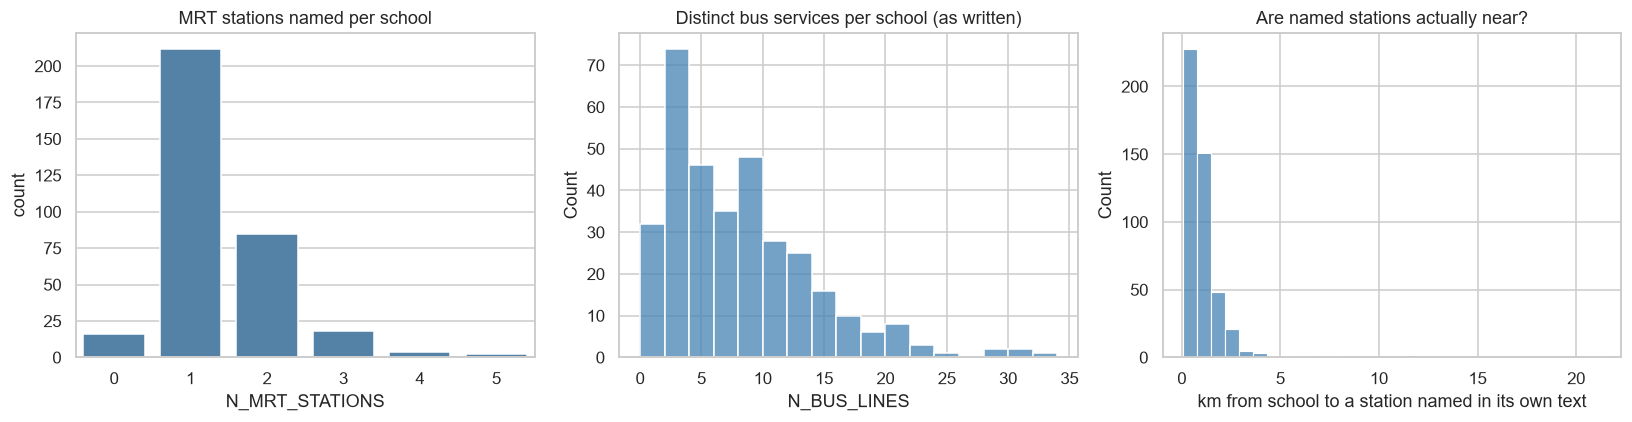

In [142]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.countplot(data=schools, x="N_MRT_STATIONS", color="steelblue", ax=axes[0])
axes[0].set_title("MRT stations named per school")
sns.histplot(schools["N_BUS_LINES"], bins=range(0, 36, 2), color="steelblue", ax=axes[1])
axes[1].set_title("Distinct bus services per school (as written)")
sns.histplot(pairs["dist_m"] / 1000, bins=30, color="steelblue", ax=axes[2])
axes[2].set_xlabel("km from school to a station named in its own text")
axes[2].set_title("Are named stations actually near?")
plt.tight_layout()
plt.show()

#### 5d. Manual coordinate corrections (team-verified)

The team looked up 8 schools by hand (school website / address): the 5 `COORD_SUSPECT` rows really were wrong, and 3
rows that shared coordinates with them were imprecise and got refined. One pair (`gan eng seng primary school`
/ `gan eng seng school`) was checked and is **not** an error — the two campuses are genuinely close together — so it
is left as-is and stays flagged as `COORD_SHARED` only.

| School | What was wrong | Fix |
|---|---|---|
| Methodist Girls' School (Primary/Secondary) | Coordinates copied from the Paya Lebar campus (Hougang) | Moved back to 11 Blackmore Drive, Bukit Timah |
| Paya Lebar Methodist Girls' School (Primary/Secondary) | Right area, coordinates just imprecise | Refined to 298 Lorong Ah Soo / 296 Lor Ah Soo |
| St. Anthony's Primary School | Coordinates copied from St. Anthony's Canossian Primary (Bedok) | Moved back to 30 Bukit Batok St 32 |
| St. Anthony's Canossian Primary School | Right area, coordinates just imprecise | Refined to 1602 Bedok North Ave 4 |
| Outram Secondary School | `STREET` already lists the new Anchorvale (Sengkang) campus, but coordinates were still the old York Hill campus, 13.6 km away | Moved to the Anchorvale campus |
| Tao Nan School | ~7 km off with no traceable cause | Moved to 49 Marine Crescent |

In [143]:
COORD_FIXES = {
    # NAME (lowercase, matches the cleaned frame) -> (correct LATITUDE, correct LONGITUDE, why)
    "methodist girls' school (primary)": (1.3329, 103.7826,
        "own address is 11 Blackmore Drive (Bukit Timah); coordinates had been copied from the Paya Lebar campus"),
    "methodist girls' school (secondary)": (1.3329, 103.7826,
        "same address as the primary school; same copy error"),
    "paya lebar methodist girls' school (primary)": (1.3505, 103.8851,
        "refinement for 298 Lorong Ah Soo (Hougang); the flagged value was already close"),
    "paya lebar methodist girls' school (secondary)": (1.3508, 103.8855,
        "refinement for 296 Lor Ah Soo (Hougang); the flagged value was already close"),
    "st. anthony's canossian primary school": (1.3343, 103.9411,
        "refinement for 1602 Bedok North Ave 4; the flagged value was already close"),
    "st. anthony's primary school": (1.3645, 103.7492,
        "own address is 30 Bukit Batok St 32; coordinates had been copied from St. Anthony's Canossian Primary (Bedok)"),
    "outram secondary school": (1.3980, 103.8910,
        "STREET already lists the current Anchorvale (Sengkang) campus; coordinates were the old York Hill campus, 13.6 km away"),
    "tao nan school": (1.3050, 103.9113,
        "own address is 49 Marine Crescent; coordinates were ~7 km off with no traceable cause"),
}
# Not fixed: "gan eng seng primary school" / "gan eng seng school" share a coordinate, but both addresses
# (Redhill Close / Henderson Road) are genuinely close together -- team-confirmed not an error, left as-is.

for name, (lat, lon, why) in COORD_FIXES.items():
    mask = schools["NAME"] == name
    assert mask.sum() == 1, f"expected exactly one row for {name!r}"
    before = schools.loc[mask, ["LATITUDE", "LONGITUDE"]].iloc[0]
    schools.loc[mask, "LATITUDE"] = lat
    schools.loc[mask, "LONGITUDE"] = lon
    print(f"{name}: ({before.LATITUDE:.4f}, {before.LONGITUDE:.4f}) -> ({lat}, {lon})  -- {why}")

# the flags were computed before the fix, so re-derive them now that the coordinates have changed
schools["COORD_SHARED"] = schools.duplicated(["LATITUDE", "LONGITUDE"], keep=False)
schools.loc[schools["NAME"].isin(COORD_FIXES), "COORD_SUSPECT"] = False

print("\nremaining COORD_SUSPECT:", int(schools["COORD_SUSPECT"].sum()))
print("remaining COORD_SHARED:", int(schools["COORD_SHARED"].sum()), "rows ->",
      schools.loc[schools["COORD_SHARED"], "NAME"].tolist())

methodist girls' school (primary): (1.3495, 103.8850) -> (1.3329, 103.7826)  -- own address is 11 Blackmore Drive (Bukit Timah); coordinates had been copied from the Paya Lebar campus
methodist girls' school (secondary): (1.3510, 103.8851) -> (1.3329, 103.7826)  -- same address as the primary school; same copy error
paya lebar methodist girls' school (primary): (1.3495, 103.8850) -> (1.3505, 103.8851)  -- refinement for 298 Lorong Ah Soo (Hougang); the flagged value was already close
paya lebar methodist girls' school (secondary): (1.3510, 103.8851) -> (1.3508, 103.8855)  -- refinement for 296 Lor Ah Soo (Hougang); the flagged value was already close
st. anthony's canossian primary school: (1.3347, 103.9412) -> (1.3343, 103.9411)  -- refinement for 1602 Bedok North Ave 4; the flagged value was already close
st. anthony's primary school: (1.3347, 103.9412) -> (1.3645, 103.7492)  -- own address is 30 Bukit Batok St 32; coordinates had been copied from St. Anthony's Canossian Primary (Bed


remaining COORD_SUSPECT: 0
remaining COORD_SHARED: 4 rows -> ['gan eng seng primary school', 'gan eng seng school', "methodist girls' school (primary)", "methodist girls' school (secondary)"]


#### 5e. Judgment calls and what stays imperfect

- **Named ≠ nearest.** These lists are what MOE chose to write. A school can name a station 1.5 km away and omit a nearer
  one. The count is a rough signal, not a distance; distances should come from the coordinates.
- **Planned stations.** Some named stations are `planned` in the MRT table; `N_MRT_STATIONS` counts all named, `N_MRT_STATIONS_OPEN` only open ones.
- **MRT/LRT hubs.** The MRT table merges hubs (`bukit panjang mrt/lrt station`), so `bukit panjang lrt` maps to the hub, not to the LRT list.
- **LRT list is hand-written** (not from a source file) and only used to recognise names; it is not joined to any coordinates.
- **Bus counts are not comparable across schools.** Lists range from one service to 33 depending on how much the school wrote;
  3 rows with `000` padding are truncated at source. Use `N_BUS_LINES` as a weak feature at most. A real measure needs
  bus-stop data (LTA) which this project does not have.
- **Bus numbers inside MRT text** (`transfer bus no.63`) are removed from the MRT parse and not added to the bus list.
- **Coordinate errors are corrected in 5d**; the two Gan Eng Seng schools stay flagged `COORD_SHARED`.
- **Two-campus text** (`york hill campus ... anchorvale campus`) is merged into one list for that school.

### 6. School mix and geography


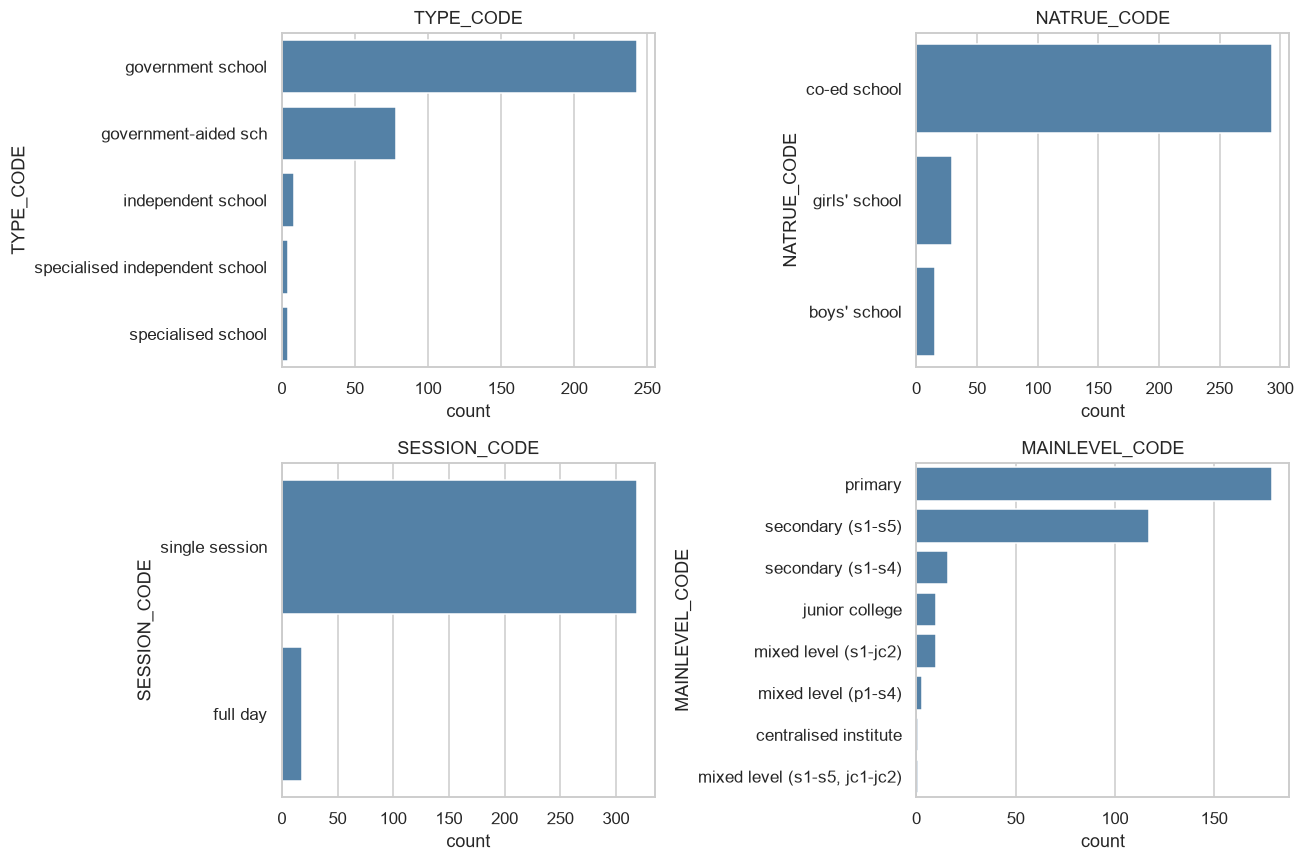

In [144]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, col in zip(axes.ravel(), ["TYPE_CODE", "NATRUE_CODE", "SESSION_CODE", "MAINLEVEL_CODE"]):
    order = schools[col].value_counts().index
    sns.countplot(data=schools, y=col, order=order, ax=ax, color="steelblue")
    ax.set_title(col)
plt.tight_layout()
plt.show()


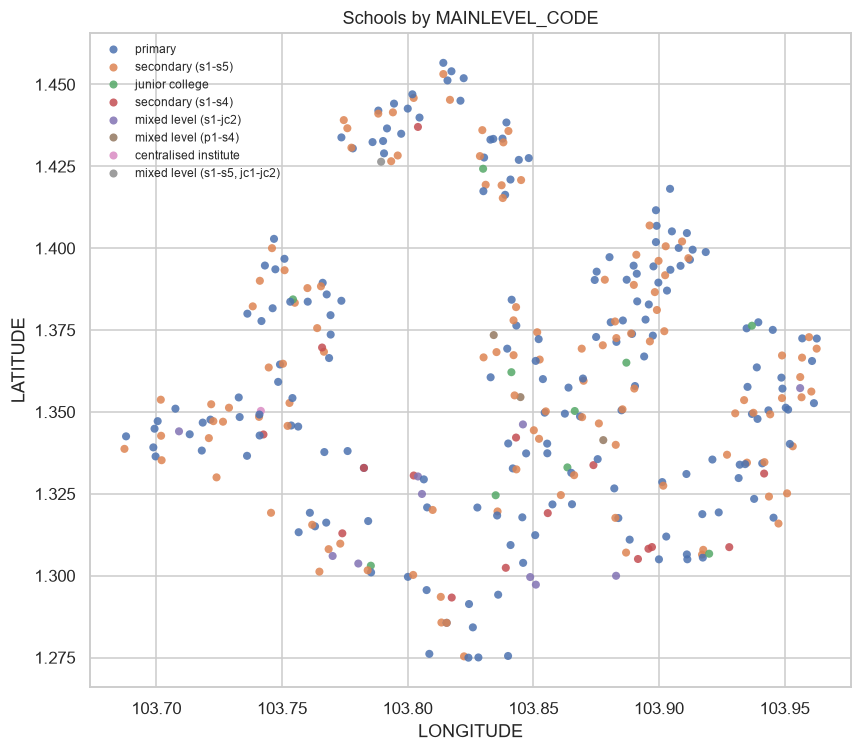

In [145]:
fig, ax = plt.subplots(figsize=(8, 7))
sns.scatterplot(
    data=schools, x="LONGITUDE", y="LATITUDE", hue="MAINLEVEL_CODE",
    s=28, linewidth=0, alpha=0.85, ax=ax,
)
ax.set_title("Schools by MAINLEVEL_CODE")
ax.legend(loc="upper left", fontsize=8, frameon=False)
plt.tight_layout()
plt.show()


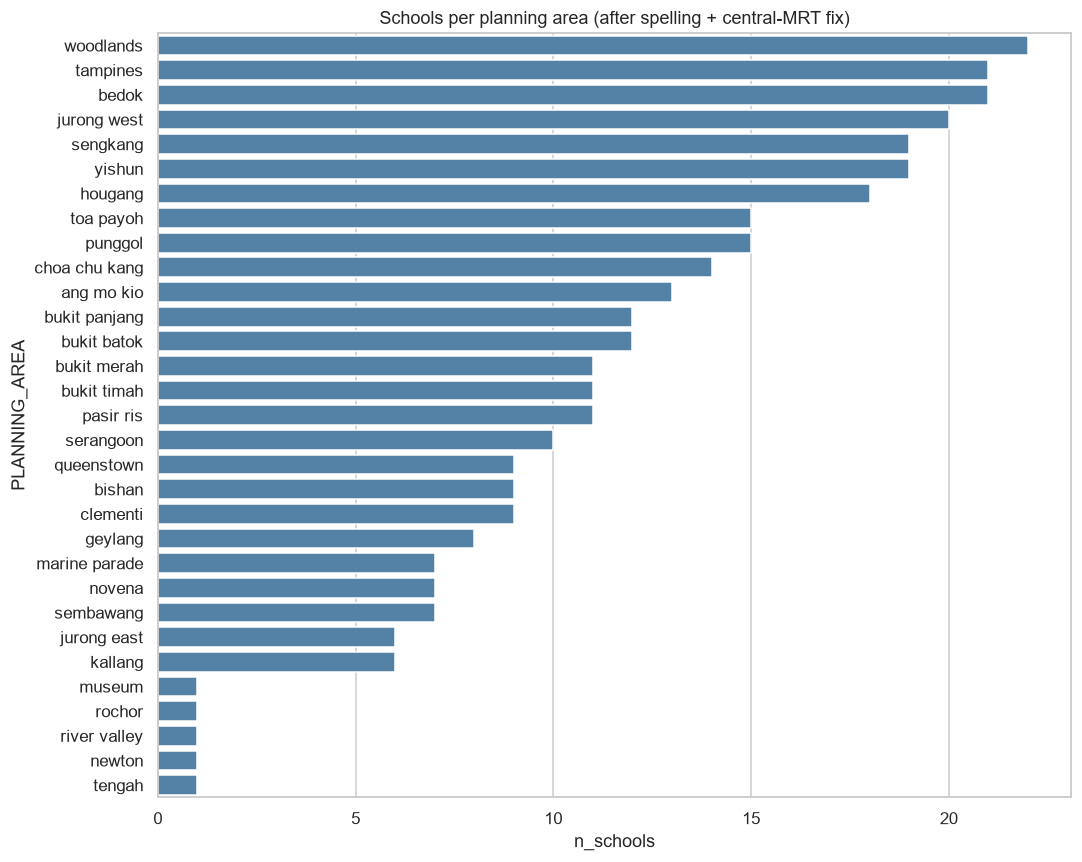

,PLANNING_AREA,n_schools
29,woodlands,22
26,tampines,21
1,bedok,21
12,jurong west,20
24,sengkang,19
30,yishun,19
10,hougang,18
28,toa payoh,15
19,punggol,15
7,choa chu kang,14


In [146]:
area = (
    schools.groupby("PLANNING_AREA").size()
    .rename("n_schools").reset_index()
    .sort_values("n_schools", ascending=False)
)
fig, ax = plt.subplots(figsize=(10, 8))
sns.barplot(data=area, y="PLANNING_AREA", x="n_schools", ax=ax, color="steelblue")
ax.set_title("Schools per planning area (after spelling + central-MRT fix)")
plt.tight_layout()
plt.show()
area.head(10)


### 7. Area-level school features


In [147]:
school_features = schools.groupby("PLANNING_AREA").agg(
    n_schools_total=("NAME", "count"),
    n_schools_primary=("MAINLEVEL_CODE", lambda s: s.str.contains("primary", na=False).sum()),
    n_schools_secondary=("MAINLEVEL_CODE", lambda s: s.str.contains("secondary", na=False).sum()),
    n_schools_government=("TYPE_CODE", lambda s: s.str.contains("government", na=False).sum()),
).reset_index()
school_features.sort_values("n_schools_total", ascending=False).head(10)


,PLANNING_AREA,n_schools_total,n_schools_primary,n_schools_secondary,n_schools_government
29,woodlands,22,12,9,20
26,tampines,21,11,9,21
1,bedok,21,11,9,21
12,jurong west,20,10,9,20
24,sengkang,19,12,7,19
30,yishun,19,10,8,19
10,hougang,18,9,8,18
28,toa payoh,15,7,6,14
19,punggol,15,11,4,15
7,choa chu kang,14,8,5,14


### 8. Summary

- **Grain:** 337 schools, unique `NAME`, no missing cells on the raw file.
- **Join key:** `PLANNING_AREA`, after `seng kang` → `sengkang` and the 4 `central` schools
  remapped via nearest MRT. `REGION` is the URA 5-region, so it now matches HDB/MRT with no
  alias map.
- **`STREET_NAME`:** house number stripped so the column matches HDB `STREET`.
- **`NATRUE_CODE`:** source typo; values are co-ed / girls / boys.
- **`MRT_STATIONS`:** parsed into `MRT_STATIONS_CLEAN` (`;`-separated names from the MRT table),
  `LRT_STATIONS_CLEAN`, `N_MRT_STATIONS`, `N_MRT_STATIONS_OPEN`, `N_LRT_STATIONS` and a `MRT_PARSE_FLAG`. Names were
  checked against the school coordinates and the station codes quoted in the text (5c).
- **`BUS_LINES`:** parsed into `BUS_LINES_CLEAN` (`;`-separated services) and `N_BUS_LINES`; address numbers, stop ids,
  times and `000` padding were removed before extracting services. Counts are not comparable across schools (5e).
- **Coordinates:** the station-distance check found 5 schools with wrong coordinates (copied from a same-named school, or an
outdated campus address) and 3 with imprecise ones. The team looked all 8 up by hand and fixed them in 5d; one further flagged pair
  (Gan Eng Seng Primary/Secondary) was checked and confirmed **not** an error.
- The raw columns are kept next to the parsed ones. Neither is used as a feature in Part 1.6.
- **Zero-school HDB areas** after the fix: `changi`, `downtown core`, `outram` and `tanglin` stay empty; `rochor` picks up School of the Arts.
- **Next:** Part 1.6 (1 km primary counts and RMSE).


In [148]:
schools.to_csv(CLEANED / "sg_schools_cleaned.csv", index=False)
school_features.to_csv(OUT / "school_features_by_area.csv", index=False)
print("wrote", CLEANED / "sg_schools_cleaned.csv", schools.shape)
print("wrote", OUT / "school_features_by_area.csv", school_features.shape)


wrote ..\cleaned\sg_schools_cleaned.csv (337, 27)
wrote ..\outputs\school_features_by_area.csv (31, 5)


## Part 1.6. Feature RMSE check (one time holdout)

Fit Jan 2021 to Dec 2023, score Jan 2024 to Mar 2025 (inside train, test has no labels).
Models: Linear Regression and LightGBM (`n_estimators=400`, `learning_rate=0.05`,
`num_leaves=31`). ΔRMSE = RMSE(BASE) − RMSE(this set). Positive = better.

BASE: `FLOOR_AREA_SQM`, `LEASE_COMMENCE_DATE`, `MONTH_INDEX`, `TOWN`, `FLAT_TYPE`,
`FLAT_MODEL`. BASE RMSE: LR 657, LightGBM 496.4.

1. Build block-level distance features
2. Time split and BASE
3. Fit helpers
4. One extra feature
5. Combinations
6. Drop the 11 incomplete-info blocks?
7. Picture
8. Verdict


In [149]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import lightgbm as lgb
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110

ROOT = Path("..") if Path("../data").exists() else Path(".")
DATA, CLEANED, OUT = ROOT / "data", ROOT / "cleaned", ROOT / "outputs"
OUT_DIR = OUT
OUT.mkdir(parents=True, exist_ok=True)
TARGET = "MONTHLY_RENT"
KEY = ["TOWN", "BLOCK", "STREET"]
CUT = pd.Timestamp("2024-01-01")


### 1. Block-level distance features

Haversine count of primary schools and **unique open** MRT station names within 1 km
of each HDB block. Planned stations are excluded.


In [150]:
def lower_strip(df):
    out = df.copy()
    text = out.select_dtypes(include=["object", "string"]).columns
    out[text] = out[text].apply(lambda s: s.astype(str).str.strip().str.lower())
    return out


def haversine_km(lat1, lon1, lat2, lon2):
    r = 6371.0
    p1, p2 = np.radians(lat1), np.radians(lat2)
    dlat, dlon = np.radians(lat2 - lat1), np.radians(lon2 - lon1)
    a = np.sin(dlat / 2) ** 2 + np.cos(p1) * np.cos(p2) * np.sin(dlon / 2) ** 2
    return 2 * r * np.arcsin(np.sqrt(a))


def count_within_1km(block_lat, block_lon, poi_lat, poi_lon):
    d = haversine_km(
        block_lat[:, None], block_lon[:, None], poi_lat[None, :], poi_lon[None, :]
    )
    return (d <= 1.0).sum(axis=1)


train = pd.read_csv(DATA / "train.csv")
hdb = pd.read_csv(CLEANED / "sg_hdb_block_cleaned.csv")
mrt = pd.read_csv(CLEANED / "sg_mrt_stations_cleaned.csv")
schools = pd.read_csv(CLEANED / "sg_schools_cleaned.csv")
mrt_area = pd.read_csv(OUT / "mrt_features_by_area.csv")
school_area = pd.read_csv(OUT / "school_features_by_area.csv")

primary = schools[schools["MAINLEVEL_CODE"].str.contains("primary", na=False)]
mrt_open = mrt.loc[mrt["STATUS"].eq("open"), ["NAME", "LATITUDE", "LONGITUDE"]].drop_duplicates("NAME")

hdb = hdb.copy()
hdb["n_primary_within_1km"] = count_within_1km(
    hdb["LATITUDE"].to_numpy(), hdb["LONGITUDE"].to_numpy(),
    primary["LATITUDE"].to_numpy(), primary["LONGITUDE"].to_numpy(),
)
hdb["n_mrt_within_1km"] = count_within_1km(
    hdb["LATITUDE"].to_numpy(), hdb["LONGITUDE"].to_numpy(),
    mrt_open["LATITUDE"].to_numpy(), mrt_open["LONGITUDE"].to_numpy(),
)
print("primary schools:", len(primary), "  unique open MRT names:", len(mrt_open))
print(hdb[["n_primary_within_1km", "n_mrt_within_1km"]].describe().T)


primary schools: 179   unique open MRT names: 192
                         count  mean   std   min   25%   50%   75%    max
n_primary_within_1km 9,464.000 3.029 1.561 0.000 2.000 3.000 4.000 10.000
n_mrt_within_1km     9,464.000 1.553 1.064 0.000 1.000 1.000 2.000 10.000


### 2. Analysis frame, time split, BASE

`FURNISHED` and `FEE` are constant and dropped. Flat type `"4 room"` / `"4-room"` is one
category. Text is lowercased before the HDB join.

BASE numerics: `FLOOR_AREA_SQM`, `LEASE_COMMENCE_DATE`, `MONTH_INDEX`.
BASE categoricals: `TOWN`, `FLAT_TYPE`, `FLAT_MODEL`.


In [151]:
def clean_rent(df):
    out = lower_strip(df)
    out["FLAT_TYPE"] = out["FLAT_TYPE"].str.replace(r"[\s\-]+", "-", regex=True)
    out["RENT_APPROVAL_DATE"] = pd.to_datetime(out["RENT_APPROVAL_DATE"], format="%Y-%m")
    out["MONTH_INDEX"] = (out["RENT_APPROVAL_DATE"].dt.year - 2021) * 12 + out["RENT_APPROVAL_DATE"].dt.month - 1
    out["APPROVAL_YEAR"] = out["RENT_APPROVAL_DATE"].dt.year
    return out.drop(columns=["FURNISHED", "FEE"], errors="ignore")


df = clean_rent(train).merge(
    hdb[KEY + [
        "MAX_FLOOR", "YEAR_COMPLETED", "PLANNING_AREA", "MISSING_BUILDING_INFO",
        "n_primary_within_1km", "n_mrt_within_1km",
    ]],
    on=KEY, how="left",
)
df = df.merge(mrt_area, on="PLANNING_AREA", how="left")
df = df.merge(school_area, on="PLANNING_AREA", how="left")
df["BUILDING_AGE_AT_RENT"] = df["APPROVAL_YEAR"] - df["YEAR_COMPLETED"]

fit = df[df["RENT_APPROVAL_DATE"] < CUT].copy()
val = df[df["RENT_APPROVAL_DATE"] >= CUT].copy()
print(f"fit {fit['RENT_APPROVAL_DATE'].min().date()} .. {fit['RENT_APPROVAL_DATE'].max().date()}  n={len(fit):,}")
print(f"val {val['RENT_APPROVAL_DATE'].min().date()} .. {val['RENT_APPROVAL_DATE'].max().date()}  n={len(val):,}")
print("SERS-flagged rows in fit / val:", int(fit["MISSING_BUILDING_INFO"].sum()), "/", int(val["MISSING_BUILDING_INFO"].sum()))

BASE_NUM = ["FLOOR_AREA_SQM", "LEASE_COMMENCE_DATE", "MONTH_INDEX"]
BASE_CAT = ["TOWN", "FLAT_TYPE", "FLAT_MODEL"]


fit 2021-01-01 .. 2023-12-01  n=105,837
val 2024-01-01 .. 2025-03-01  n=44,163
SERS-flagged rows in fit / val: 159 / 0


### 3. Fit helpers

Linear Regression: median-impute numerics, one-hot categoricals. That median fill only
touches extra numerics in the spec (for example `MAX_FLOOR`). LightGBM: native
categoricals, missing numerics left as NaN. Height is not filled in the HDB table.


In [152]:
def rmse(y, p):
    return float(np.sqrt(mean_squared_error(y, p)))


def fit_lr(fit_df, val_df, extra):
    num, cat = BASE_NUM + [c for c in extra if c not in BASE_CAT], BASE_CAT
    f, v = fit_df, val_df
    pre = ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), num),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat),
    ])
    pipe = Pipeline([("pre", pre), ("m", LinearRegression())])
    pipe.fit(f[num + cat], f[TARGET])
    return rmse(v[TARGET], pipe.predict(v[num + cat]))


def fit_lgb(fit_df, val_df, extra):
    cols = BASE_NUM + extra + BASE_CAT
    f, v = fit_df, val_df
    Xf, Xv = f[cols].copy(), v[cols].copy()
    for c in BASE_CAT:
        Xf[c] = Xf[c].astype("category")
        Xv[c] = pd.Categorical(Xv[c], categories=Xf[c].cat.categories)
    model = lgb.LGBMRegressor(
        n_estimators=400, learning_rate=0.05, num_leaves=31,
        verbose=-1, n_jobs=-1, random_state=0,
    )
    model.fit(Xf, f[TARGET], categorical_feature=BASE_CAT)
    return rmse(v[TARGET], model.predict(Xv))


def eval_spec(name, extra, fit_df=None, val_df=None):
    fit_df = fit if fit_df is None else fit_df
    val_df = val if val_df is None else val_df
    lr = fit_lr(fit_df, val_df, extra)
    gb = fit_lgb(fit_df, val_df, extra)
    return {"spec": name, "extra": extra, "lr": lr, "lgb": gb}


base = eval_spec("BASE", [])
print(f"BASE  LR={base['lr']:.3f}  LightGBM={base['lgb']:.3f}")


BASE  LR=657.120  LightGBM=496.366


### 4. One extra feature at a time


In [153]:
SINGLES = [
    ("+ MAX_FLOOR", ["MAX_FLOOR"]),
    ("+ YEAR_COMPLETED", ["YEAR_COMPLETED"]),
    ("+ BUILDING_AGE_AT_RENT", ["BUILDING_AGE_AT_RENT"]),
    ("+ n_primary_within_1km", ["n_primary_within_1km"]),
    ("+ n_mrt_within_1km", ["n_mrt_within_1km"]),
    ("+ n_schools_total", ["n_schools_total"]),
    ("+ n_schools_primary", ["n_schools_primary"]),
    ("+ n_schools_secondary", ["n_schools_secondary"]),
    ("+ n_schools_government", ["n_schools_government"]),
    ("+ n_mrt_open", ["n_mrt_open"]),
    ("+ n_mrt_planned", ["n_mrt_planned"]),
    ("+ n_distinct_lines", ["n_distinct_lines"]),
    ("+ n_interchange_stations", ["n_interchange_stations"]),
    ("+ school density (4)", ["n_schools_total", "n_schools_primary", "n_schools_secondary", "n_schools_government"]),
    ("+ MRT density (4)", ["n_mrt_open", "n_mrt_planned", "n_distinct_lines", "n_interchange_stations"]),
]

rows = [base] + [eval_spec(n, e) for n, e in SINGLES]
singles = pd.DataFrame(rows)
singles["d_lr"] = base["lr"] - singles["lr"]
singles["d_lgb"] = base["lgb"] - singles["lgb"]
singles[["spec", "lr", "d_lr", "lgb", "d_lgb"]]


,spec,lr,d_lr,lgb,d_lgb
0,BASE,657.120,0.000,496.366,0.000
1,+ MAX_FLOOR,656.272,0.848,496.153,0.213
2,+ YEAR_COMPLETED,657.115,0.005,497.209,-0.843
3,+ BUILDING_AGE_AT_RENT,657.631,-0.511,498.465,-2.099
4,+ n_primary_within_1km,657.077,0.042,496.832,-0.466
5,+ n_mrt_within_1km,656.382,0.738,495.982,0.384
6,+ n_schools_total,657.040,0.080,497.365,-0.999
7,+ n_schools_primary,657.026,0.094,497.444,-1.078
8,+ n_schools_secondary,657.020,0.100,495.838,0.529
9,+ n_schools_government,657.017,0.103,498.053,-1.686


### 5. Combinations


In [154]:
COMBOS = [
    ("MAX_FLOOR + n_primary_within_1km", ["MAX_FLOOR", "n_primary_within_1km"]),
    ("MAX_FLOOR + n_mrt_within_1km", ["MAX_FLOOR", "n_mrt_within_1km"]),
    ("MAX_FLOOR + n_primary_within_1km + n_mrt_within_1km", ["MAX_FLOOR", "n_primary_within_1km", "n_mrt_within_1km"]),
    ("three + YEAR_COMPLETED", ["MAX_FLOOR", "n_primary_within_1km", "n_mrt_within_1km", "YEAR_COMPLETED"]),
    ("three + BUILDING_AGE_AT_RENT", ["MAX_FLOOR", "n_primary_within_1km", "n_mrt_within_1km", "BUILDING_AGE_AT_RENT"]),
    ("MAX_FLOOR + YEAR_COMPLETED", ["MAX_FLOOR", "YEAR_COMPLETED"]),
    ("three + area school+MRT counts", [
        "MAX_FLOOR", "n_primary_within_1km", "n_mrt_within_1km",
        "n_schools_total", "n_schools_primary", "n_schools_secondary", "n_schools_government",
        "n_mrt_open", "n_mrt_planned", "n_distinct_lines", "n_interchange_stations",
    ]),
]

rows_c = [eval_spec(n, e) for n, e in COMBOS]
combos = pd.DataFrame(rows_c)
combos["d_lr"] = base["lr"] - combos["lr"]
combos["d_lgb"] = base["lgb"] - combos["lgb"]
combos[["spec", "lr", "d_lr", "lgb", "d_lgb"]]


,spec,lr,d_lr,lgb,d_lgb
0,MAX_FLOOR + n_primary_within_1km,656.211,0.909,496.022,0.344
1,MAX_FLOOR + n_mrt_within_1km,655.587,1.533,495.097,1.270
2,MAX_FLOOR + n_primary_within_1km + n_mrt_withi...,655.574,1.546,494.501,1.866
3,three + YEAR_COMPLETED,655.538,1.582,494.932,1.435
4,three + BUILDING_AGE_AT_RENT,656.370,0.750,494.970,1.396
5,MAX_FLOOR + YEAR_COMPLETED,656.208,0.912,495.311,1.055
6,three + area school+MRT counts,655.494,1.626,494.065,2.301


### 6. Drop the 11 incomplete-info blocks from **training** only?

Same validation rows (val has 0 of these SERS listings). If dropping helps, Δ vs keep is
positive. Decision uses the BASE drop: throwing the rows out should not help.


In [155]:
fit_keep, val_same = fit, val
fit_drop = fit[~fit["MISSING_BUILDING_INFO"]].copy()
print(f"fit keep={len(fit_keep):,}  drop={len(fit_drop):,}  val={len(val_same):,}")

sers = pd.DataFrame([
    eval_spec("BASE, keep SERS rows", [], fit_keep, val_same),
    eval_spec("BASE, drop SERS from fit", [], fit_drop, val_same),
    eval_spec("BASE+MAX_FLOOR, keep", ["MAX_FLOOR"], fit_keep, val_same),
    eval_spec("BASE+MAX_FLOOR, drop from fit", ["MAX_FLOOR"], fit_drop, val_same),
])
sers["d_lr_vs_keep"] = [np.nan, sers.loc[0, "lr"] - sers.loc[1, "lr"], np.nan, sers.loc[2, "lr"] - sers.loc[3, "lr"]]
sers["d_lgb_vs_keep"] = [np.nan, sers.loc[0, "lgb"] - sers.loc[1, "lgb"], np.nan, sers.loc[2, "lgb"] - sers.loc[3, "lgb"]]
sers[["spec", "lr", "d_lr_vs_keep", "lgb", "d_lgb_vs_keep"]]


fit keep=105,837  drop=105,678  val=44,163


,spec,lr,d_lr_vs_keep,lgb,d_lgb_vs_keep
0,"BASE, keep SERS rows",657.120,NaN,496.366,NaN
1,"BASE, drop SERS from fit",657.393,-0.273,498.853,-2.487
2,"BASE+MAX_FLOOR, keep",656.272,NaN,496.153,NaN
3,"BASE+MAX_FLOOR, drop from fit",656.553,-0.281,495.830,0.324


### 7. Picture of LightGBM Δ vs BASE


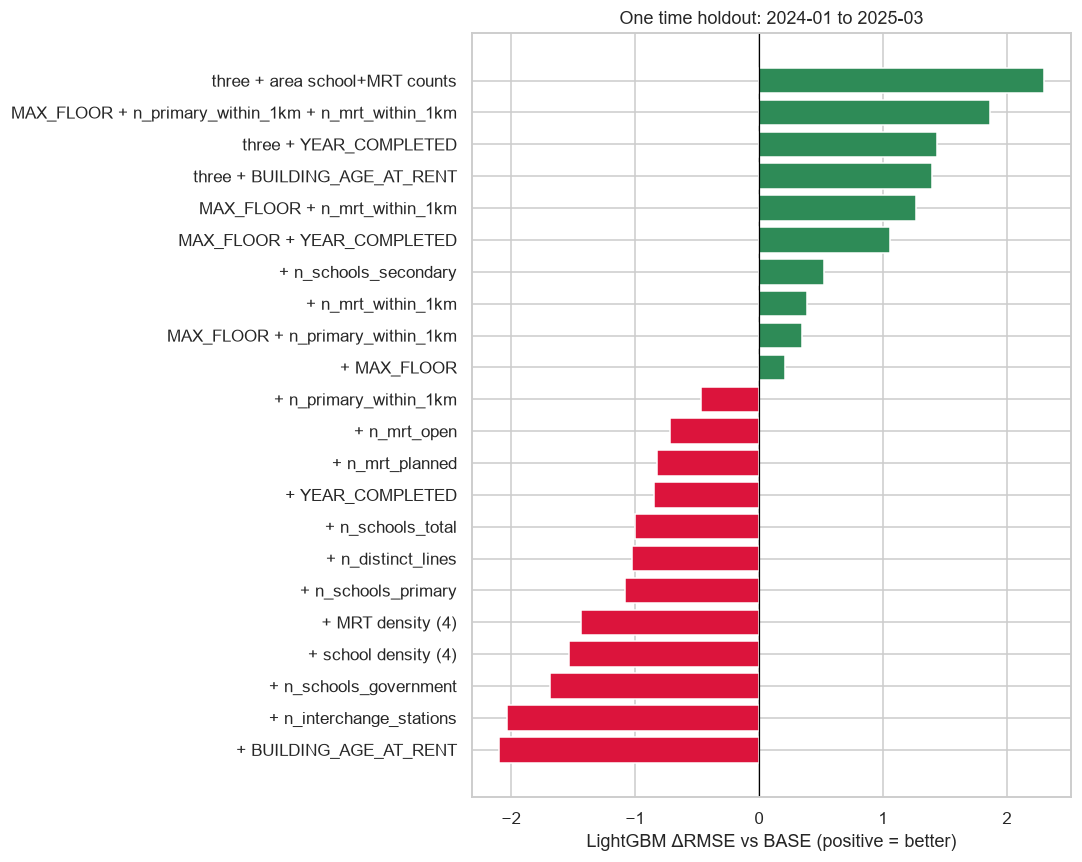

In [156]:
plot = pd.concat([singles, combos], ignore_index=True)
plot = plot[plot["spec"] != "BASE"].sort_values("d_lgb")
fig, ax = plt.subplots(figsize=(10, 8))
colors = np.where(plot["d_lgb"] >= 0, "seagreen", "crimson")
ax.barh(plot["spec"], plot["d_lgb"], color=colors)
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("LightGBM ΔRMSE vs BASE (positive = better)")
ax.set_title("One time holdout: 2024-01 to 2025-03")
plt.tight_layout()
plt.show()


### 8. Verdict

- Keep the three if they beat BASE on LightGBM and beat the 1–2 feature stacks.
- Skip `YEAR_COMPLETED` / `BUILDING_AGE_AT_RENT` if they are worse vs BASE, and adding
  them to the three does not help.
- Skip area-level school/MRT counts if they are worse vs BASE, and what they add on
  top of the three does not justify the 8 extra columns.
- Keep the 11 SERS rows if dropping them from the BASE fit hurts.


In [157]:
def flag(delta, good="add", bad="skip"):
    if delta > 0.15:
        return good
    if delta < -0.15:
        return bad
    return "flat"


three = combos.set_index("spec").loc["MAX_FLOOR + n_primary_within_1km + n_mrt_within_1km"]
yc = singles.set_index("spec").loc["+ YEAR_COMPLETED"]
age = singles.set_index("spec").loc["+ BUILDING_AGE_AT_RENT"]
sch = singles.set_index("spec").loc["+ school density (4)"]
mrt4 = singles.set_index("spec").loc["+ MRT density (4)"]
drop_base = sers.iloc[1]["d_lgb_vs_keep"]

verdict = pd.DataFrame([
    {"claim": "Add MAX_FLOOR + n_primary_within_1km + n_mrt_within_1km",
     "lgb_delta": three["d_lgb"], "check": flag(three["d_lgb"], "supported", "not supported")},
    {"claim": "Do not add YEAR_COMPLETED",
     "lgb_delta": yc["d_lgb"], "check": flag(-yc["d_lgb"], "supported", "revisit") if yc["d_lgb"] <= 0.15 else "revisit (it helped)"},
    {"claim": "Do not add BUILDING_AGE_AT_RENT",
     "lgb_delta": age["d_lgb"], "check": flag(-age["d_lgb"], "supported", "revisit") if age["d_lgb"] <= 0.15 else "revisit (it helped)"},
    {"claim": "Do not add area-level school counts",
     "lgb_delta": sch["d_lgb"], "check": flag(-sch["d_lgb"], "supported", "revisit") if sch["d_lgb"] <= 0.15 else "revisit (it helped)"},
    {"claim": "Do not add area-level MRT counts",
     "lgb_delta": mrt4["d_lgb"], "check": flag(-mrt4["d_lgb"], "supported", "revisit") if mrt4["d_lgb"] <= 0.15 else "revisit (it helped)"},
    {"claim": "Keep the 11 SERS blocks in training",
     "lgb_delta": drop_base, "check": "supported (dropping BASE fit hurts)" if drop_base < -0.15 else "revisit"},
])
verdict.to_csv(OUT / "feature_rmse_verdict.csv", index=False)
pd.concat([singles, combos], ignore_index=True).to_csv(OUT / "feature_rmse_holdout.csv", index=False)
verdict


,claim,lgb_delta,check
0,Add MAX_FLOOR + n_primary_within_1km + n_mrt_w...,1.866,supported
1,Do not add YEAR_COMPLETED,-0.843,supported
2,Do not add BUILDING_AGE_AT_RENT,-2.099,supported
3,Do not add area-level school counts,-1.534,supported
4,Do not add area-level MRT counts,-1.438,supported
5,Keep the 11 SERS blocks in training,-2.487,supported (dropping BASE fit hurts)


#### What this holdout actually showed

LightGBM BASE RMSE ≈ **496.4** (LR 657). Δ = BASE − this set. Positive = better.
One split: fit Jan 2021 to Dec 2023, score Jan 2024 to Mar 2025.

**What works:** keep `MAX_FLOOR`, `n_primary_within_1km`, and `n_mrt_within_1km` (Δ **+1.87**).

**What to skip on their own:** completion year, building age, and area-level totals — all but
`n_schools_secondary` land below BASE by themselves, and both grouped sets do, since `TOWN` already soaks up broad neighborhood effects. Stacked
*on top of* the three, area totals add a further +0.44 — real, but small, and not worth 8
extra columns.

**Keep the SERS rows:** they do not appear in validation, but dropping them from the BASE
fit costs **−2.49**. Leave height as NaN. LightGBM does not fill it. Linear Regression
only fills a median when `MAX_FLOOR` is in that spec.

Net impact: about **$1.87** off the LightGBM RMSE.

*(See Part 1.7 for distance-based features.)*

## Part 1.7. Distance-based features

This part follows up Part 1.6's 1 km counts with distance-based features:

| # | Section | Question |
|---|---|---|
| 0 | Recap: how we cleaned HDB / MRT / Schools, and the Part 1.6 result | settled in Part 1.6: keep the three |
| 1 | New data: Shopping Malls & Hawker Centres (point-only, no join key) | usable how? |
| 2 | Building the distance features: 500&nbsp;m / 1&nbsp;km / 2&nbsp;km counts, nearest distance, CBD distance | what do we add? |
| 3 | Visualizing them | how do they look? |
| 4 | Quick RMSE test of everything new | which radius wins, which ones make the cut |
| 5 | Summary & open questions | what is left open |

Part 1.6 tested only a flat 1 km count for primary schools and MRT stations. Here we test a
couple of radii, add a
nearest-distance version of each, and bring in the Shopping Malls and Hawker Centres tables as new amenities.

In [158]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
plt.rcParams["figure.dpi"] = 110

ROOT = Path("..") if Path("../data").exists() else Path(".")
DATA, CLEANED, OUT = ROOT / "data", ROOT / "cleaned", ROOT / "outputs"
FIG_DIR = OUT / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
TARGET = "MONTHLY_RENT"
KEY = ["TOWN", "BLOCK", "STREET"]
CUT = pd.Timestamp("2024-01-01")

# categorical colour palette, extended with two more slots
COLOR_MRT = "#2a78d6"      # slot 1 (existing team convention)
COLOR_SCHOOL = "#eb6834"   # slot 2 (existing team convention)
COLOR_MALL = "#2e9e6b"     # slot 3 (new)
COLOR_CBD = "#7a5cc9"      # slot 4 (new)
COLOR_HAWKER = "#7a5cc9"   # reuses slot 4 -- CBD is a single reference point, never a colored series itself
INK, INK_SECONDARY, INK_MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, BASELINE, SURFACE = "#e1e0d9", "#c3c2b7", "#fcfcfb"
GOOD, BAD = "seagreen", "crimson"


def haversine_km(lat1, lon1, lat2, lon2):
    r = 6371.0
    p1, p2 = np.radians(lat1), np.radians(lat2)
    dlat, dlon = np.radians(lat2 - lat1), np.radians(lon2 - lon1)
    a = np.sin(dlat / 2) ** 2 + np.cos(p1) * np.cos(p2) * np.sin(dlon / 2) ** 2
    return 2 * r * np.arcsin(np.sqrt(a))


def lower_strip(df):
    out = df.copy()
    text = out.select_dtypes(include=["object", "string"]).columns
    out[text] = out[text].apply(lambda s: s.astype(str).str.strip().str.lower())
    return out


hdb = pd.read_csv(CLEANED / "sg_hdb_block_cleaned.csv")
mrt = pd.read_csv(CLEANED / "sg_mrt_stations_cleaned.csv")
schools = pd.read_csv(CLEANED / "sg_schools_cleaned.csv")
train = pd.read_csv(DATA / "train.csv")
print("hdb blocks:", hdb.shape, " mrt rows:", mrt.shape, " schools:", schools.shape, " train:", train.shape)

hdb blocks: (9464, 12)  mrt rows: (243, 10)  schools: (337, 27)  train: (150000, 11)


### 0. Recap: how we cleaned the data, and what Part 1.6 found

How each dataset was cleaned, and what that cleaning let us test in Part 1.6. Quick overview only; the full investigation for each is in Part 1.3,
Part 1.4 and Part 1.5.

**HDB blocks** (`sg-hdb-block.csv`, 9,464 rows)
- Joined onto train/test on lowercased `(TOWN, BLOCK, STREET)` — 100% match.
- The source uses `-1` as a sentinel for unknown `MAX_FLOOR` / `YEAR_COMPLETED`, not `NaN`. Replaced with real `NaN`.
- Exactly 11 blocks are missing both fields — all 11 turned out to be **SERS** sites (blocks slated for demolition/relocation), confirmed against three known SERS clusters, not a data bug.

In [159]:
print(f"SERS-flagged blocks (MISSING_BUILDING_INFO): {hdb['MISSING_BUILDING_INFO'].sum()}")
hdb.loc[hdb["MISSING_BUILDING_INFO"], ["TOWN", "STREET", "BLOCK"]].sort_values(["TOWN", "STREET"]).head(11)

SERS-flagged blocks (MISSING_BUILDING_INFO): 11


,TOWN,STREET,BLOCK
4113,clementi,west coast road,518
5391,clementi,west coast road,514
5525,clementi,west coast road,515
6501,clementi,west coast road,513
8238,clementi,west coast road,519
8244,clementi,west coast road,520
3400,geylang,macpherson lane,82
4385,queenstown,commonwealth drive,63
5550,queenstown,commonwealth drive,55
2859,queenstown,tanglin halt road,30


**Earlier result (Part 1.6): dropping these 11 blocks from training didn't help.** The obvious move once
we saw incomplete rows was to just drop them: none of the 11 ever show up in the validation window
anyway, so it looked "free." The holdout said otherwise.

In [160]:
verdict = pd.read_csv(OUT / "feature_rmse_verdict.csv")
verdict[verdict["claim"].str.contains("SERS")]

,claim,lgb_delta,check
5,Keep the 11 SERS blocks in training,-2.487,supported (dropping BASE fit hurts)


**The initial assumption was wrong.** Since none of the 11 SERS blocks appear in validation, we expected
removing their 159 training rows to be a non-event for validation error. It cost **−2.49** on LightGBM
instead. Here's why: the 159 rows aren't lost in isolation, they're a real chunk of a specific, narrow
corner of the training data.

In [161]:
sers_blocks = hdb.loc[hdb["MISSING_BUILDING_INFO"], ["TOWN", "STREET", "BLOCK"]]


def _clean_rent_inline(df):
    # small local version -- the real clean_rent() (with MONTH_INDEX etc.) is built in section 4
    out = lower_strip(df)
    out["FLAT_TYPE"] = out["FLAT_TYPE"].str.replace(r"[\s\-]+", "-", regex=True)
    out["RENT_APPROVAL_DATE"] = pd.to_datetime(out["RENT_APPROVAL_DATE"], format="%Y-%m")
    return out


fit_check = _clean_rent_inline(train)
fit_check = fit_check[fit_check["RENT_APPROVAL_DATE"] < CUT]
fit_check = fit_check.merge(hdb[["TOWN", "BLOCK", "STREET", "MISSING_BUILDING_INFO"]], on=KEY, how="left")
sers_fit = fit_check[fit_check["MISSING_BUILDING_INFO"] == True]

print(f"SERS rows in the fit window: {len(sers_fit)} of {len(fit_check):,} ({len(sers_fit)/len(fit_check):.2%})")
print("\nspread across towns:", sers_blocks["TOWN"].value_counts().to_dict())
print("\nFLAT_TYPE of SERS rows:")
print(sers_fit["FLAT_TYPE"].value_counts())
print(f"\nSERS lease years: {int(sers_fit['LEASE_COMMENCE_DATE'].min())}-{int(sers_fit['LEASE_COMMENCE_DATE'].max())}"
      f"   |   overall fit median lease year: {int(fit_check['LEASE_COMMENCE_DATE'].median())}")

# how big a share of their own narrow (town, flat type) corner are the SERS rows?
seg = fit_check[(fit_check["TOWN"] == "clementi") & (fit_check["FLAT_TYPE"] == "3-room")]
print(f"\nclementi 3-room rows: {len(seg)} total, {int(seg['MISSING_BUILDING_INFO'].sum())} of them SERS "
      f"({seg['MISSING_BUILDING_INFO'].mean():.1%})")

SERS rows in the fit window: 159 of 105,837 (0.15%)

spread across towns: {'clementi': 6, 'queenstown': 4, 'geylang': 1}

FLAT_TYPE of SERS rows:
FLAT_TYPE
3-room    149
4-room      9
2-room      1
Name: count, dtype: int64

SERS lease years: 1968-1986   |   overall fit median lease year: 1988

clementi 3-room rows: 2298 total, 115 of them SERS (5.0%)


**What this shows:** 78% of the SERS rows (124 of 159) are in Clementi, and 94% of them are `3-room`
flats with leases from 1968-1986 — among the oldest in the whole training set (overall median lease year is
1988). They're 5% of the *entire* "Clementi 3-room" training slice.

Removing them doesn't erase a prediction target — it erases part of what teaches the model how `TOWN`,
`FLAT_TYPE`, and `LEASE_COMMENCE_DATE` combine to set rent for old 3-room flats in Clementi specifically.
Clementi has plenty of *other* 3-room flats in validation that are not SERS sites — they still benefit from
whatever the model learned about "old 3-room Clementi flats" during training, so thinning that signal by 5%
hurts them too, even though no SERS block itself is ever scored.

One more wrinkle: this only holds when `MAX_FLOOR` is **not** in the model. Add `MAX_FLOOR`, and dropping
SERS barely matters (+0.32, i.e. flips slightly positive) — plausibly because `MAX_FLOOR` is `NaN` for
every SERS row by construction (that's *why* they're flagged), so once the model has a feature that's
missing exactly on the rows being removed, the extra town/lease signal they carried is mostly cancelled
out by how LightGBM handles that missingness. Net call is still the same either way: keep the rows, leave
`MAX_FLOOR` as `NaN` for them, don't drop anything.

**MRT stations** (`sg-mrt-stations.csv`)
- Parsed the line code and an interchange flag out of the station `CODE` (e.g. `ns10`, `cc1`).
- Kept `planned` stations in the cleaned table, but **excluded** them from any "within X km" count — they don't help anyone commute today.
- Matched to the same URA planning area / region as HDB and Schools, so all three auxiliary tables share one geography.

In [162]:
print(mrt["STATUS"].value_counts().to_string())
print("unique open station names:", mrt.loc[mrt["STATUS"].eq("open"), "NAME"].nunique())
print("rows flagged as an interchange:", int(mrt["IS_INTERCHANGE"].sum()),
      "-> unique interchange station names:",
      mrt.loc[mrt["STATUS"].eq("open") & mrt["IS_INTERCHANGE"], "NAME"].nunique())

STATUS
open       231
planned     12
unique open station names: 192
rows flagged as an interchange: 95 -> unique interchange station names: 44


**Schools** (`sg-schools.csv`, 337 rows)
- `seng kang` → `sengkang` (a genuine spelling variant the HDB crosswalk doesn't use).
- 4 schools labelled `PLANNING_AREA == "central"` (not a real URA area) were reassigned to the planning
  area of their **nearest MRT station**.
- MOE's own 4-zone region was replaced with the same URA 5-region system HDB/MRT use.
- We also fixed **coordinates** (see next cell). `MRT_STATIONS` / `BUS_LINES` (free text)
  were parsed too, but aren't used as model features.

**Fix: schools with copied/wrong coordinates.** The Part 1.5 checks tested
every school's coordinates against its own address and its nearest named MRT station. 8 came
up wrong or imprecise and were looked up by hand and corrected:

| School | Issue | Before (lat, lon) | After (lat, lon) |
|---|---|---|---|
| Methodist Girls' School (Primary) | Coordinates copied from the Paya Lebar campus (Hougang) | 1.3495, 103.8850 | 1.3329, 103.7826 |
| Methodist Girls' School (Secondary) | Same copy error, same address | 1.3510, 103.8851 | 1.3329, 103.7826 |
| Paya Lebar Methodist Girls' School (Primary) | Right campus, coordinates just imprecise | 1.3495, 103.8850 | 1.3505, 103.8851 |
| Paya Lebar Methodist Girls' School (Secondary) | Right campus, coordinates just imprecise | 1.3510, 103.8851 | 1.3508, 103.8855 |
| St. Anthony's Primary School | Coordinates copied from St. Anthony's Canossian Primary (Bedok) | 1.3347, 103.9412 | 1.3645, 103.7492 |
| St. Anthony's Canossian Primary School | Right campus, coordinates just imprecise | 1.3347, 103.9412 | 1.3343, 103.9411 |
| Outram Secondary School | `STREET` already lists the new Anchorvale (Sengkang) campus; coordinates were still the old York Hill campus, 13.6 km away | 1.2865, 103.8371 | 1.3980, 103.8910 |
| Tao Nan School | ~7 km off with no traceable cause | 1.2943, 103.8490 | 1.3050, 103.9113 |

One further look-alike pair (the two Gan Eng Seng schools, which *do* share a coordinate) was checked and
confirmed genuinely close together, not an error, so left as-is. Full detail (how each was found and why) is
in Part 1.5, section 5d.

In [163]:
primary = schools[schools["MAINLEVEL_CODE"].str.contains("primary", na=False)]
secondary = schools[schools["MAINLEVEL_CODE"].str.contains("secondary", na=False)]
print(f"schools: {len(schools)}  (primary: {len(primary)}, secondary: {len(secondary)})")
print("coordinates flagged wrong before the Part 1.5 fix, now corrected: 8  |  checked and left as-is: 2 (Gan Eng Seng)")

schools: 337  (primary: 179, secondary: 133)
coordinates flagged wrong before the Part 1.5 fix, now corrected: 8  |  checked and left as-is: 2 (Gan Eng Seng)


**Putting it together: the Part 1.6 overall result.**

**Split:** fit Jan 2021 – Dec 2023, validate Jan 2024 – Mar 2025.
**Baseline features:** floor area, lease-commence year, month index, town, flat type, flat model.
**Baseline RMSE:** LR \$657 · LightGBM \$496.4. Δ = RMSE(BASE) − RMSE(this set); positive = better.

Loading the holdout straight from `outputs/feature_rmse_holdout.csv` (written by Part 1.6); no need to refit anything to show it again.

In [164]:
holdout = pd.read_csv(OUT / "feature_rmse_holdout.csv")
holdout[["spec", "lr", "lgb", "d_lgb"]].round(3)

,spec,lr,lgb,d_lgb
0,BASE,657.120,496.366,0.000
1,+ MAX_FLOOR,656.272,496.153,0.213
2,+ YEAR_COMPLETED,657.115,497.209,-0.843
3,+ BUILDING_AGE_AT_RENT,657.631,498.465,-2.099
4,+ n_primary_within_1km,657.077,496.832,-0.466
5,+ n_mrt_within_1km,656.382,495.982,0.384
6,+ n_schools_total,657.040,497.365,-0.999
7,+ n_schools_primary,657.026,497.444,-1.078
8,+ n_schools_secondary,657.020,495.838,0.529
9,+ n_schools_government,657.017,498.053,-1.686


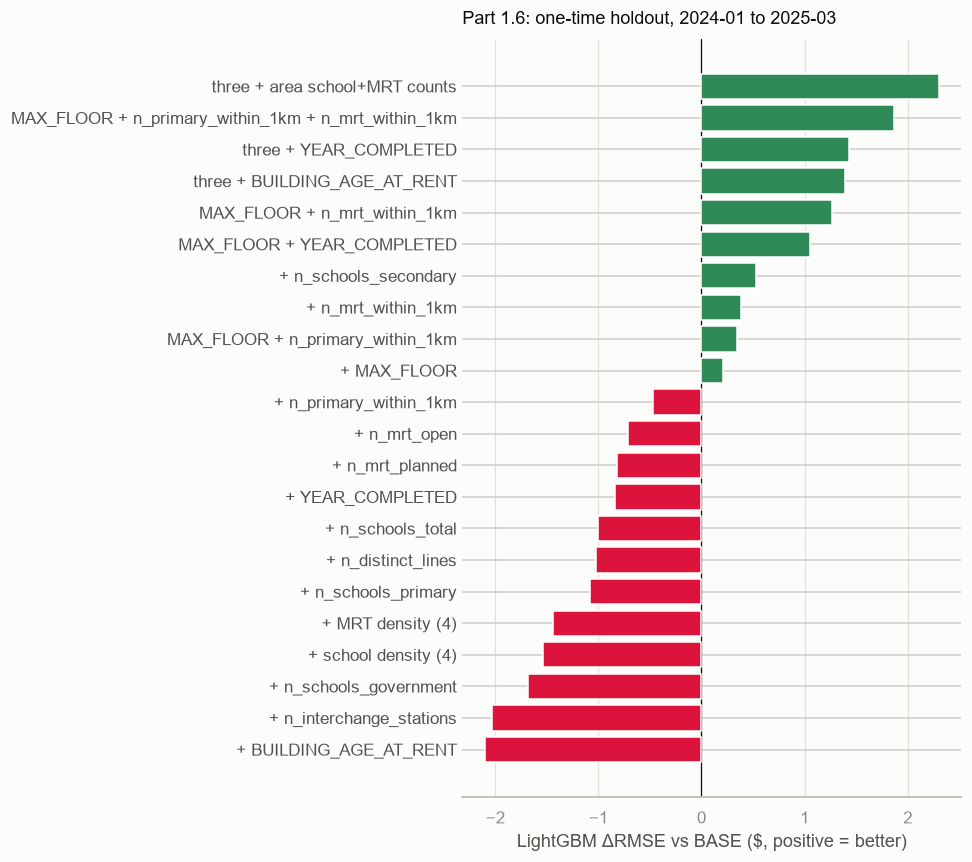

,claim,lgb_delta,check
0,Add MAX_FLOOR + n_primary_within_1km + n_mrt_w...,1.866,supported
1,Do not add YEAR_COMPLETED,-0.843,supported
2,Do not add BUILDING_AGE_AT_RENT,-2.099,supported
3,Do not add area-level school counts,-1.534,supported
4,Do not add area-level MRT counts,-1.438,supported
5,Keep the 11 SERS blocks in training,-2.487,supported (dropping BASE fit hurts)


In [165]:
plot = holdout[holdout["spec"] != "BASE"].sort_values("d_lgb")
fig, ax = plt.subplots(figsize=(9, 8))
fig.patch.set_facecolor(SURFACE); ax.set_facecolor(SURFACE)
ax.barh(plot["spec"], plot["d_lgb"], color=np.where(plot["d_lgb"] >= 0, GOOD, BAD), zorder=3)
ax.axvline(0, color=INK, lw=0.8)
ax.set_xlabel("LightGBM ΔRMSE vs BASE ($, positive = better)", color=INK_SECONDARY)
ax.set_title("Part 1.6: one-time holdout, 2024-01 to 2025-03", color=INK, fontsize=12, loc="left", pad=10)
for s in ["top", "right", "left"]:
    ax.spines[s].set_visible(False)
ax.spines["bottom"].set_color(BASELINE)
ax.tick_params(axis="y", length=0, colors=INK_SECONDARY)
ax.tick_params(axis="x", colors=INK_MUTED)
ax.xaxis.grid(True, color=GRID, linewidth=0.8, zorder=0)
ax.set_axisbelow(True)
plt.tight_layout()
plt.savefig(FIG_DIR / "part1_7_recap.png", dpi=150, bbox_inches="tight")
plt.show()
verdict

**Key takeaways**

- **Keep:** `MAX_FLOOR`, `n_primary_within_1km`, `n_mrt_within_1km` together; they beat BASE on LightGBM.
- **`YEAR_COMPLETED` / `BUILDING_AGE_AT_RENT`:** skip, both land *below* BASE on their own.
- **Area-level school/MRT totals** (`n_schools_total`, `n_mrt_open`, etc.): skip **on their own**. Added
  alone to BASE they're worse than BASE (except `n_schools_secondary`), because `TOWN` already carries most of that signal (see the
  `singles` rows in `feature_rmse_holdout.csv`). Stacked *on top of* the three, they do add a little
  (`three + area school+MRT counts` row above), but it's a small gain, not worth the extra 8 columns.
- **Keep the 11 SERS rows in training** (see above).

Everything below builds on top of this: the three features above are the new baseline (call it
`REFERENCE`) that any new distance feature has to beat.

### 1. New data — Shopping Malls

`sg-shopping-malls.csv` is much thinner than the other three tables: **just `NAME`, `LATITUDE`,
`LONGITUDE`** — no address, no planning area, no postal code. That rules out an area-level feature
table like `mrt_features_by_area.csv` / `school_features_by_area.csv` — there's no key to group by.
The only thing we can do with it is **pure point-to-point distance**: nearest mall, or how many malls
sit within some radius of a block.

In [166]:
malls = pd.read_csv(DATA / "auxiliary" / "sg-shopping-malls.csv")
malls = lower_strip(malls)
print("shape:", malls.shape)
print("duplicate names:", malls["NAME"].duplicated().sum(),
      " duplicate coordinates:", malls.duplicated(["LATITUDE", "LONGITUDE"]).sum())
print("missing cells:", int(malls.isna().sum().sum()))
print("in Singapore's bounding box:",
      bool(malls["LATITUDE"].between(1.13, 1.47).all() and malls["LONGITUDE"].between(103.6, 104.1).all()))
malls.head(3)

shape: (113, 3)
duplicate names: 0  duplicate coordinates: 0
missing cells: 0
in Singapore's bounding box: True


,NAME,LATITUDE,LONGITUDE
0,alexandra retail centre,1.274,103.801
1,bugis junction,1.299,103.855
2,bugis+,1.298,103.856


113 malls, no missing cells, no duplicates, all inside Singapore's bounding box — clean enough to use as-is, no separate cleaning needed.

### 1b. New data: Hawker Centres

We also sourced `HawkerCentresGEOJSON.geojson` (NEA's `SSOT_HAWKERCENTRES` dataset) as a further
candidate amenity. It's a GeoJSON, not a CSV: each row is
a `Point` feature with a big properties block (address, stall count, construction status, even a photo
URL). Point-only again, like malls, but with a genuine `STATUS` field this time, worth checking before
just using every row.

In [167]:
import json

with open(DATA / "auxiliary" / "HawkerCentresGEOJSON.geojson") as f:
    hawker_raw = json.load(f)

hawker = pd.json_normalize([feat["properties"] for feat in hawker_raw["features"]])
hawker["LONGITUDE"] = [feat["geometry"]["coordinates"][0] for feat in hawker_raw["features"]]
hawker["LATITUDE"] = [feat["geometry"]["coordinates"][1] for feat in hawker_raw["features"]]
hawker = lower_strip(hawker)

print("shape:", hawker.shape)
print("STATUS values:\n", hawker["STATUS"].value_counts().to_string())
print("\nduplicate names:", hawker["NAME"].duplicated().sum(),
      " duplicate coordinates:", hawker.duplicated(["LATITUDE", "LONGITUDE"]).sum())
print("missing NAME/LATITUDE/LONGITUDE:", int(hawker[["NAME", "LATITUDE", "LONGITUDE"]].isna().sum().sum()))
print("in Singapore's bounding box:",
      bool(hawker["LATITUDE"].between(1.13, 1.47).all() and hawker["LONGITUDE"].between(103.6, 104.1).all()))
hawker[["NAME", "ADDRESSSTREETNAME", "STATUS", "NUMBER_OF_COOKED_FOOD_STALLS"]].head(3)

shape: (129, 22)
STATUS values:
 STATUS
existing                  103
existing (new)             16
under construction          6
existing (replacement)      3
interim centre              1

duplicate names: 0  duplicate coordinates: 0
missing NAME/LATITUDE/LONGITUDE: 0
in Singapore's bounding box: True


,NAME,ADDRESSSTREETNAME,STATUS,NUMBER_OF_COOKED_FOOD_STALLS
0,commonwealth crescent market,commonwealth crescent,existing,39
1,tiong bahru market,seng poh road,existing,83
2,golden mile food centre,beach road,existing,112


129 hawker centres, no missing names/coordinates, no duplicates, all in-bounds. `STATUS` has 5
values — the one that matters is **"Under Construction"** (6 rows): those aren't usable by residents yet,
same reasoning as excluding `planned` MRT stations. The rest (`Existing`, `Existing (new)`,
`Existing (replacement)`, `Interim Centre`) are all open today, so they count as "open" here.

In [168]:
hawker_open = hawker.loc[hawker["STATUS"] != "under construction", ["NAME", "LATITUDE", "LONGITUDE"]]
print(f"open hawker centres: {len(hawker_open)} of {len(hawker)}")

open hawker centres: 123 of 129


### 2. Building the distance features

One helper, reused for every amenity type: build the full block × amenity distance matrix once
(cheap: at most 9,464 × 337), then read off the nearest distance and three radius counts from it.

**Amenity groups:** primary schools, secondary schools, open MRT stations, open MRT *interchange*
stations, shopping malls, open hawker centres, and one single reference point for **distance to the CBD**
(Raffles Place MRT, a classic Singapore rent predictor, and free to add since we already have its
coordinates).

**Radii tested:** 500 m, 1 km (the Part 1.6 choice), 2 km.

In [169]:
RADII_KM = {"500m": 0.5, "1km": 1.0, "2km": 2.0}


def poi_distance_features(hdb_lat, hdb_lon, poi_lat, poi_lon):
    d = haversine_km(hdb_lat[:, None], hdb_lon[:, None], poi_lat[None, :], poi_lon[None, :])
    out = {"nearest_km": d.min(axis=1)}
    for label, r in RADII_KM.items():
        out[f"within_{label}"] = (d <= r).sum(axis=1)
    return out


mrt_open = mrt.loc[mrt["STATUS"].eq("open"), ["NAME", "LATITUDE", "LONGITUDE"]].drop_duplicates("NAME")
mrt_interchange = mrt.loc[
    mrt["STATUS"].eq("open") & mrt["IS_INTERCHANGE"], ["NAME", "LATITUDE", "LONGITUDE"]
].drop_duplicates("NAME")
CBD_LAT, CBD_LON = mrt.loc[mrt["NAME"].eq("raffles place mrt station"), ["LATITUDE", "LONGITUDE"]].iloc[0]

POI_GROUPS = {
    "primary": primary,
    "secondary": secondary,
    "mrt": mrt_open,
    "mrt_interchange": mrt_interchange,
    "malls": malls,
    "hawker": hawker_open,
}

hdb_lat, hdb_lon = hdb["LATITUDE"].to_numpy(), hdb["LONGITUDE"].to_numpy()
for prefix, poi in POI_GROUPS.items():
    feats = poi_distance_features(hdb_lat, hdb_lon, poi["LATITUDE"].to_numpy(), poi["LONGITUDE"].to_numpy())
    for suffix, values in feats.items():
        hdb[f"{prefix}_{suffix}"] = values

hdb["dist_to_cbd_km"] = haversine_km(hdb_lat, hdb_lon, CBD_LAT, CBD_LON)
hdb["log_mrt_nearest_km"] = np.log1p(hdb["mrt_nearest_km"])

print(f"amenity counts used  ->  primary: {len(primary)}  secondary: {len(secondary)}  "
      f"open MRT: {len(mrt_open)}  MRT interchanges: {len(mrt_interchange)}  malls: {len(malls)}  "
      f"open hawker centres: {len(hawker_open)}")
new_cols = [c for c in hdb.columns if any(c.startswith(p + "_") for p in POI_GROUPS) or c.startswith("dist_to_cbd") or c.startswith("log_mrt")]
hdb[new_cols].describe().T.round(2)

amenity counts used  ->  primary: 179  secondary: 133  open MRT: 192  MRT interchanges: 44  malls: 113  open hawker centres: 123


,count,mean,std,min,25%,50%,75%,max
primary_nearest_km,"9,464.000",0.420,0.250,0.020,0.240,0.370,0.530,3.310
primary_within_500m,"9,464.000",0.990,0.810,0.000,0.000,1.000,1.000,4.000
primary_within_1km,"9,464.000",3.030,1.560,0.000,2.000,3.000,4.000,10.000
primary_within_2km,"9,464.000",8.420,3.510,0.000,6.000,8.000,10.000,20.000
secondary_nearest_km,"9,464.000",0.550,0.350,0.050,0.300,0.460,0.680,3.520
secondary_within_500m,"9,464.000",0.670,0.680,0.000,0.000,1.000,1.000,4.000
secondary_within_1km,"9,464.000",2.100,1.240,0.000,1.000,2.000,3.000,6.000
secondary_within_2km,"9,464.000",6.120,2.400,0.000,5.000,6.000,8.000,13.000
mrt_nearest_km,"9,464.000",0.630,0.340,0.020,0.390,0.570,0.800,2.570
mrt_within_500m,"9,464.000",0.440,0.560,0.000,0.000,0.000,1.000,5.000


### 3. Visualizing the new features

#### 3a. How far is the nearest one, typically?

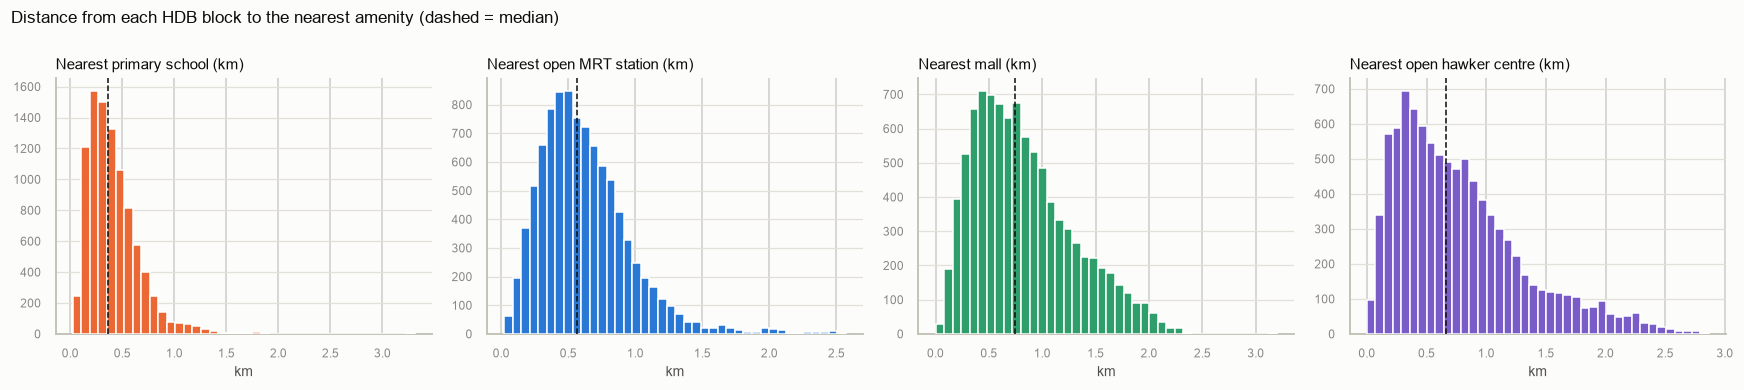

primary_nearest_km   0.365
mrt_nearest_km       0.568
malls_nearest_km     0.747
hawker_nearest_km    0.666
Name: median km, dtype: float64

In [170]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.6), sharey=False)
fig.patch.set_facecolor(SURFACE)
specs = [("primary_nearest_km", "Nearest primary school (km)", COLOR_SCHOOL),
         ("mrt_nearest_km", "Nearest open MRT station (km)", COLOR_MRT),
         ("malls_nearest_km", "Nearest mall (km)", COLOR_MALL),
         ("hawker_nearest_km", "Nearest open hawker centre (km)", COLOR_HAWKER)]
for ax, (col, title, c) in zip(axes, specs):
    ax.set_facecolor(SURFACE)
    ax.hist(hdb[col], bins=40, color=c, zorder=3)
    ax.axvline(hdb[col].median(), color=INK, lw=1, ls="--", zorder=4)
    ax.set_title(title, color=INK, fontsize=10, loc="left")
    ax.set_xlabel("km", color=INK_SECONDARY, fontsize=9)
    for s in ["top", "right"]:
        ax.spines[s].set_visible(False)
    ax.spines["bottom"].set_color(BASELINE); ax.spines["left"].set_color(BASELINE)
    ax.tick_params(colors=INK_MUTED, labelsize=8)
    ax.yaxis.grid(True, color=GRID, linewidth=0.8, zorder=0)
    ax.set_axisbelow(True)
fig.suptitle("Distance from each HDB block to the nearest amenity (dashed = median)", color=INK, fontsize=11, x=0.01, ha="left")
plt.tight_layout()
plt.savefig(FIG_DIR / "part1_7_nearest_hist.png", dpi=150, bbox_inches="tight")
plt.show()
hdb[["primary_nearest_km", "mrt_nearest_km", "malls_nearest_km", "hawker_nearest_km"]].median().rename("median km")

#### 3b. Does a bigger radius actually pick up meaningfully more amenities?

The question here: is 1 km the right cut, or should we test 500 m / 2 km too?

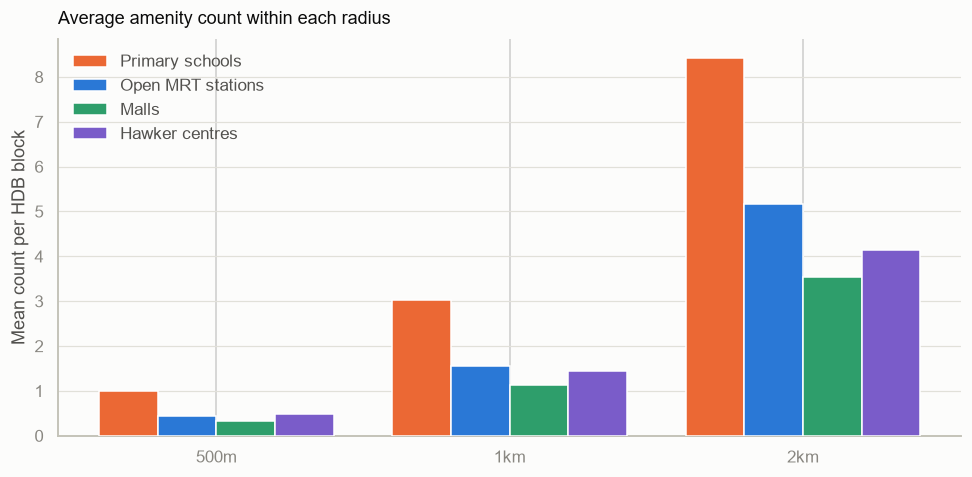

radius,1km,2km,500m
amenity,,,
Hawker centres,1.450,4.140,0.490
Malls,1.130,3.550,0.320
Open MRT stations,1.550,5.160,0.440
Primary schools,3.030,8.420,0.990


In [171]:
radius_summary = pd.DataFrame({
    "amenity": ["Primary schools"] * 3 + ["Open MRT stations"] * 3 + ["Malls"] * 3 + ["Hawker centres"] * 3,
    "radius": list(RADII_KM) * 4,
    "mean_count": [hdb[f"primary_within_{r}"].mean() for r in RADII_KM]
                 + [hdb[f"mrt_within_{r}"].mean() for r in RADII_KM]
                 + [hdb[f"malls_within_{r}"].mean() for r in RADII_KM]
                 + [hdb[f"hawker_within_{r}"].mean() for r in RADII_KM],
})

fig, ax = plt.subplots(figsize=(9, 4.5))
fig.patch.set_facecolor(SURFACE); ax.set_facecolor(SURFACE)
amenity_colors = {"Primary schools": COLOR_SCHOOL, "Open MRT stations": COLOR_MRT, "Malls": COLOR_MALL, "Hawker centres": COLOR_HAWKER}
radii_order = list(RADII_KM)
x = np.arange(len(radii_order))
bar_w = 0.2
n_series = len(amenity_colors)
for i, (name, color) in enumerate(amenity_colors.items()):
    vals = radius_summary.loc[radius_summary["amenity"] == name].set_index("radius").loc[radii_order, "mean_count"]
    ax.bar(x + (i - (n_series - 1) / 2) * bar_w, vals, width=bar_w, color=color, label=name, zorder=3)
ax.set_xticks(x); ax.set_xticklabels(radii_order, color=INK_SECONDARY)
ax.set_ylabel("Mean count per HDB block", color=INK_SECONDARY)
ax.set_title("Average amenity count within each radius", color=INK, fontsize=12, loc="left", pad=10)
for s in ["top", "right"]:
    ax.spines[s].set_visible(False)
ax.spines["bottom"].set_color(BASELINE); ax.spines["left"].set_color(BASELINE)
ax.tick_params(colors=INK_MUTED)
ax.yaxis.grid(True, color=GRID, linewidth=0.8, zorder=0)
ax.set_axisbelow(True)
ax.legend(frameon=False, loc="upper left", labelcolor=INK_SECONDARY)
plt.tight_layout()
plt.savefig(FIG_DIR / "part1_7_radius_compare.png", dpi=150, bbox_inches="tight")
plt.show()
radius_summary.pivot(index="amenity", columns="radius", values="mean_count").round(2)

500 m is sparse for all four (many blocks see 0 primary schools, 0 malls, or 0 hawker centres that
close — hawker centres in particular are built one per estate, not one per street). 2 km roughly triples
all four counts. Whether
"more" is actually *better* for the model is a different question — that's what the RMSE test in
section 4 is for.

### 4. Quick RMSE test: same one-time holdout as Part 1.6

Same split (fit Jan 2021–Dec 2023, validate Jan 2024–Mar 2025), same two models. This time the
reference point isn't bare BASE: it's **`REFERENCE` = BASE + `MAX_FLOOR` + `n_primary_within_1km` +
`n_mrt_within_1km`**, i.e. everything already kept in Part 1.6. The question for each row below
is: does this new feature earn its place *on top of* what we already decided to keep?

In [172]:
def clean_rent(df):
    out = lower_strip(df)
    out["FLAT_TYPE"] = out["FLAT_TYPE"].str.replace(r"[\s\-]+", "-", regex=True)
    out["RENT_APPROVAL_DATE"] = pd.to_datetime(out["RENT_APPROVAL_DATE"], format="%Y-%m")
    out["MONTH_INDEX"] = (out["RENT_APPROVAL_DATE"].dt.year - 2021) * 12 + out["RENT_APPROVAL_DATE"].dt.month - 1
    return out.drop(columns=["FURNISHED", "FEE"], errors="ignore")


# rename to the exact names Part 1.6 already used, so REFERENCE matches Part 1.6 exactly
hdb_join = hdb.rename(columns={"primary_within_1km": "n_primary_within_1km", "mrt_within_1km": "n_mrt_within_1km"})
DIST_COLS = [c for c in hdb_join.columns if c not in [
    "TOWN", "BLOCK", "STREET", "POSTAL_CODE", "LATITUDE", "LONGITUDE",
    "MAX_FLOOR", "YEAR_COMPLETED", "SUBZONE", "PLANNING_AREA", "REGION", "MISSING_BUILDING_INFO",
]]

df = clean_rent(train).merge(hdb_join[KEY + ["MAX_FLOOR", "MISSING_BUILDING_INFO"] + DIST_COLS], on=KEY, how="left")
fit_df = df[df["RENT_APPROVAL_DATE"] < CUT].copy()
val_df = df[df["RENT_APPROVAL_DATE"] >= CUT].copy()
print(f"fit n={len(fit_df):,}   val n={len(val_df):,}")

BASE_NUM = ["FLOOR_AREA_SQM", "LEASE_COMMENCE_DATE", "MONTH_INDEX"]
BASE_CAT = ["TOWN", "FLAT_TYPE", "FLAT_MODEL"]
REFERENCE = ["MAX_FLOOR", "n_primary_within_1km", "n_mrt_within_1km"]


def rmse(y, p):
    return float(np.sqrt(mean_squared_error(y, p)))


def fit_lr(f, v, extra):
    num, cat = BASE_NUM + [c for c in extra if c not in BASE_CAT], BASE_CAT
    pre = ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), num),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat),
    ])
    pipe = Pipeline([("pre", pre), ("m", LinearRegression())])
    pipe.fit(f[num + cat], f[TARGET])
    return rmse(v[TARGET], pipe.predict(v[num + cat]))


def fit_lgb(f, v, extra):
    cols = BASE_NUM + extra + BASE_CAT
    Xf, Xv = f[cols].copy(), v[cols].copy()
    for c in BASE_CAT:
        Xf[c] = Xf[c].astype("category")
        Xv[c] = pd.Categorical(Xv[c], categories=Xf[c].cat.categories)
    model = lgb.LGBMRegressor(n_estimators=400, learning_rate=0.05, num_leaves=31, verbose=-1, n_jobs=-1, random_state=0)
    model.fit(Xf, f[TARGET], categorical_feature=BASE_CAT)
    return rmse(v[TARGET], model.predict(Xv))


def eval_spec(name, extra):
    return {"spec": name, "lr": fit_lr(fit_df, val_df, extra), "lgb": fit_lgb(fit_df, val_df, extra)}


reference = eval_spec("REFERENCE (Part 1.6's pick)", REFERENCE)
print(f"REFERENCE  LR={reference['lr']:.3f}  LightGBM={reference['lgb']:.3f}")

fit n=105,837   val n=44,163


REFERENCE  LR=655.574  LightGBM=494.501


#### 4a. Does swapping the radius help?

In [173]:
RADIUS_SWAPS = [
    ("500m radius (schools+MRT)", ["MAX_FLOOR", "primary_within_500m", "mrt_within_500m"]),
    ("REFERENCE (1km, Part 1.6)", REFERENCE),
    ("2km radius (schools+MRT)", ["MAX_FLOOR", "primary_within_2km", "mrt_within_2km"]),
]
radius_rows = [eval_spec(n, e) for n, e in RADIUS_SWAPS]
radius_df = pd.DataFrame(radius_rows)
radius_df["d_lgb_vs_reference"] = reference["lgb"] - radius_df["lgb"]
radius_df[["spec", "lr", "lgb", "d_lgb_vs_reference"]]

,spec,lr,lgb,d_lgb_vs_reference
0,500m radius (schools+MRT),654.924,493.885,0.615
1,"REFERENCE (1km, Part 1.6)",655.574,494.501,0.000
2,2km radius (schools+MRT),655.036,493.530,0.970


**Malls and hawker centres weren't part of that test** — they were only ever tested at a fixed
1 km count (section 4b). Does the same 2 km-beats-1 km pattern hold for them too, or is it specific to
schools/MRT? Cheap to check — the 500 m/1 km/2 km columns already exist.

In [174]:
RADIUS_SWAPS_MALLS_HAWKER = [
    ("REFERENCE + malls/hawker @ 500m", REFERENCE + ["malls_within_500m", "hawker_within_500m"]),
    ("REFERENCE + malls/hawker @ 1km", REFERENCE + ["malls_within_1km", "hawker_within_1km"]),
    ("REFERENCE + malls/hawker @ 2km", REFERENCE + ["malls_within_2km", "hawker_within_2km"]),
]
radius_mh_rows = [eval_spec(n, e) for n, e in RADIUS_SWAPS_MALLS_HAWKER]
radius_mh_df = pd.DataFrame(radius_mh_rows)
radius_mh_df["d_lgb_vs_reference"] = reference["lgb"] - radius_mh_df["lgb"]
radius_mh_df[["spec", "lr", "lgb", "d_lgb_vs_reference"]]

,spec,lr,lgb,d_lgb_vs_reference
0,REFERENCE + malls/hawker @ 500m,655.017,493.304,1.197
1,REFERENCE + malls/hawker @ 1km,654.983,494.453,0.048
2,REFERENCE + malls/hawker @ 2km,655.060,493.665,0.836


**It does not generalize — malls/hawker actually prefer the opposite radius.** 500 m wins
(+1.20), 2 km is second (+0.84), and 1 km is the *worst* of the three here (+0.05, basically flat).
That's the reverse of schools/MRT, where 1 km was the worst and 2 km the best. Reading: a mall or
hawker centre is either practically on your doorstep or it isn't — a tight 500 m radius captures that
better than a wide one. Schools/MRT behave more like area-density signals, where a wider net reads the
neighbourhood better. **"Use 2 km" is not a blanket rule — it's specifically a schools/MRT finding.**

#### 4b. New feature types, added on top of REFERENCE

In [175]:
NEW_SINGLES = [
    ("+ dist_nearest_primary_km", REFERENCE + ["primary_nearest_km"]),
    ("+ dist_nearest_mrt_km", REFERENCE + ["mrt_nearest_km"]),
    ("+ log1p(dist_nearest_mrt_km)", REFERENCE + ["log_mrt_nearest_km"]),
    ("+ n_secondary_within_1km", REFERENCE + ["secondary_within_1km"]),
    ("+ n_mrt_interchange_within_1km", REFERENCE + ["mrt_interchange_within_1km"]),
    ("+ dist_nearest_interchange_km", REFERENCE + ["mrt_interchange_nearest_km"]),
    ("+ n_malls_within_1km", REFERENCE + ["malls_within_1km"]),
    ("+ dist_nearest_mall_km", REFERENCE + ["malls_nearest_km"]),
    ("+ n_hawker_within_1km", REFERENCE + ["hawker_within_1km"]),
    ("+ dist_nearest_hawker_km", REFERENCE + ["hawker_nearest_km"]),
    ("+ dist_to_cbd_km", REFERENCE + ["dist_to_cbd_km"]),
]
singles_rows = [eval_spec(n, e) for n, e in NEW_SINGLES]
singles_df = pd.DataFrame(singles_rows)
singles_df["d_lgb_vs_reference"] = reference["lgb"] - singles_df["lgb"]
singles_df[["spec", "lr", "lgb", "d_lgb_vs_reference"]].sort_values("d_lgb_vs_reference", ascending=False)

,spec,lr,lgb,d_lgb_vs_reference
1,+ dist_nearest_mrt_km,654.273,492.234,2.267
2,+ log1p(dist_nearest_mrt_km),654.070,492.234,2.267
0,+ dist_nearest_primary_km,655.530,492.820,1.681
5,+ dist_nearest_interchange_km,654.913,492.946,1.555
7,+ dist_nearest_mall_km,654.472,493.385,1.116
6,+ n_malls_within_1km,655.082,493.442,1.059
9,+ dist_nearest_hawker_km,655.494,493.631,0.870
4,+ n_mrt_interchange_within_1km,655.326,493.700,0.801
10,+ dist_to_cbd_km,655.041,493.909,0.592
3,+ n_secondary_within_1km,655.550,494.234,0.267


#### 4c. Combinations of the promising ones

In [176]:
COMBOS = [
    ("REFERENCE + malls (count + nearest)", REFERENCE + ["malls_within_1km", "malls_nearest_km"]),
    ("REFERENCE + hawker (count + nearest)", REFERENCE + ["hawker_within_1km", "hawker_nearest_km"]),
    ("REFERENCE + dist_to_cbd_km + malls_nearest_km", REFERENCE + ["dist_to_cbd_km", "malls_nearest_km"]),
    ("REFERENCE + nearest_primary + nearest_mrt", REFERENCE + ["primary_nearest_km", "mrt_nearest_km"]),
    ("REFERENCE + everything new (kitchen sink)", REFERENCE + [
        "primary_nearest_km", "mrt_nearest_km", "secondary_within_1km", "mrt_interchange_within_1km",
        "mrt_interchange_nearest_km", "malls_within_1km", "malls_nearest_km",
        "hawker_within_1km", "hawker_nearest_km", "dist_to_cbd_km",
    ]),
    ("REFERENCE + kitchen sink minus bad hawker count", REFERENCE + [
        "primary_nearest_km", "mrt_nearest_km", "secondary_within_1km", "mrt_interchange_within_1km",
        "mrt_interchange_nearest_km", "malls_within_1km", "malls_nearest_km",
        "hawker_nearest_km", "dist_to_cbd_km",
    ]),
]
combos_rows = [eval_spec(n, e) for n, e in COMBOS]
combos_df = pd.DataFrame(combos_rows)
combos_df["d_lgb_vs_reference"] = reference["lgb"] - combos_df["lgb"]
combos_df[["spec", "lr", "lgb", "d_lgb_vs_reference"]]

,spec,lr,lgb,d_lgb_vs_reference
0,REFERENCE + malls (count + nearest),654.454,492.131,2.370
1,REFERENCE + hawker (count + nearest),655.387,493.104,1.397
2,REFERENCE + dist_to_cbd_km + malls_nearest_km,653.997,492.765,1.735
3,REFERENCE + nearest_primary + nearest_mrt,654.270,491.551,2.949
4,REFERENCE + everything new (kitchen sink),652.692,489.968,4.533
5,REFERENCE + kitchen sink minus bad hawker count,652.708,490.312,4.189


#### 4d. Everything on one chart

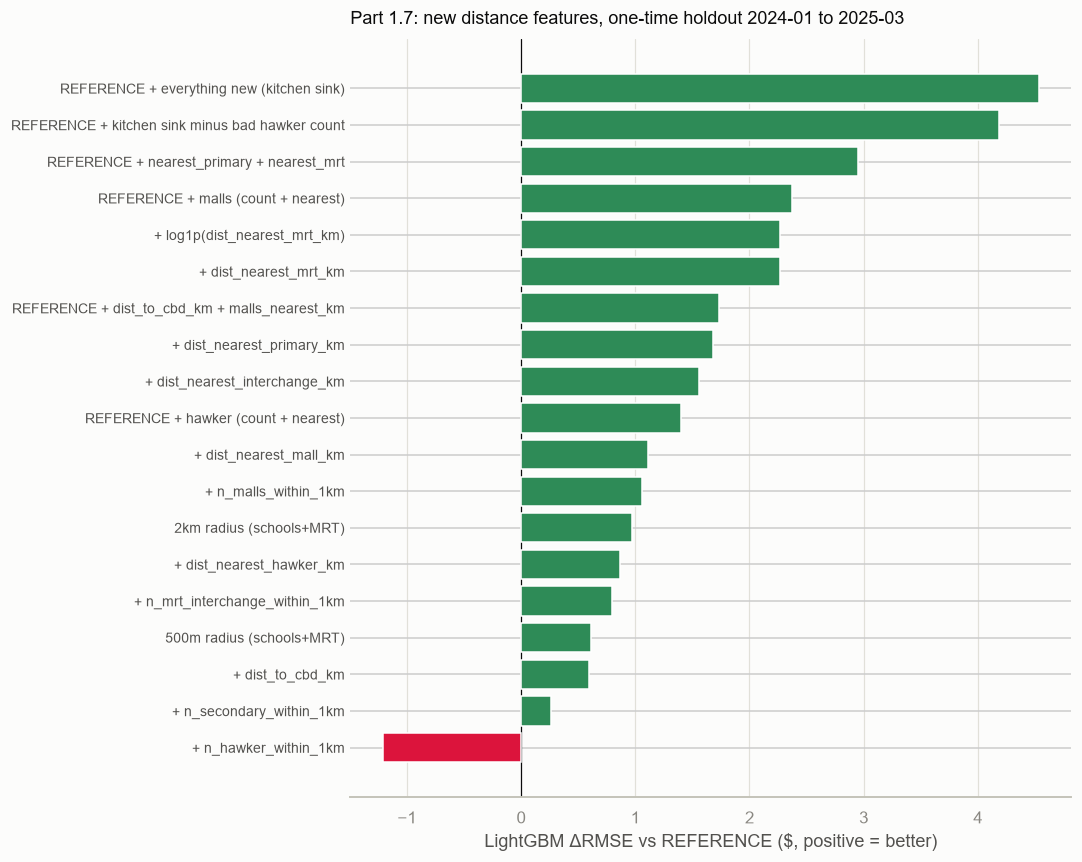

In [177]:
all_results = pd.concat([radius_df.iloc[[0, 2]], singles_df, combos_df], ignore_index=True)
all_results = all_results.sort_values("d_lgb_vs_reference")

fig, ax = plt.subplots(figsize=(10, 8))
fig.patch.set_facecolor(SURFACE); ax.set_facecolor(SURFACE)
ax.barh(all_results["spec"], all_results["d_lgb_vs_reference"],
        color=np.where(all_results["d_lgb_vs_reference"] >= 0, GOOD, BAD), zorder=3)
ax.axvline(0, color=INK, lw=0.8)
ax.set_xlabel("LightGBM ΔRMSE vs REFERENCE ($, positive = better)", color=INK_SECONDARY)
ax.set_title("Part 1.7: new distance features, one-time holdout 2024-01 to 2025-03", color=INK, fontsize=12, loc="left", pad=10)
for s in ["top", "right", "left"]:
    ax.spines[s].set_visible(False)
ax.spines["bottom"].set_color(BASELINE)
ax.tick_params(axis="y", length=0, colors=INK_SECONDARY, labelsize=9)
ax.tick_params(axis="x", colors=INK_MUTED)
ax.xaxis.grid(True, color=GRID, linewidth=0.8, zorder=0)
ax.set_axisbelow(True)
plt.tight_layout()
plt.savefig(FIG_DIR / "part1_7_verdict.png", dpi=150, bbox_inches="tight")
plt.show()

In [178]:
def flag(delta):
    if delta > 0.15:
        return "add"
    if delta < -0.15:
        return "skip"
    return "flat"


all_results["verdict"] = all_results["d_lgb_vs_reference"].map(flag)
holdout_out = pd.concat([radius_df, singles_df, combos_df], ignore_index=True)
holdout_out.to_csv(OUT / "distance_feature_rmse_holdout.csv", index=False)
all_results[["spec", "lgb", "d_lgb_vs_reference", "verdict"]].to_csv(OUT / "distance_feature_rmse_verdict.csv", index=False)
hdb.to_csv(OUT / "hdb_block_distance_features.csv", index=False)
print(f"wrote {OUT / 'distance_feature_rmse_holdout.csv'}, {OUT / 'distance_feature_rmse_verdict.csv'}, "
      f"{OUT / 'hdb_block_distance_features.csv'} ({hdb.shape})")
all_results[["spec", "lgb", "d_lgb_vs_reference", "verdict"]]

wrote ..\outputs\distance_feature_rmse_holdout.csv, ..\outputs\distance_feature_rmse_verdict.csv, ..\outputs\hdb_block_distance_features.csv ((9464, 38))


,spec,lgb,d_lgb_vs_reference,verdict
10,+ n_hawker_within_1km,495.709,-1.208,skip
5,+ n_secondary_within_1km,494.234,0.267,add
12,+ dist_to_cbd_km,493.909,0.592,add
0,500m radius (schools+MRT),493.885,0.615,add
6,+ n_mrt_interchange_within_1km,493.700,0.801,add
11,+ dist_nearest_hawker_km,493.631,0.870,add
1,2km radius (schools+MRT),493.530,0.970,add
8,+ n_malls_within_1km,493.442,1.059,add
9,+ dist_nearest_mall_km,493.385,1.116,add
14,REFERENCE + hawker (count + nearest),493.104,1.397,add


#### 4e. We kept testing everything on the 1 km REFERENCE — does the winning radius change that?

Every "add on top" test above (4b, 4c) still used `REFERENCE` = `n_primary_within_1km` +
`n_mrt_within_1km`, even though 4a showed 2 km beats 1 km for schools/MRT on its own — and the kitchen
sink itself still uses `malls_within_1km` / `hawker_within_1km`, even though the check above found
500 m wins for those two. Three variants: the current 1 km pick, swapping schools/MRT to 2 km, and
swapping schools/MRT to 2 km *and* malls/hawker to 500 m — each amenity at its own best radius.

In [179]:
REFERENCE_2KM = ["MAX_FLOOR", "primary_within_2km", "mrt_within_2km"]
KITCHEN_SINK_EXTRA = [
    "primary_nearest_km", "mrt_nearest_km", "secondary_within_1km", "mrt_interchange_within_1km",
    "mrt_interchange_nearest_km", "malls_within_1km", "malls_nearest_km",
    "hawker_within_1km", "hawker_nearest_km", "dist_to_cbd_km",
]
KITCHEN_SINK_EXTRA_OPT = [
    "primary_nearest_km", "mrt_nearest_km", "secondary_within_1km", "mrt_interchange_within_1km",
    "mrt_interchange_nearest_km", "malls_within_500m", "malls_nearest_km",
    "hawker_within_500m", "hawker_nearest_km", "dist_to_cbd_km",
]
radius_check = pd.DataFrame([
    eval_spec("1km REFERENCE + kitchen sink (current pick)", REFERENCE + KITCHEN_SINK_EXTRA),
    eval_spec("2km REFERENCE + kitchen sink", REFERENCE_2KM + KITCHEN_SINK_EXTRA),
    eval_spec("2km REFERENCE + kitchen sink, malls/hawker @ 500m", REFERENCE_2KM + KITCHEN_SINK_EXTRA_OPT),
])
radius_check["d_lgb_vs_reference"] = reference["lgb"] - radius_check["lgb"]
radius_check[["spec", "lr", "lgb", "d_lgb_vs_reference"]]

,spec,lr,lgb,d_lgb_vs_reference
0,1km REFERENCE + kitchen sink (current pick),652.692,489.968,4.533
1,2km REFERENCE + kitchen sink,652.612,489.576,4.925
2,"2km REFERENCE + kitchen sink, malls/hawker @ 500m",652.630,490.325,4.176


**Giving malls/hawker their own best radius (500 m) makes the full combo *worse*** (+4.18 vs +4.93),
even though 500 m won when malls/hawker were tested in isolation, just alongside REFERENCE. Same lesson
as the hawker-count finding earlier: a radius (or a feature) that wins on its own doesn't always win once
it's interacting with everything else in the kitchen sink. **The best setting found here:
2 km for schools/MRT, 1 km for malls/hawker, everything else stacked on top.**

### 5. Summary & open questions

**Bottom line: switch schools/MRT to 2 km, keep malls/hawker at 1 km, stack everything.** Best combo beats BASE by **+6.79** total
(vs +1.87 from REFERENCE alone in Part 1.6).

- **2 km beats 1 km, for schools and MRT specifically.** Malls/hawker actually prefer 500 m on their
  own, but keeping them at 1 km inside the full combo still beats giving them their own best radius
  (+4.93 vs +4.18), so the recommendation is 2 km for schools/MRT, 1 km for malls/hawker, not "2 km
  for everything."
- **Nearest-distance beats plain counts**: `dist_nearest_mrt_km` alone is the strongest single new feature (+2.27).
- **Malls and CBD distance both help** (+2.37, +0.59).
- **Hawker centres:** count alone hurts (−1.21), but count + nearest-distance together help (+1.40).
- **Stack everything = best result:** +4.53 vs REFERENCE on 1 km, **+4.93 on 2 km** → +6.79 vs BASE overall.

**Caveats:** still one train/val split; malls (113) and hawker centres (123) are sparser than primary schools (179)
and open MRT stations (192); distances are straight-line, not walking.

**Possible extension:** parks / expressway distance, which raise the same "worth sourcing?" question
hawker centres did.

## Part 1.8. Key findings

The findings behind the mid-report, each with its figure. Sections 1-6 are
the problem and what did not fix it; section 7 is what reduced the bias on the holdout. On the leaderboard a forecast level then lost to the frozen one
(Part 2.3, S3 notes), so the level stays a known limitation. Every model score shown
here is either read from `experiments.jsonl` (the shared log) or re-computed
and checked against it, so the numbers here cannot drift from the log.

Scores are RMSE in dollars of monthly rent: 506 means a typical miss of about
$506 a month. Figures are also saved to `reports/figures/` for Overleaf.

In [180]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import hdb_rentals as hr
from hdb_rentals import config
from hdb_rentals.baselines import RAW_FEATURES, model_matrix, score_horizon

# Chart colours: fixed order, so a series keeps its colour in every figure.
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
INK, INK_2, MUTED, GRID, AXIS = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
SURFACE = "#fcfcfb"

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.figsize": (9, 4.2), "figure.dpi": 110,
    "font.family": "sans-serif", "font.size": 10,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "xtick.color": MUTED, "ytick.color": MUTED, "legend.frameon": False,
    "lines.linewidth": 2,
})

def save(fig, name):
    config.FIGURES_DIR.mkdir(parents=True, exist_ok=True)
    fig.savefig(config.FIGURES_DIR / f"{name}.png", dpi=200, bbox_inches="tight")

train = hr.load_train()
log = pd.DataFrame(hr.read_log())
# The log is append-only, so a run can appear more than once; the newest wins.
latest = log.sort_values("timestamp").groupby(["name", "validation"]).tail(1).set_index(["name", "validation"])
monthly = train.groupby("APPROVAL_PERIOD")[config.TARGET].median()
print(f"{len(train):,} training rows, {monthly.index[0]} to {monthly.index[-1]}")

150,000 training rows, 2021-01 to 2025-03


### 1. Rent climbed until mid-2023, then went flat

The test months have no labels, so the model must forecast up to 16 months
past its last training month. A tree model cannot project a trend forward: it
predicts every test month at the March 2025 level (dashed line). That is right
if the flat stretch holds, and costly if the earlier climb comes back (dotted
line).

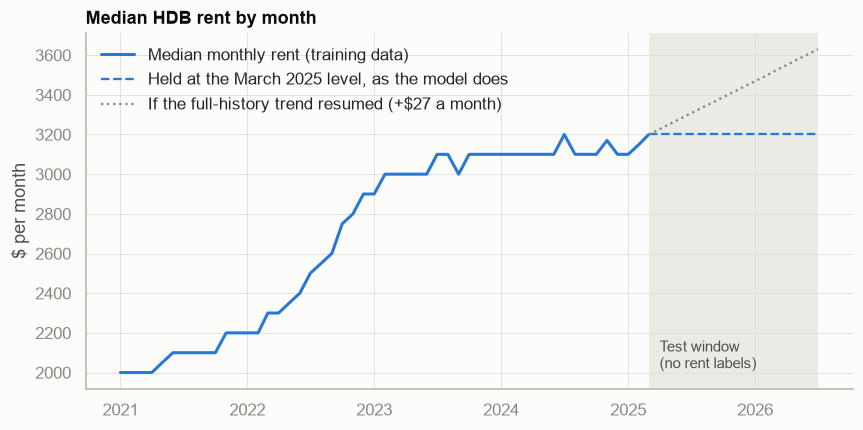

Full-history trend: +$26.9/month. Level in 2025-03: $3,200.


In [181]:
t = monthly.index.to_timestamp()
test_end = pd.Period(config.TEST_PERIOD[1], freq="M").to_timestamp()
future = pd.period_range(monthly.index[-1], config.TEST_PERIOD[1], freq="M").to_timestamp()

# Straight-line trend over every training row -- the same fit behind the
# report's "+$26.7 a month, $427 low" scenario -- restarted from the last level.
slope = np.polyfit(train["MONTH_INDEX"], train[config.TARGET], 1)[0]
last = monthly.iloc[-1]

fig, ax = plt.subplots()
ax.axvspan(future[0], test_end, color=GRID, alpha=0.6, lw=0)
ax.plot(t, monthly.to_numpy(), color=BLUE, label="Median monthly rent (training data)")
ax.plot(future, np.full(len(future), last), color=BLUE, ls="--", lw=1.5,
        label="Held at the March 2025 level, as the model does")
ax.plot(future, last + slope * np.arange(len(future)), color=MUTED, ls=":", lw=1.5,
        label=f"If the full-history trend resumed (+${slope:.0f} a month)")
ax.text(future[1], monthly.min(), "Test window\n(no rent labels)", color=INK_2, va="bottom")
ax.set_title("Median HDB rent by month")
ax.set_ylabel("$ per month")
ax.legend(loc="upper left")
save(fig, "01_rent_trend")
plt.show()
print(f"Full-history trend: +${slope:.1f}/month. Level in {monthly.index[-1]}: ${last:,.0f}.")

### 2. The further out, the more the model under-predicts

One training run on 2021-01..2023-11, scored on the next 16 months: the same
distance as the real test. RMSE falls by about $68, because later months have less
spread, while the under-prediction grows steadily. Watch the bias, not RMSE,
when judging the long horizon.

This cell re-runs the model and checks the result against the logged score.

16-month RMSE 506.18, matches the log (506.18)


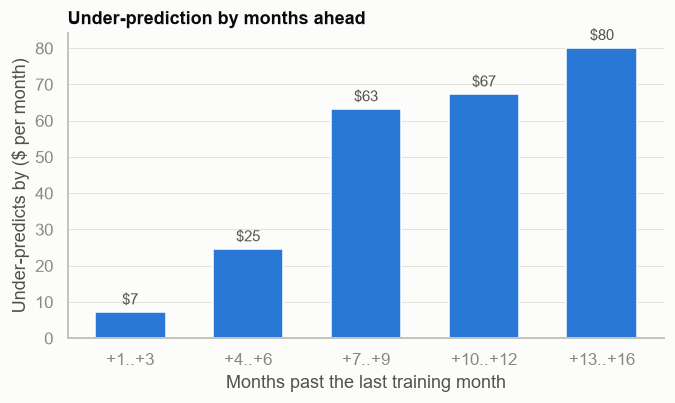

,horizon,n,target_sd,rmse,rmse_over_sd,bias
0,+1..+3,8829,687.600,544.700,0.792,-7.200
1,+4..+6,9347,683.800,526.100,0.769,-24.600
2,+7..+9,9089,682.600,506.200,0.742,-63.200
3,+10..+12,8086,637.600,480.100,0.753,-67.300
4,+13..+16,11820,644.700,476.700,0.740,-80.100


In [182]:
y = train[config.TARGET].to_numpy()
score, report = score_horizon(train, model_matrix(train, RAW_FEATURES), y)
logged = latest.loc[("lgbm-raw", "horizon-matched-16m"), "score"]
assert abs(score - logged) < 0.01, f"re-run {score:.2f} does not match log {logged:.2f}"
print(f"16-month RMSE {score:.2f}, matches the log ({logged:.2f})")

fig, ax = plt.subplots(figsize=(7, 3.6))
under = -report["bias"]
bars = ax.bar(report["horizon"], under, color=BLUE, width=0.6)
ax.bar_label(bars, labels=[f"${v:.0f}" for v in under], padding=3, color=INK_2)
ax.set_title("Under-prediction by months ahead")
ax.set_xlabel("Months past the last training month")
ax.set_ylabel("Under-predicts by ($ per month)")
ax.grid(axis="x", visible=False)
save(fig, "02_horizon_bias")
plt.show()
report

### 3. Which window you score on moves RMSE more than most features will

Five walk-forward rehearsals of the same model. Early 2024 is harder to
predict than late 2024, and that alone swings RMSE by about $82. Compare a new
feature against these five folds one by one, not mean against mean.

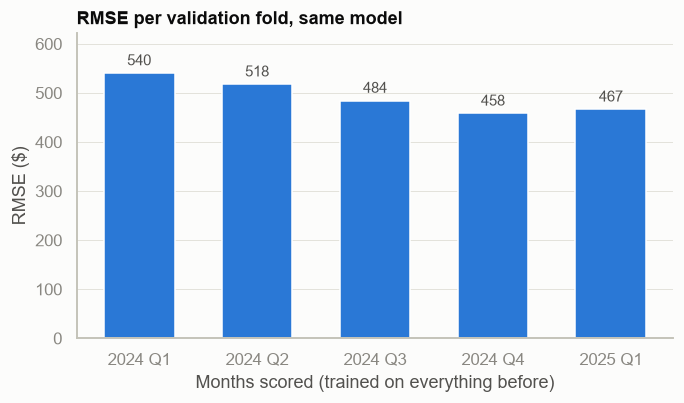

Spread between folds: 82; mean 493.4


In [183]:
folds = latest.loc[("lgbm-raw", "expanding-window-5x3"), "fold_scores"]
labels = ["2024 Q1", "2024 Q2", "2024 Q3", "2024 Q4", "2025 Q1"]

fig, ax = plt.subplots(figsize=(7, 3.6))
bars = ax.bar(labels, folds, color=BLUE, width=0.6)
ax.bar_label(bars, labels=[f"{v:.0f}" for v in folds], padding=3, color=INK_2)
ax.set_ylim(0, max(folds) * 1.15)
ax.set_title("RMSE per validation fold, same model")
ax.set_xlabel("Months scored (trained on everything before)")
ax.set_ylabel("RMSE ($)")
ax.grid(axis="x", visible=False)
save(fig, "03_fold_scores")
plt.show()
print(f"Spread between folds: {max(folds) - min(folds):.0f}; mean {np.mean(folds):.1f}")

### 4. Swapping the month counter for COE or share prices does not help

Same model each time; only the time feature changes. Nothing beats the month
counter by a meaningful margin, and a boat builder's share price (the
placebo, picked for having no link to rent) matches the best macro arm. Any
series that rose with rent in 2021-23 buys that much.

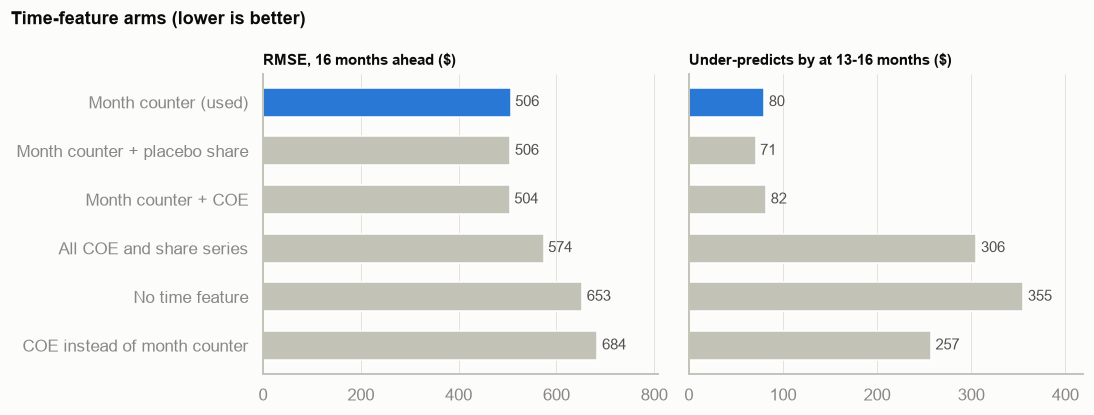

In [184]:
arms = [
    ("lgbm-raw", "Month counter (used)"),
    ("placebo-penguin", "Month counter + placebo share"),
    ("lgbm-macro-plus-time", "Month counter + COE"),
    ("lgbm-macro-ungated", "All COE and share series"),
    ("lgbm-no-time", "No time feature"),
    ("lgbm-macro-only", "COE instead of month counter"),
]
rows = latest.xs("horizon-matched-16m", level="validation").loc[[a for a, _ in arms]]
bias = rows["notes"].str.extract(r"Bias[^:]*:\s*(-?\d+(?:\.\d+)?)")[0].astype(float)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
names = [label for _, label in arms][::-1]
colors = [BLUE if a == "lgbm-raw" else AXIS for a, _ in arms][::-1]
for ax, values, title in [
    (a1, rows["score"].to_numpy()[::-1], "RMSE, 16 months ahead ($)"),
    (a2, -bias.to_numpy()[::-1], "Under-predicts by at 13-16 months ($)"),
]:
    bars = ax.barh(names, values, color=colors, height=0.6)
    ax.bar_label(bars, labels=[f"{v:.0f}" for v in values], padding=3, color=INK_2)
    ax.set_title(title, fontsize=10)
    ax.grid(axis="y", visible=False)
    ax.set_xlim(0, max(values) * 1.18)
fig.suptitle("Time-feature arms (lower is better)", x=0.01, ha="left", fontweight="bold", color=INK)
fig.tight_layout()
save(fig, "04_time_feature_arms")
plt.show()

### 5. Why COE fails: one COE level, two different rents

COE rose with rent until its 2023-10 peak, then fell while rent stayed flat.
So a COE price of about $100k shows up both in the cheap-rent early period and
in the flat, high-rent period, and the model cannot tell which one it is in.

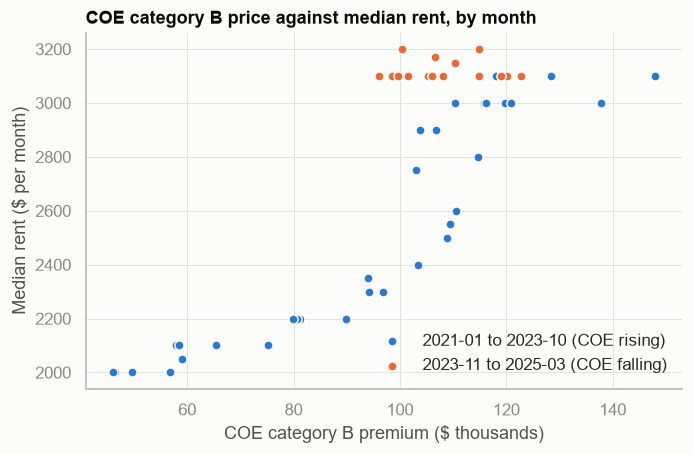

In [185]:
macro = hr.load_macro(gate=False)
coe = macro["COE_B"]
coe.index = pd.period_range("2021-01", periods=len(coe), freq="M")
both = pd.concat([coe.rename("coe"), monthly.rename("rent")], axis=1).dropna()
rising = both.loc[:"2023-10"]
falling = both.loc["2023-11":]

fig, ax = plt.subplots(figsize=(7, 4.2))
ax.scatter(rising["coe"] / 1000, rising["rent"], s=36, color=BLUE,
           edgecolor=SURFACE, lw=1, label="2021-01 to 2023-10 (COE rising)")
ax.scatter(falling["coe"] / 1000, falling["rent"], s=36, color=ORANGE,
           edgecolor=SURFACE, lw=1, label="2023-11 to 2025-03 (COE falling)")
ax.set_title("COE category B price against median rent, by month")
ax.set_xlabel("COE category B premium ($ thousands)")
ax.set_ylabel("Median rent ($ per month)")
ax.legend(loc="lower right")
save(fig, "05_coe_two_regimes")
plt.show()

### 6. Share prices correlate with rent for reasons unrelated to rent

All four series are indexed to 100 in January 2021 so they share one scale.
In 2022 rising interest rates pulled REITs down while the flat shortage pushed
rent up, so REITs look inversely linked to rent. REITs then recover in the test
window, which a model would read as rent falling. Developer and bank shares
climb far past anything seen in training, where a tree model stops responding.
Singapore REITs own offices, malls, warehouses and hotels, not rental flats.
Stock series are not pursued further.

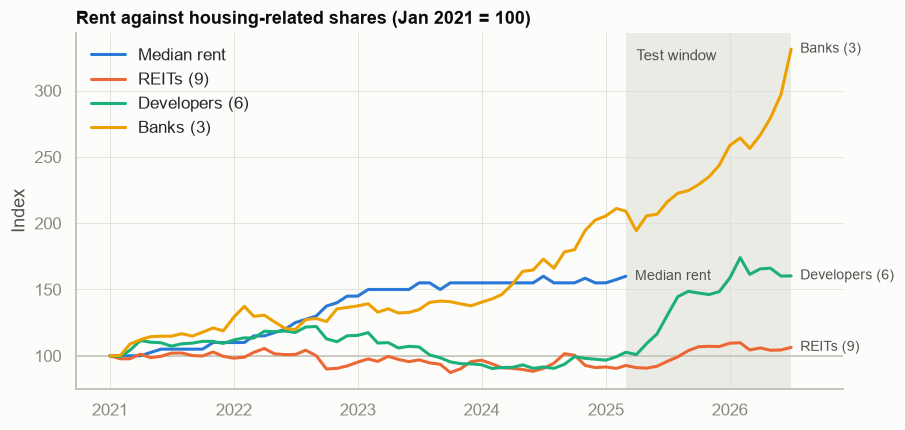

,moves with rent (-1..+1),test months inside training range
REITs (9),-0.690,0.560
Developers (6),-0.560,0.190
Banks (3),0.740,0.190


In [186]:
st = pd.read_csv(config.AUX_CSV["stocks"], parse_dates=["DATE"])
st["period"] = st["DATE"].dt.to_period("M")
px = st.pivot_table(index="period", columns="NAME", values="ADJUSTED_CLOSE", aggfunc="mean")
px = px.loc[config.TRAIN_PERIOD[0]:config.TEST_PERIOD[1]]

groups = {
    "REITs (9)": ["Ascendas Reit", "CapitaLand Ascott Trust", "CapitaLand Mall Trust",
                  "Frasers Logistics & Industrial Trust", "Keppel REIT",
                  "Mapletree Commercial Trust", "Mapletree Industrial Trust",
                  "Mapletree Logistics Trust", "Suntec REIT"],
    "Developers (6)": ["City Developments", "UOL Group", "Singapore Land",
                       "Hotel Properties Limited", "Yanlord",
                       "Pacific Century Regional Developments"],
    "Banks (3)": ["DBS Group", "OCBC Bank", "UOB"],
}
idx = pd.DataFrame({k: (px[v] / px[v].iloc[0] * 100).mean(axis=1) for k, v in groups.items()})
idx.insert(0, "Median rent", monthly / monthly.iloc[0] * 100)

fig, ax = plt.subplots()
ax.axvspan(future[0], test_end, color=GRID, alpha=0.6, lw=0)
ax.axhline(100, color=AXIS, lw=1)
for (name, s), color in zip(idx.items(), [BLUE, ORANGE, AQUA, YELLOW]):
    s = s.dropna()
    ax.plot(s.index.to_timestamp(), s.to_numpy(), color=color, label=name)
    ax.annotate(name, (s.index[-1].to_timestamp(), s.iloc[-1]), xytext=(6, 0),
                textcoords="offset points", va="center", color=INK_2, fontsize=9)
ax.text(future[1], idx.max().max(), "Test window", color=INK_2, va="top")
ax.set_title("Rent against housing-related shares (Jan 2021 = 100)")
ax.set_ylabel("Index")
ax.set_xlim(right=test_end + pd.DateOffset(months=5))
ax.legend(loc="upper left")
save(fig, "06_property_shares")
plt.show()

trn, tst = idx.loc[:config.TRAIN_PERIOD[1]], idx.loc[pd.Period(config.TRAIN_PERIOD[1], "M") + 1:]
pd.DataFrame({
    "moves with rent (-1..+1)": trn.corr()["Median rent"].drop("Median rent").round(2),
    "test months inside training range": (
        (tst >= trn.min()) & (tst <= trn.max())).drop(columns="Median rent").mean().round(2),
})

### 7. Forecasting the market level instead of freezing it

Section 1 showed the problem: the model repeats the March 2025 level for every
test month. The proposed fix splits every rent into two parts that behave differently:

**rent = market level (this month) x premium (this flat)**

- The **market level** is what a typical flat rents for in a given month. One
  number per month, and it is the only part that moves over time.
- The **premium** is how much pricier this particular flat is than a typical
  one. It barely changes over the years, so what the model learns from 2021-23
  still applies in 2025.

The two parts are learned separately, in three steps (`hdb_rentals.market_level`).

#### 7.1 Step 1: the market level, from a regression

One equation is fitted to all 150,000 training rows by ordinary least squares (unlike the index in Part 1.1 §7.1, it has no `STREET` term):

    log(rent) = constant + month effect + town effect + flat type effect
              + flat model effect + b1 x floor area + b2 x flat age

Because town, type, size and age each get their own term, the **month effect**
captures only what is left: how much higher rent is that month than in
January 2021 *for the same kind of flat*. A month where more big flats happened
to rent does not inflate it -- floor area absorbs that.

The equation uses the log of rent so that a month effect is a percentage: an
effect of 0.34 means e^0.34 = 1.40, i.e. rents 40% above January 2021 for every
flat alike. Only the month effects are kept; the rest of the equation is
discarded.

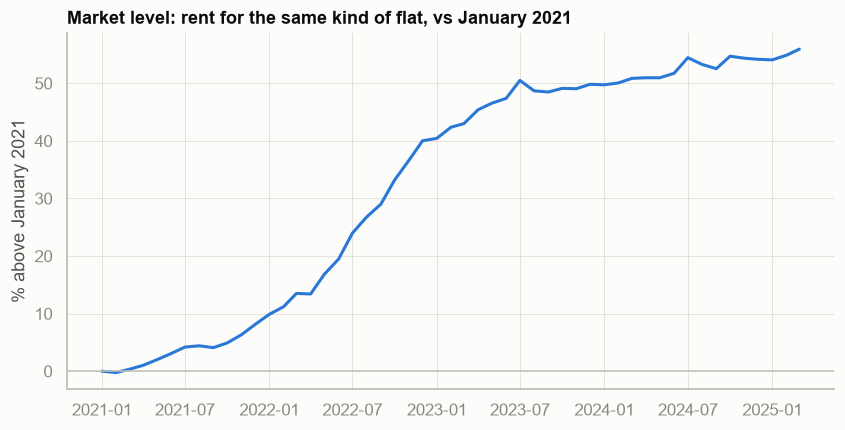

,month,month effect,vs Jan 2021
0,2021-01,0.000,+0.0%
1,2022-01,0.094,+9.9%
2,2023-01,0.340,+40.4%
3,2023-07,0.409,+50.5%
4,2024-01,0.404,+49.7%
5,2025-03,0.444,+55.9%


In [187]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from hdb_rentals.market_level import forecast_level, hedonic_level

def pct(log_level):
    return 100 * (np.exp(log_level) - 1)

level = hedonic_level(train, np.arange(len(train)))
level_t = pd.period_range("2021-01", periods=len(level), freq="M").to_timestamp()

fig, ax = plt.subplots()
ax.plot(level_t, pct(level.to_numpy()), color=BLUE)
ax.axhline(0, color=AXIS, lw=1)
ax.set_title("Market level: rent for the same kind of flat, vs January 2021")
ax.set_ylabel("% above January 2021")
save(fig, "07_market_level")
plt.show()

pd.DataFrame({
    "month": [str(pd.Period("2021-01", "M") + m) for m in [0, 12, 24, 30, 36, 50]],
    "month effect": level.loc[[0, 12, 24, 30, 36, 50]].round(3).to_numpy(),
    "vs Jan 2021": [f"{v:+.1f}%" for v in pct(level.loc[[0, 12, 24, 30, 36, 50]])],
})

#### 7.2 Step 2: the premium, from the tree

Each training rent is divided by its month's market level. That turns it into
**what the flat would have rented for in the January 2021 market**. The tree
(LightGBM) learns to predict this adjusted rent from town, flat type, flat
model, floor area and flat age -- and never sees the month, because the
market's rise has already been taken out.

The table shows why this works. Queenstown 3-room flats rose by over $1,000 a
month in raw rent, but once each month's market level is divided out, the
adjusted rent barely moves. That stable number is what the tree learns.

**To predict:** tree output x forecast market level for that month.

In [188]:
example = train[(train["TOWN"] == "queenstown") & (train["FLAT_TYPE"] == "3-room")]
months = [0, 12, 24, 36, 50]
raw = example.groupby("MONTH_INDEX")[config.TARGET].median().loc[months]
pd.DataFrame({
    "month": [str(pd.Period("2021-01", "M") + m) for m in months],
    "median rent": raw.to_numpy().round(0),
    "market level": np.exp(level.loc[months]).round(3).to_numpy(),
    "adjusted to Jan 2021 market": (raw / np.exp(level.loc[months])).round(0).to_numpy(),
})

,month,median rent,market level,adjusted to Jan 2021 market
0,2021-01,"1,900.000",1.000,"1,900.000"
1,2022-01,"2,200.000",1.099,"2,002.000"
2,2023-01,"2,750.000",1.404,"1,958.000"
3,2024-01,"3,000.000",1.497,"2,003.000"
4,2025-03,"3,000.000",1.559,"1,924.000"


#### 7.3 Step 3: forecasting the level with a damped trend

The month effects form a 51-point series. A damped trend forecasts it using two
running figures, updated month by month:

- **level** -- its smoothed estimate of where the market is now
- **trend** -- its smoothed estimate of how fast the market is moving per month

Each month it compares its forecast with what happened and nudges both figures
toward the actual value. Three settings control how, chosen automatically as
the values that would best have predicted each next month over training:

- **alpha** -- how strongly the level follows the latest month
- **beta** -- how quickly the trend changes its mind
- **phi** -- the damping: each future month's step is phi times the previous
  one, so the forecast bends toward flat instead of rising forever

For comparison, *hold* keeps the level flat, and a *straight line* continues
the average slope of all training months -- which includes the steep 2021-23
climb.

,setting,fitted value
0,alpha (level),0.85
1,beta (trend),0.41
2,phi (damping),0.961
3,trend at 2025-03,+0.37% a month


,months ahead,forecast rise that month
0,1,+0.36%
1,2,+0.34%
2,4,+0.32%
3,8,+0.27%
4,16,+0.20%


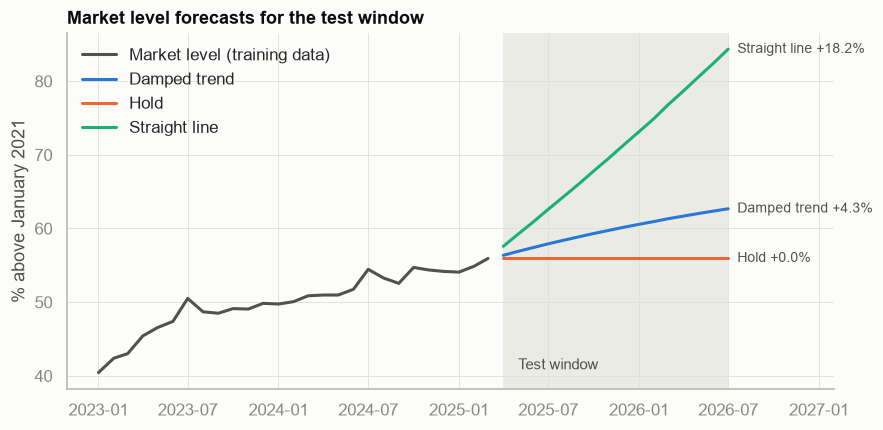

Damped steps add up to at most +9.6% however far out it forecasts.


In [189]:
fit = ExponentialSmoothing(level.to_numpy(), trend="add", damped_trend=True,
                           initialization_method="estimated").fit()
alpha, beta, phi = (fit.params[k] for k in ("smoothing_level", "smoothing_trend", "damping_trend"))
trend_now = fit.trend[-1]
steps = np.diff(np.r_[fit.level[-1], fit.forecast(16)])

display(pd.DataFrame({
    "setting": ["alpha (level)", "beta (trend)", "phi (damping)", "trend at 2025-03"],
    "fitted value": [f"{alpha:.2f}", f"{beta:.2f}", f"{phi:.3f}", f"{pct(trend_now):+.2f}% a month"],
}))
display(pd.DataFrame({
    "months ahead": [1, 2, 4, 8, 16],
    "forecast rise that month": [f"{pct(steps[h - 1]):+.2f}%" for h in [1, 2, 4, 8, 16]],
}))

test_months = np.arange(len(level), len(level) + 16)
ahead_t = pd.period_range("2025-04", periods=16, freq="M").to_timestamp()
recent = level.loc[24:]

fig, ax = plt.subplots()
ax.axvspan(ahead_t[0], ahead_t[-1], color=GRID, alpha=0.6, lw=0)
ax.plot(level_t[24:], pct(recent.to_numpy()), color=INK_2, label="Market level (training data)")
for method, color, label in [("damped", BLUE, "Damped trend"), ("hold", ORANGE, "Hold"),
                             ("linear", AQUA, "Straight line")]:
    f = forecast_level(level, test_months, method).loc[test_months]
    ax.plot(ahead_t, pct(f.to_numpy()), color=color, label=label)
    ax.annotate(f"{label} {pct(f.iloc[-1] - level.iloc[-1]):+.1f}%", (ahead_t[-1], pct(f.iloc[-1])),
                xytext=(6, 0), textcoords="offset points", va="center", color=INK_2, fontsize=9)
ax.text(ahead_t[1], pct(recent.min()), "Test window", color=INK_2, va="bottom")
ax.set_title("Market level forecasts for the test window")
ax.set_ylabel("% above January 2021")
ax.set_xlim(right=ahead_t[-1] + pd.DateOffset(months=7))
ax.legend(loc="upper left")
save(fig, "08_level_forecasts")
plt.show()
print(f"Damped steps add up to at most {pct(trend_now * phi / (1 - phi)):+.1f}% however far out it forecasts.")

#### 7.4 Does it work? Two forecast origins

Each arm is scored on a 16-month fold, the same distance as the real test, from
two starting points with opposite market conditions:

- **flat origin:** train to 2023-11, score 2023-12 to 2025-03 (market flat)
- **climb origin:** train to 2022-06, score 2022-07 to 2023-10 (market climbing)

The figure shows the climb origin: each method's level forecast from June 2022
against the level that actually happened.

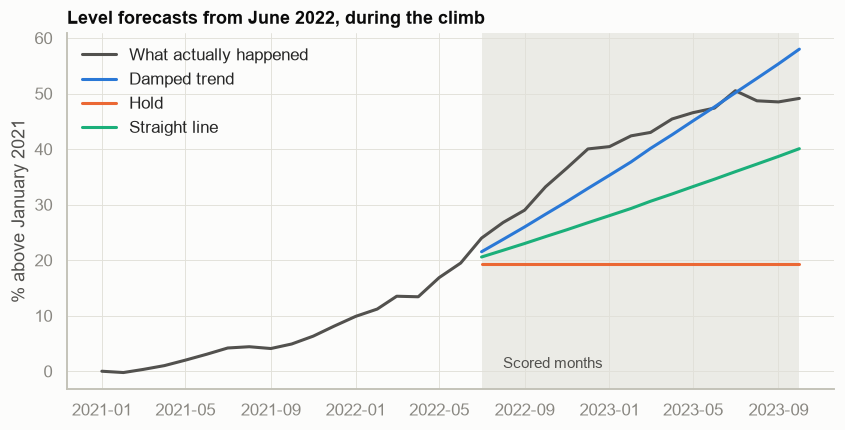

In [190]:
climb = train[train["MONTH_INDEX"] <= 33].reset_index(drop=True)
climb_trn = np.flatnonzero(climb["MONTH_INDEX"] <= 17)
fitted = hedonic_level(climb, climb_trn)
future_m = np.arange(18, 34)
future_t = pd.period_range("2022-07", periods=16, freq="M").to_timestamp()

fig, ax = plt.subplots()
ax.axvspan(future_t[0], future_t[-1], color=GRID, alpha=0.6, lw=0)
ax.plot(level_t[:34], pct(level.loc[:33].to_numpy()), color=INK_2, label="What actually happened")
for method, color, label in [("damped", BLUE, "Damped trend"), ("hold", ORANGE, "Hold"),
                             ("linear", AQUA, "Straight line")]:
    f = forecast_level(fitted, future_m, method).loc[future_m]
    ax.plot(future_t, pct(f.to_numpy()), color=color, label=label)
ax.text(future_t[1], 0, "Scored months", color=INK_2, va="bottom")
ax.set_title("Level forecasts from June 2022, during the climb")
ax.set_ylabel("% above January 2021")
ax.legend(loc="upper left")
save(fig, "09_climb_origin")
plt.show()

#### 7.5 Scores at both origins

Every arm uses the same tree for the premium; they differ only in the level.
The **oracle** uses the actual level of the scored months -- it cheats, so it is
not usable, but it shows how good the model would be with a perfect level
forecast. It still has error because RMSE scores each flat, and two flats the
tree cannot tell apart can rent hundreds of dollars apart.

So each arm's RMSE reads as **oracle + the cost of getting the level wrong**.
When the market is flat, level mistakes barely matter. When it climbs, holding
flat costs about $180 of RMSE and the damped trend cuts that to about $9. Its
weak spot shows at the end of the climb window: it overshoots by about $87
while its trend figure catches up with the mid-2023 flattening.

Scores are read from `experiments.jsonl`. The two origins score different
months, so compare arms within a column, not across.

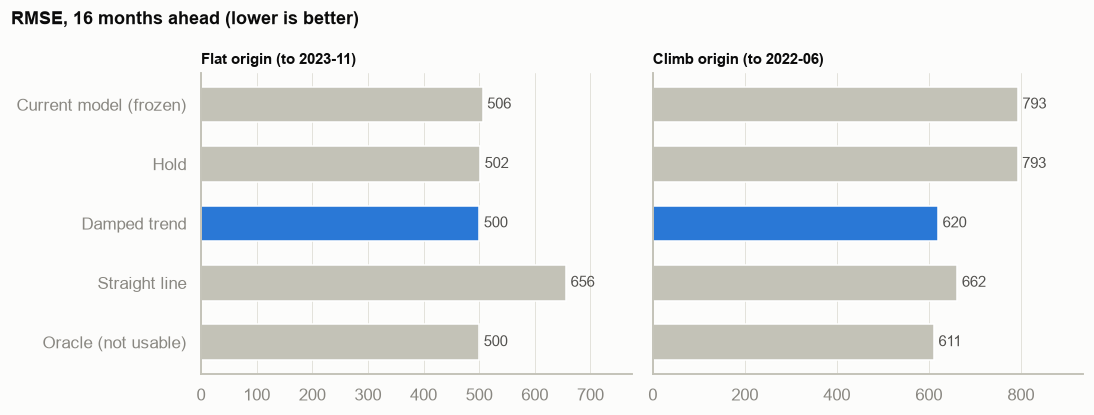

Flat origin (to 2023-11)                                  Climb origin (to 2022-06)                                 
                                           RMSE over oracle bias at 13-16 months                      RMSE over oracle bias at 13-16 months
name                                                                                                                                       
Current model (frozen)                  506.180       6.300              -80.100                   793.340     182.300             -619.600
Hold                                    501.550       1.700              -73.900                   792.790     181.800             -624.200
Damped trend                            500.110       0.200              -49.900                   620.010       9.000               86.500
Straight line                           656.200     156.300              651.800                   661.910      50.900             -242.500
Oracle (not usable)                     499.900       0.000               41.200                   610.990       0.000              -12.500

In [191]:
origins = {"Flat origin (to 2023-11)": "horizon-matched-16m",
           "Climb origin (to 2022-06)": "horizon-16m-origin-2022-06"}
arm_labels = {"lgbm-raw": "Current model (frozen)", "level-hold": "Hold",
              "level-damped": "Damped trend", "level-linear": "Straight line",
              "level-oracle": "Oracle (not usable)"}

table = {}
for title, validation in origins.items():
    rows = latest.xs(validation, level="validation").loc[list(arm_labels)]
    oracle = rows.loc["level-oracle", "score"]
    table[(title, "RMSE")] = rows["score"].round(2)
    table[(title, "over oracle")] = (rows["score"] - oracle).round(1)
    table[(title, "bias at 13-16 months")] = (
        rows["notes"].str.extract(r"Bias[^:]*:\s*(-?\d+(?:\.\d+)?)")[0].astype(float))
scores = pd.DataFrame(table).rename(index=arm_labels)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
names = list(arm_labels.values())[::-1]
colors = [BLUE if n == "Damped trend" else AXIS for n in names]
for ax, title in zip(axes, origins):
    values = scores.loc[names, (title, "RMSE")].to_numpy()
    bars = ax.barh(names, values, color=colors, height=0.6)
    ax.bar_label(bars, labels=[f"{v:.0f}" for v in values], padding=3, color=INK_2)
    ax.set_title(title, fontsize=10)
    ax.set_xlim(0, max(values) * 1.18)
    ax.grid(axis="y", visible=False)
fig.suptitle("RMSE, 16 months ahead (lower is better)", x=0.01, ha="left",
             fontweight="bold", color=INK)
fig.tight_layout()
save(fig, "10_level_arms")
plt.show()
scores